# Turbofan simulation analysis

Run three C++ cases, plot the thermodynamic paths, and compare selected observations from NASA TM 84903. The final sections reproduce selected numerical curves and preserve the numbered figures from NASA TM-86040 and TM X-3261. The station plots and transient use the synthetic reference engine. The PW-100 comparison labels the flight points, historical deck, and synthetic pressure-ratio proxy separately.

Build the simulator first, then select **Restart Kernel and Run All Cells**. See the [notebook guide](../docs/notebook-analysis.md) for installation and the commands behind each plot.

In [1]:
import os
import subprocess
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

%matplotlib inline

cwd = Path.cwd()
ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "include" / "turbofan" / "cycle.hpp").is_file()
     and (path / "CMakeLists.txt").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open the notebook from within the simulator checkout.")

# Edit these tuples to use custom cases, maps, or a control profile.
DRY_COMMAND = ("design",)
WET_COMMAND = ("wet",)
TRANSIENT_COMMAND = ("controlled",)
TRACE_STATION = "nozzle_inlet"

def repo_path(path):
    resolved = Path(path).expanduser()
    return resolved if resolved.is_absolute() else ROOT / resolved

CLI = repo_path(os.environ.get("TURBOFAN_CLI", "build/turbofan-cli"))
OUTPUT = repo_path(os.environ.get("TURBOFAN_ANALYSIS_DIR", "build/analysis"))
if not CLI.is_file() or not os.access(CLI, os.X_OK):
    raise FileNotFoundError(
        f"Executable not found at {CLI}. Build with CMake or set TURBOFAN_CLI."
    )
OUTPUT.mkdir(parents=True, exist_ok=True)

DRY_COLOR = "#23628B"
WET_COLOR = "#B54C1E"
DECK_COLOR = "#58616E"
plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.fonttype": "none",
    "figure.facecolor": "white",
})

def run_csv(stem, command, required_columns):
    args = [str(CLI), *command]
    completed = subprocess.run(args, cwd=ROOT, capture_output=True, text=True)
    (OUTPUT / f"{stem}.log").write_text(completed.stderr, encoding="utf-8")
    if completed.returncode != 0:
        raise RuntimeError(f"{' '.join(args)} exited with status {completed.returncode}\n{completed.stderr}")
    frame = pd.read_csv(StringIO(completed.stdout))
    missing = set(required_columns) - set(frame)
    if missing or frame.empty:
        raise ValueError(f"{stem} produced no usable rows or is missing {sorted(missing)}.")
    (OUTPUT / f"{stem}.csv").write_text(completed.stdout, encoding="utf-8")
    return frame

def show_and_export(figure, name):
    for extension in ("png", "svg"):
        figure.savefig(OUTPUT / f"{name}.{extension}", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(figure)

## 1. Station states with and without reheat

Each row is a model station. The bypass outlet is a separate flow branch. The default wet and dry cases use different throat areas, so their overall differences also include the geometry change. The change from mixer outlet to nozzle inlet within the wet case shows the effect of reheat directly.

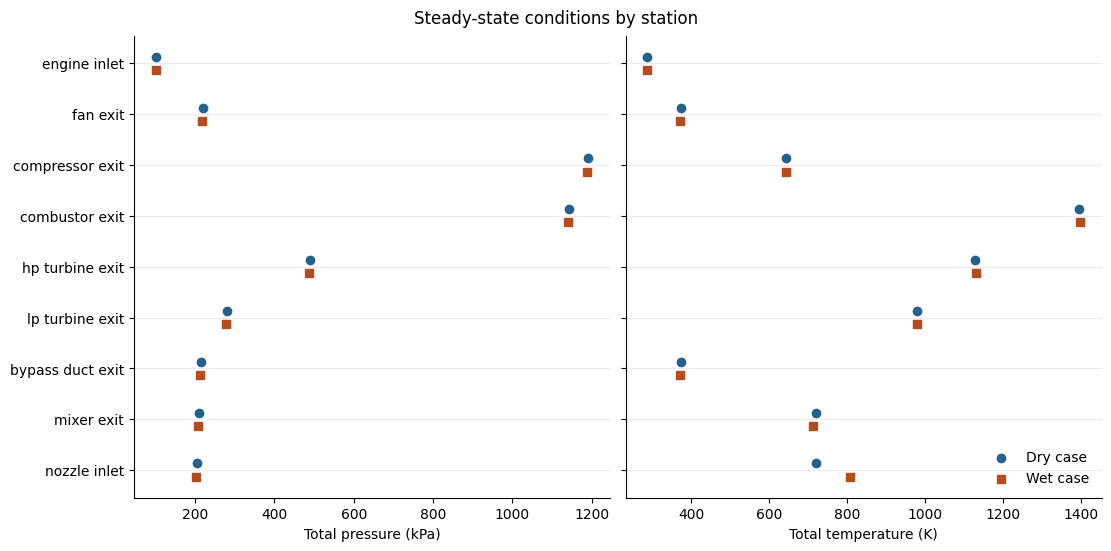

,Total temperature (K),Total pressure (kPa),Gas flow (kg/s)
station,,,
mixer_exit,712.39,207.78,92.77
nozzle_inlet,806.90,202.17,92.99


In [2]:
station_columns = ("station", "pt_pa", "tt_k", "flow_kg_s", "h_total_j_kg", "fuel_air_ratio")
dry = run_csv("dry", DRY_COMMAND, station_columns).set_index("station", verify_integrity=True)
wet = run_csv("wet", WET_COMMAND, station_columns).set_index("station", verify_integrity=True)
if set(dry.index) != set(wet.index):
    raise ValueError("Dry and wet results must report the same station names.")
wet = wet.reindex(dry.index)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True, layout="constrained")
positions = list(range(len(dry)))
for axis, column, scale, label in (
    (axes[0], "pt_pa", 1e-3, "Total pressure (kPa)"),
    (axes[1], "tt_k", 1.0, "Total temperature (K)"),
):
    for frame, offset, marker, color, name in (
        (dry, -0.13, "o", DRY_COLOR, "Dry case"),
        (wet, 0.13, "s", WET_COLOR, "Wet case"),
    ):
        axis.scatter(frame[column] * scale, [index + offset for index in positions],
                     marker=marker, s=36, color=color, label=name, zorder=3)
    axis.set_xlabel(label)
    axis.grid(axis="y", alpha=0.25)
axes[0].set_yticks(positions, [name.replace("_", " ") for name in dry.index])
axes[0].invert_yaxis()
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Steady-state conditions by station")
show_and_export(fig, "station_states")

reheat = wet.loc[["mixer_exit", "nozzle_inlet"], ["tt_k", "pt_pa", "flow_kg_s"]].copy()
reheat["pt_pa"] *= 1e-3
reheat.columns = ["Total temperature (K)", "Total pressure (kPa)", "Gas flow (kg/s)"]
display(reheat.round(2))

## 2. Thermodynamic paths and ideal Brayton reference

The simulated engine is an **open** cycle with a core, bypass, and mixer. The plotted connections guide the eye between discrete states. The local process and composition between planes are outside the current model. The perfect-gas post-processing obtains the constant (c_p) from the exported (h_t/T_t) and uses (R = 287.05 mathrm{J/(kg K)}), as in the C++ model.

Use the dry inlet as a common entropy reference. Plot (s-s_{mathrm{ref}}=c_pln(T_t/T_{t,mathrm{ref}})-Rln(P_t/P_{t,mathrm{ref}})) and (v_t=RT_t/P_t). The latter is the specific volume of the hypothetical stagnation state. The paths end at the nozzle inlet because the station CSV carries total states. Mixing and heat addition use the model's constant-property approximation.

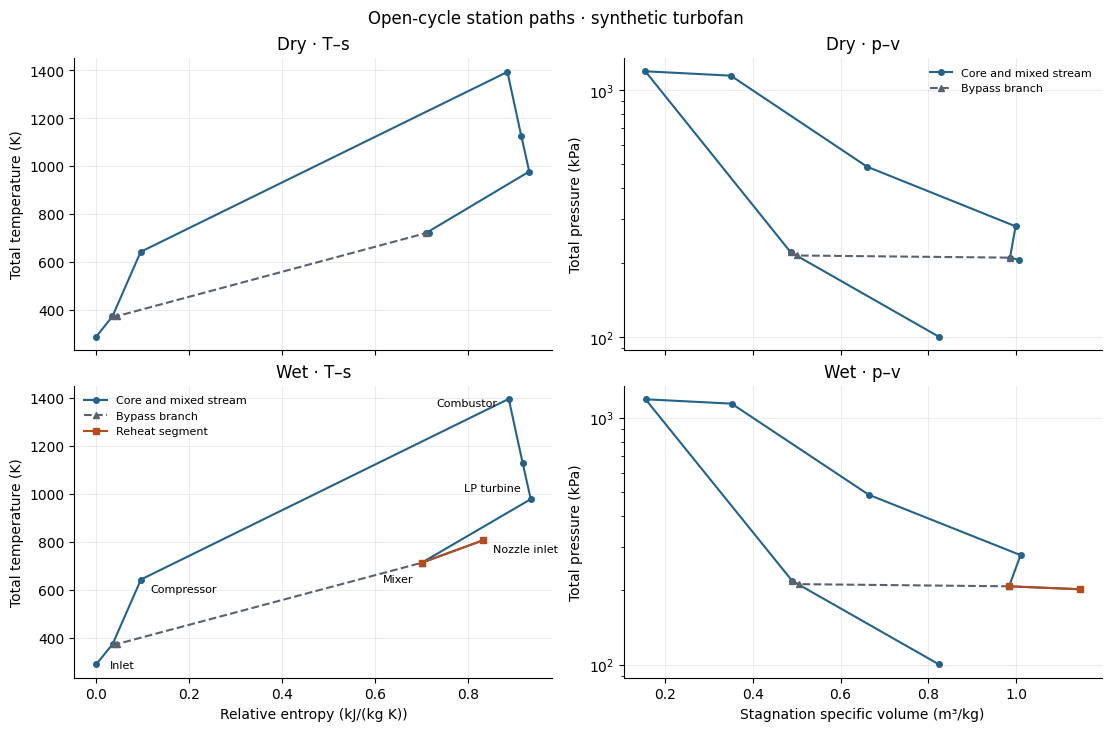

In [3]:
gas_constant = 287.05  # J/(kg K), matches include/turbofan/thermo.hpp
inlet_temperature = dry.at["engine_inlet", "tt_k"]
inlet_pressure = dry.at["engine_inlet", "pt_pa"]
cp = dry.at["engine_inlet", "h_total_j_kg"] / inlet_temperature

def thermo_coordinates(frame):
    if not np.allclose(frame["h_total_j_kg"] / frame["tt_k"], cp, rtol=1e-8, atol=0):
        raise ValueError("The entropy plot requires a common constant heat capacity.")
    states = frame[["tt_k", "pt_pa", "flow_kg_s", "h_total_j_kg"]].copy()
    states["relative_entropy_kj_kg_k"] = (
        cp * np.log(states["tt_k"] / inlet_temperature)
        - gas_constant * np.log(states["pt_pa"] / inlet_pressure)
    ) / 1000
    states["stagnation_volume_m3_kg"] = gas_constant * states["tt_k"] / states["pt_pa"]
    return states

dry_thermo = thermo_coordinates(dry)
wet_thermo = thermo_coordinates(wet)
pd.concat({"dry": dry_thermo, "wet": wet_thermo}, names=["case"]).to_csv(
    OUTPUT / "thermodynamic_states.csv"
)

core_route = [
    "engine_inlet", "fan_exit", "compressor_exit", "combustor_exit",
    "hp_turbine_exit", "lp_turbine_exit", "mixer_exit", "nozzle_inlet",
]
bypass_route = ["fan_exit", "bypass_duct_exit", "mixer_exit"]
axes_specs = (
    ("relative_entropy_kj_kg_k", "tt_k", 1, "Relative entropy (kJ/(kg K))", "Total temperature (K)"),
    ("stagnation_volume_m3_kg", "pt_pa", 1e-3, "Stagnation specific volume (m³/kg)", "Total pressure (kPa)"),
)
fig, axes = plt.subplots(2, 2, figsize=(11, 7.2), sharex="col", sharey="col", layout="constrained")
for row, (frame, label) in enumerate(((dry_thermo, "Dry"), (wet_thermo, "Wet"))):
    for col, (x, y, scale, xlabel, ylabel) in enumerate(axes_specs):
        ax = axes[row, col]
        for route, color, style, name in (
            (core_route, DRY_COLOR, "-o", "Core and mixed stream"),
            (bypass_route, DECK_COLOR, "--^", "Bypass branch"),
        ):
            points = frame.loc[route]
            ax.plot(points[x], points[y] * scale, style, color=color, ms=4, label=name)
        if row == 1:
            points = frame.loc[["mixer_exit", "nozzle_inlet"]]
            ax.plot(points[x], points[y] * scale, "-s", color=WET_COLOR,
                    ms=5, label="Reheat segment", zorder=4)
        ax.grid(alpha=0.23)
        ax.set_title(f"{label} · {'T–s' if col == 0 else 'p–v'}")
        ax.set_ylabel(ylabel)
        if row == 1:
            ax.set_xlabel(xlabel)
    axes[row, 1].set_yscale("log")
ts_wet = axes[1, 0]
for station, label, offset, alignment in (
    ("engine_inlet", "Inlet", (10, -3), "left"),
    ("compressor_exit", "Compressor", (7, -9), "left"),
    ("combustor_exit", "Combustor", (-8, -5), "right"),
    ("lp_turbine_exit", "LP turbine", (-7, 6), "right"),
    ("mixer_exit", "Mixer", (-6, -14), "right"),
    ("nozzle_inlet", "Nozzle inlet", (7, -9), "left"),
):
    point = wet_thermo.loc[station]
    ts_wet.annotate(
        label, (point["relative_entropy_kj_kg_k"], point["tt_k"]),
        xytext=offset, textcoords="offset points", ha=alignment, fontsize=8,
    )
axes[0, 1].legend(frameon=False, fontsize=8)
axes[1, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Open-cycle station paths · synthetic turbofan")
show_and_export(fig, "open_cycle_thermodynamics")

### Air-standard Brayton reference

This ideal cycle uses the dry run's inlet state, overall compression ratio, and combustor exit temperature as anchors. It has reversible adiabatic compression and expansion, plus isobaric heating and rejection. The heat-rejection leg closes this reference cycle. Bypass, reheat, losses, mixing, and fuel mass addition belong to the open-cycle model above.

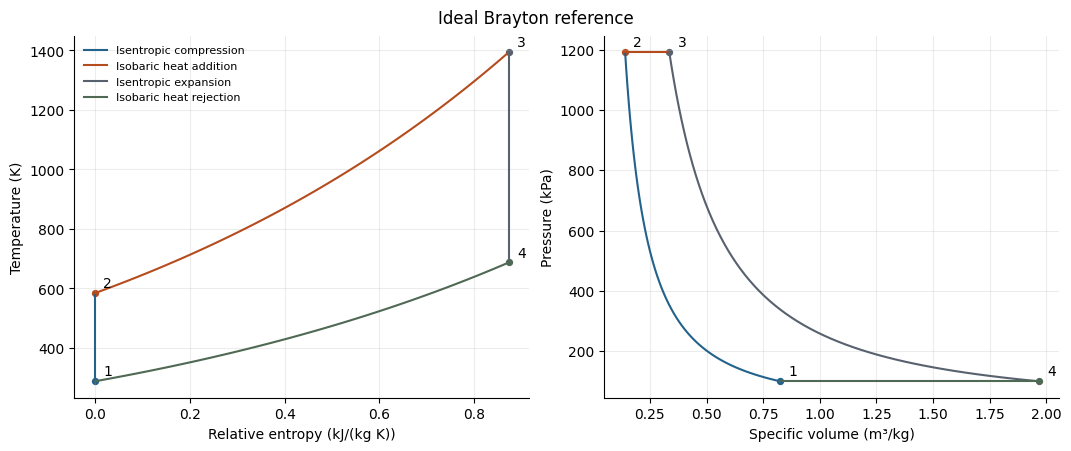

In [4]:
pressure_ratio = dry.at["compressor_exit", "pt_pa"] / inlet_pressure
exponent = gas_constant / cp
p_low = inlet_pressure
p_high = p_low * pressure_ratio
t_cold = inlet_temperature
t_compressed = t_cold * pressure_ratio ** exponent
t_firing = dry.at["combustor_exit", "tt_k"]
t_expanded = t_firing / pressure_ratio ** exponent
if pressure_ratio <= 1 or t_firing <= t_compressed:
    raise ValueError("The dry anchors must support positive compression and heat addition.")

n = 60
p_up = np.geomspace(p_low, p_high, n)
p_down = np.geomspace(p_high, p_low, n)
legs = (
    ("Isentropic compression", p_up, t_cold * (p_up / p_low) ** exponent),
    ("Isobaric heat addition", np.full(n, p_high), np.linspace(t_compressed, t_firing, n)),
    ("Isentropic expansion", p_down, t_firing * (p_down / p_high) ** exponent),
    ("Isobaric heat rejection", np.full(n, p_low), np.linspace(t_expanded, t_cold, n)),
)
fig, (ts, pv) = plt.subplots(1, 2, figsize=(10.6, 4.4), layout="constrained")
ideal_rows = []
for i, ((label, pressure, temperature), color) in enumerate(
    zip(legs, (DRY_COLOR, WET_COLOR, DECK_COLOR, "#4F6954")), start=1
):
    entropy = (cp * np.log(temperature / t_cold)
               - gas_constant * np.log(pressure / p_low)) / 1000
    volume = gas_constant * temperature / pressure
    ideal_rows.append(pd.DataFrame({
        "process": label, "pressure_pa": pressure, "temperature_k": temperature,
        "relative_entropy_kj_kg_k": entropy, "specific_volume_m3_kg": volume,
    }))
    ts.plot(entropy, temperature, color=color, label=label)
    pv.plot(volume, pressure / 1000, color=color, label=label)
    for ax, x, y in ((ts, entropy, temperature), (pv, volume, pressure / 1000)):
        ax.scatter(x[0], y[0], s=18, color=color)
        ax.annotate(str(i), (x[0], y[0]), xytext=(6, 4), textcoords="offset points")
ts.set(xlabel="Relative entropy (kJ/(kg K))", ylabel="Temperature (K)")
pv.set(xlabel="Specific volume (m³/kg)", ylabel="Pressure (kPa)")
ts.legend(frameon=False, fontsize=8)
for ax in (ts, pv):
    ax.grid(alpha=0.23)
fig.suptitle("Ideal Brayton reference")
pd.concat(ideal_rows, ignore_index=True).to_csv(OUTPUT / "ideal_brayton.csv", index=False)
show_and_export(fig, "ideal_brayton")

## 3. Controlled response

The built-in dry demo steps normalized throttle from 0.50 to 0.75 at 0.10 s. The CSV contains one row per station at every time. Select one station to get a single time series, and show rotor-speed changes relative to trim so that the response of both shafts is visible.

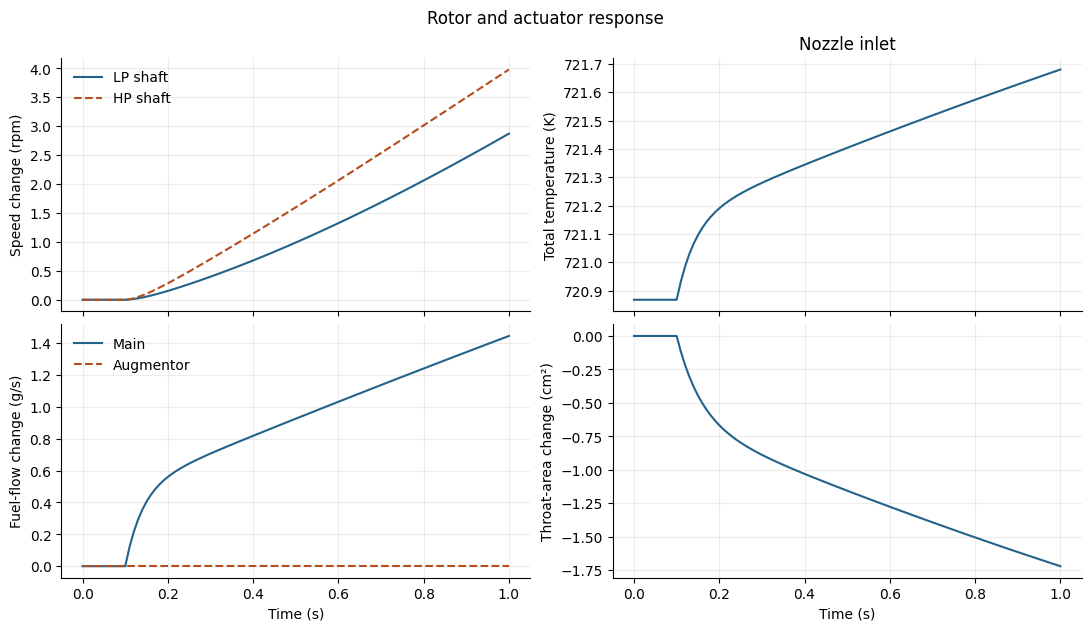

In [5]:
trace_columns = (
    "time_s", "station", "lp_rpm", "hp_rpm", "tt_k", "main_fuel_kg_s",
    "augmentor_fuel_kg_s", "throat_m2",
)
trajectory = run_csv("transient", TRANSIENT_COMMAND, trace_columns)
trace = trajectory.loc[trajectory["station"] == TRACE_STATION].sort_values("time_s")
if trace.empty or trace["time_s"].duplicated().any():
    raise ValueError(f"Expected one row per time for station {TRACE_STATION!r}.")
time = trace["time_s"]
initial = trace.iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(10.8, 6.2), sharex=True, layout="constrained")
shaft, temperature, fuel, throat = axes.flat
shaft.plot(time, trace["lp_rpm"] - initial["lp_rpm"], color=DRY_COLOR, label="LP shaft")
shaft.plot(time, trace["hp_rpm"] - initial["hp_rpm"], color=WET_COLOR,
           linestyle="--", label="HP shaft")
shaft.set_ylabel("Speed change (rpm)")
temperature.plot(time, trace["tt_k"], color=DRY_COLOR)
temperature.set_ylabel("Total temperature (K)")
temperature.set_title(TRACE_STATION.replace("_", " ").capitalize())
fuel.plot(time, (trace["main_fuel_kg_s"] - initial["main_fuel_kg_s"]) * 1000,
          color=DRY_COLOR, label="Main")
fuel.plot(time, (trace["augmentor_fuel_kg_s"] - initial["augmentor_fuel_kg_s"]) * 1000,
          color=WET_COLOR, linestyle="--", label="Augmentor")
fuel.set_ylabel("Fuel-flow change (g/s)")
throat.plot(time, (trace["throat_m2"] - initial["throat_m2"]) * 10000, color=DRY_COLOR)
throat.set_ylabel("Throat-area change (cm²)")
for axis in axes.flat:
    axis.grid(alpha=0.24)
for axis in (fuel, throat):
    axis.set_xlabel("Time (s)")
shaft.legend(frameon=False)
fuel.legend(frameon=False)
fig.suptitle("Rotor and actuator response")
show_and_export(fig, "transient_response")

## 4. Comparison with public PW-100 observations

The chart compares selected NASA flight markers and historical deck values with the simulator's synthetic EPR proxy. The error bars on the flight markers show estimated graph-reading uncertainty, rather than instrumentation uncertainty or a model prediction interval. See the [source and method](../docs/pw100-public-comparison.md).

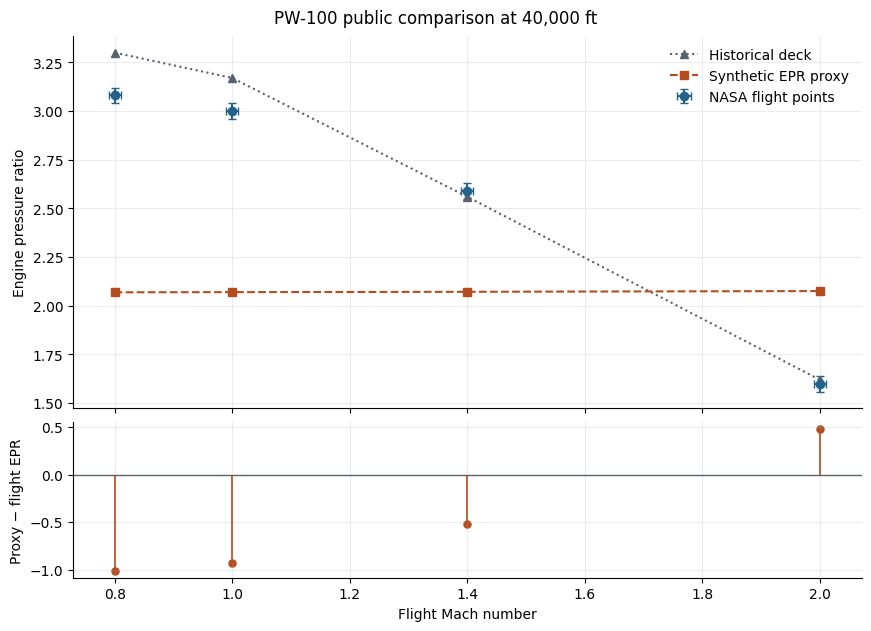

Exported the public comparison data and figure.


In [6]:
columns = ("mach", "flight_epr", "deck_epr", "surrogate_epr_proxy", "proxy_minus_flight_epr")
comparison = run_csv("comparison", ("compare-pw100",), columns).sort_values("mach")

fig, (epr, residual) = plt.subplots(
    2, 1, figsize=(8.6, 6.2), sharex=True, layout="constrained",
    gridspec_kw={"height_ratios": (2.4, 1.0)},
)
mach = comparison["mach"]
epr.errorbar(mach, comparison["flight_epr"], xerr=0.01, yerr=0.04,
             fmt="o", capsize=3, color=DRY_COLOR, label="NASA flight points")
epr.plot(mach, comparison["deck_epr"], color=DECK_COLOR, linestyle=":",
         marker="^", label="Historical deck")
epr.plot(mach, comparison["surrogate_epr_proxy"], color=WET_COLOR, linestyle="--",
         marker="s", label="Synthetic EPR proxy")
epr.set_ylabel("Engine pressure ratio")
epr.legend(frameon=False)
residual.axhline(0, color=DECK_COLOR, linewidth=1)
residual.vlines(mach, 0, comparison["proxy_minus_flight_epr"], color=WET_COLOR, linewidth=1.2)
residual.scatter(mach, comparison["proxy_minus_flight_epr"], color=WET_COLOR, s=26)
residual.set_ylabel("Proxy − flight EPR")
residual.set_xlabel("Flight Mach number")
for axis in (epr, residual):
    axis.grid(alpha=0.24)
fig.suptitle("PW-100 public comparison at 40,000 ft")
show_and_export(fig, "pw100_epr_comparison")

print("Exported the public comparison data and figure.")

## 5. Redrawn historical plots

The first panel set samples Figures 7–8 of NASA TM-86040. These are PW-1128 EMD deck results at two distinct conditions. The markers and guides are approximate readings from the published curves. The reading tolerances are about ±0.01 EPR, ±0.02 ft², ±1 percentage point of margin, and ±50 lbf. The FTIT panes and other original figures remain available below.

The second plot evaluates the piecewise nozzle throat area correction in NASA TM X-3261, Appendix B, Equation (B46), in physical units. Figure 23 instead shows the underlying trend in normalized units. This historical empirical correction is plotted for reference and is independent of the C++ nozzle model. [HIDEC source](https://ntrs.nasa.gov/citations/19840016519) · [Hybrid simulation source](https://ntrs.nasa.gov/citations/19750019996)

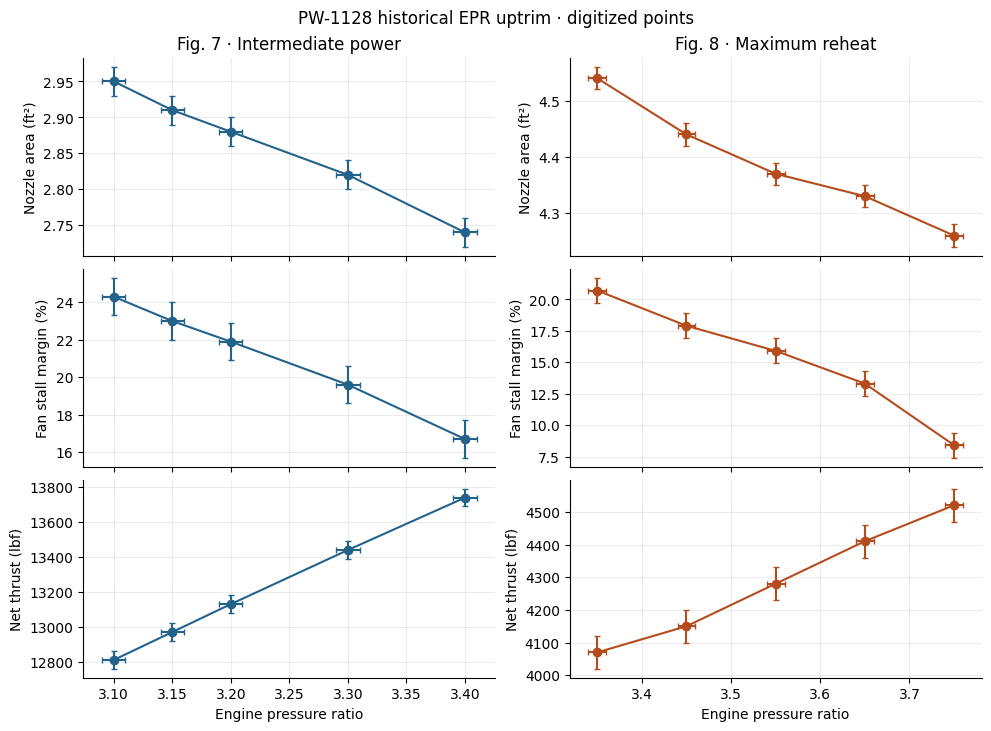

In [7]:
columns = ["epr", "nozzle_area_ft2", "fan_stall_margin_pct", "net_thrust_lbf"]
hidec = {
    "Fig. 7 · Intermediate power": [
        (3.10, 2.95, 24.3, 12810), (3.15, 2.91, 23.0, 12970),
        (3.20, 2.88, 21.9, 13130), (3.30, 2.82, 19.6, 13440),
        (3.40, 2.74, 16.7, 13740),
    ],
    "Fig. 8 · Maximum reheat": [
        (3.35, 4.54, 20.7, 4070), (3.45, 4.44, 17.9, 4150),
        (3.55, 4.37, 15.9, 4280), (3.65, 4.33, 13.3, 4410),
        (3.75, 4.26, 8.4, 4520),
    ],
}
fig, axes = plt.subplots(3, 2, figsize=(9.8, 7.2), sharex="col", layout="constrained")
digitized = []
for col, (condition, samples) in enumerate(hidec.items()):
    frame = pd.DataFrame(samples, columns=columns)
    digitized.append(frame.assign(source=condition))
    axes[0, col].set_title(condition)
    for row, (key, unit, uncertainty) in enumerate((
        ("nozzle_area_ft2", "Nozzle area (ft²)", 0.02),
        ("fan_stall_margin_pct", "Fan stall margin (%)", 1.0),
        ("net_thrust_lbf", "Net thrust (lbf)", 50),
    )):
        ax = axes[row, col]
        ax.errorbar(frame["epr"], frame[key], xerr=0.01, yerr=uncertainty,
                    fmt="o-", color=DRY_COLOR if col == 0 else WET_COLOR, capsize=2)
        ax.set_ylabel(unit)
        ax.grid(alpha=0.23)
    axes[2, col].set_xlabel("Engine pressure ratio")
fig.suptitle("PW-1128 historical EPR uptrim · digitized points")
pd.concat(digitized, ignore_index=True).to_csv(OUTPUT / "hidec_uptrim.csv", index=False)
show_and_export(fig, "hidec_uptrim")

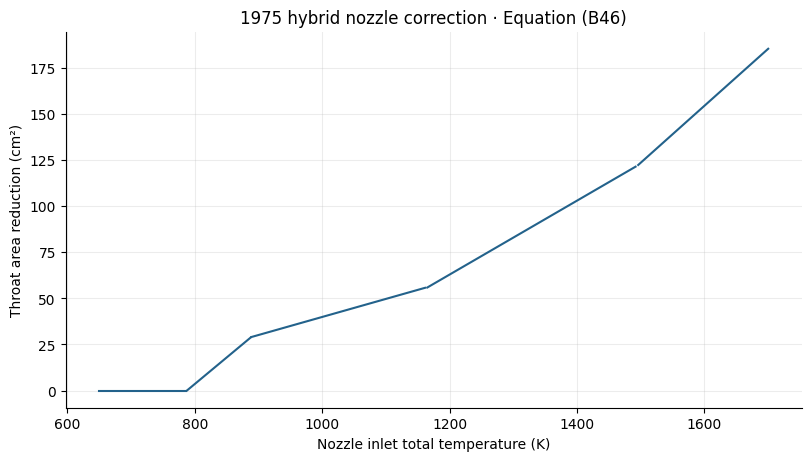

In [8]:
# NASA TM X-3261, Appendix B, printed p. 21. Separate each interval at the published breakpoints.
segments = (
    (650.0, 787.8, 0.0, 0.0),
    (787.8, 888.9, 0.28719, -226.2),
    (888.9, 1165.0, 0.09784, -57.93),
    (1165.0, 1496.0, 0.20032, -177.5),
    (1496.0, 1700.0, 0.30867, -339.5),
)
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
correction_samples = []
for index, (lo, hi, slope, intercept) in enumerate(segments):
    temperature = np.linspace(lo, hi, 80, endpoint=index == len(segments) - 1)
    area = slope * temperature + intercept
    ax.plot(temperature, area, color=DRY_COLOR)
    correction_samples.append(pd.DataFrame({
        "nozzle_inlet_total_temperature_k": temperature,
        "throat_area_correction_cm2": area,
    }))
ax.set(title="1975 hybrid nozzle correction · Equation (B46)",
       xlabel="Nozzle inlet total temperature (K)", ylabel="Throat area reduction (cm²)")
ax.grid(alpha=0.23)
pd.concat(correction_samples, ignore_index=True).to_csv(
    OUTPUT / "historical_nozzle_correction.csv", index=False
)
show_and_export(fig, "historical_nozzle_correction")

## 6. Complete source figure galleries

These are facsimiles of the published figures with the source axes and captions. They include diagrams, measured traces, calculated curves, controls comparisons, and normalized component-map plots. They preserve panel coverage for figures whose full numerical series is unavailable. The galleries remain separate from computed simulator outputs and from the explicitly digitized replots above.

The 1984 HIDEC report covers the **PW-1128 EMD**. The 1975 hybrid-computer report covers the **F100-PW-100** and supplies plotted component characteristics. Its FORTRAN listing reads detailed map data from external cards. Those full tabulations are absent from the scan. The current C++ map format and synthetic cases have not been replaced by these reference plots. [1984 figure index](references/hidec/README.md) · [1975 figure index](references/nasa-19750019996/README.md)

### NASA TM-86040 · HIDEC report · Figures 1–12

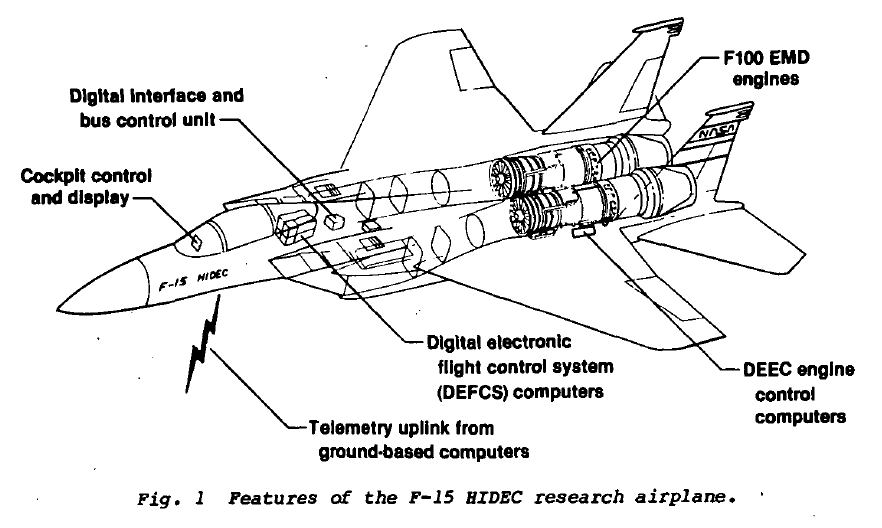

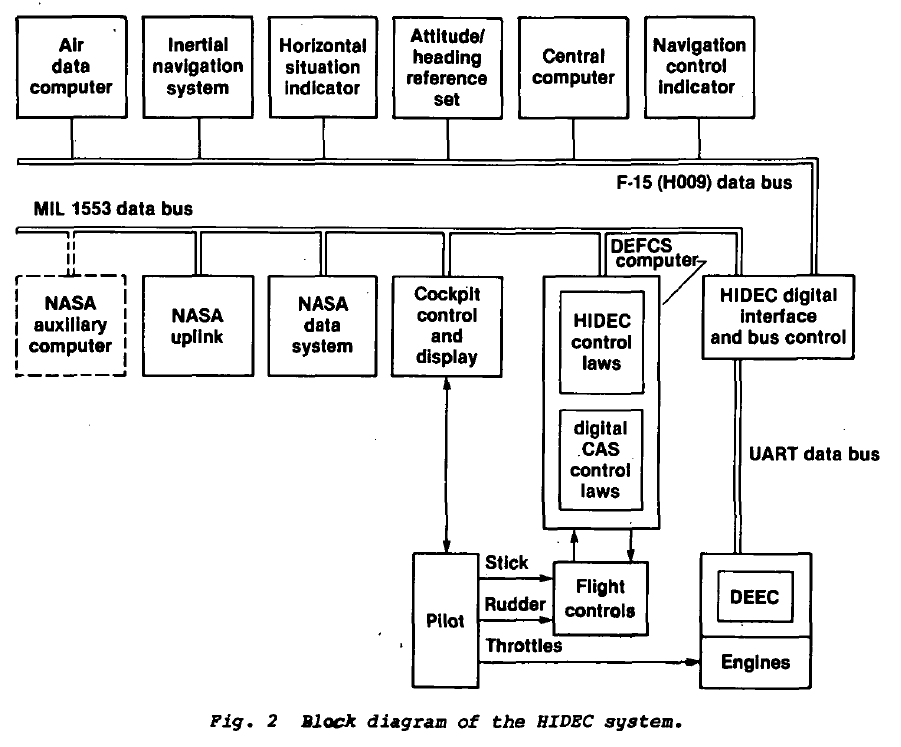

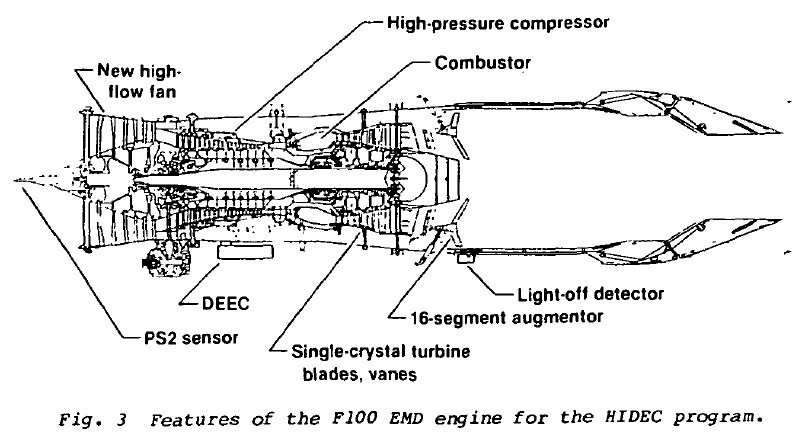

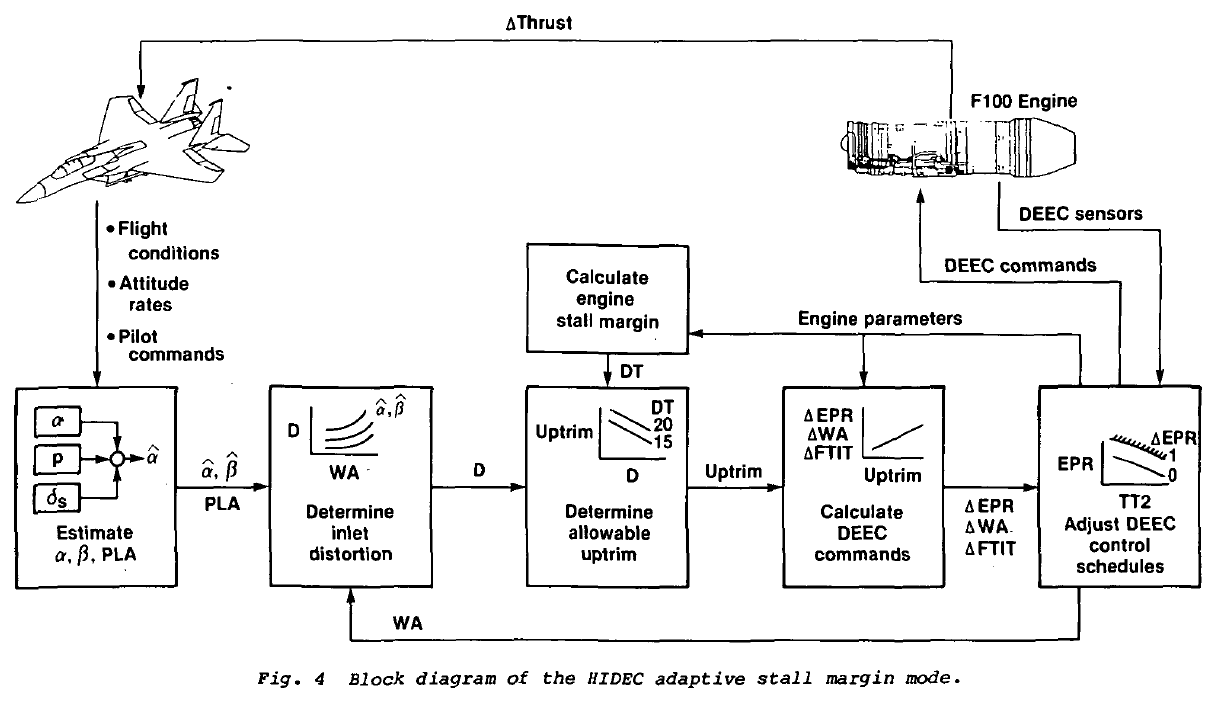

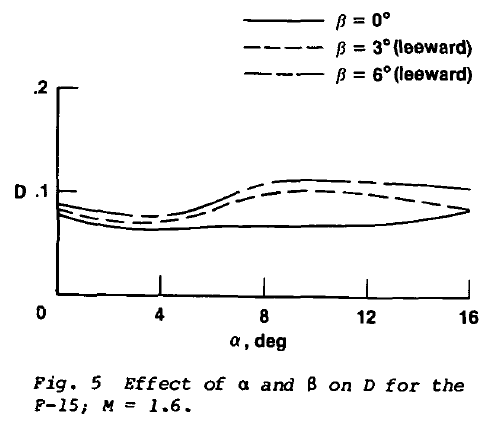

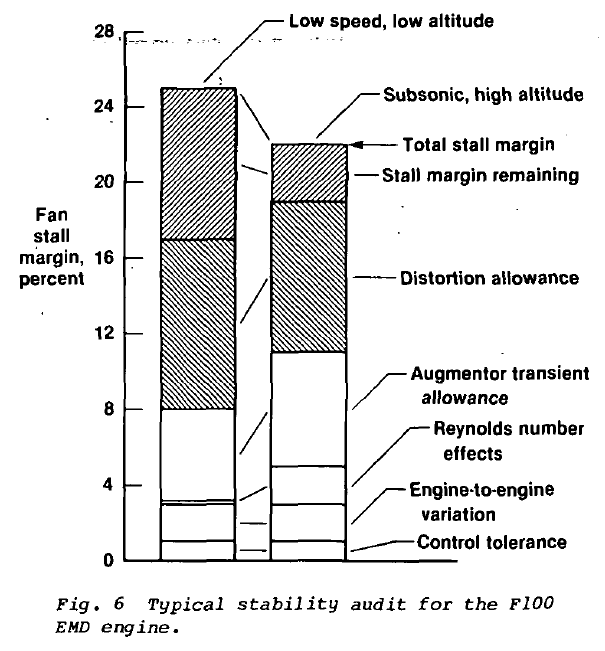

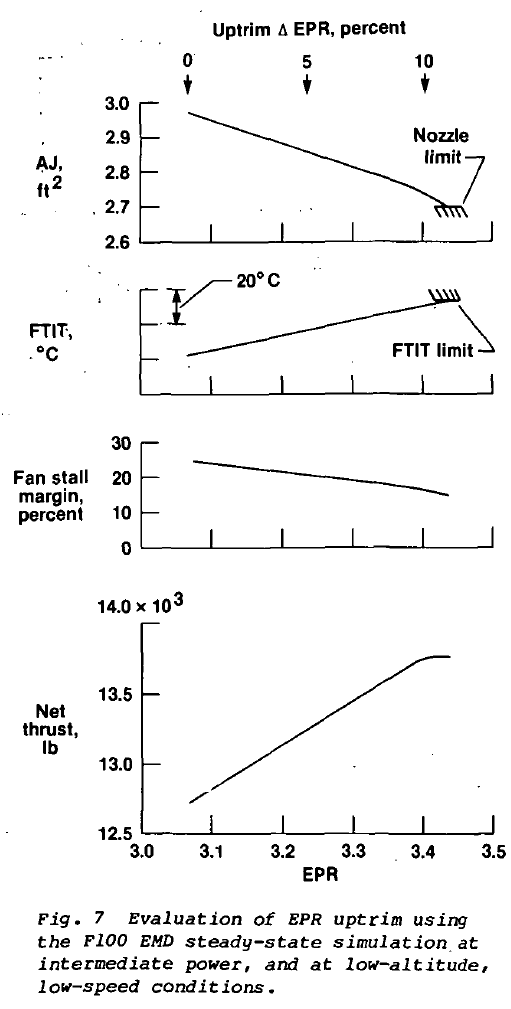

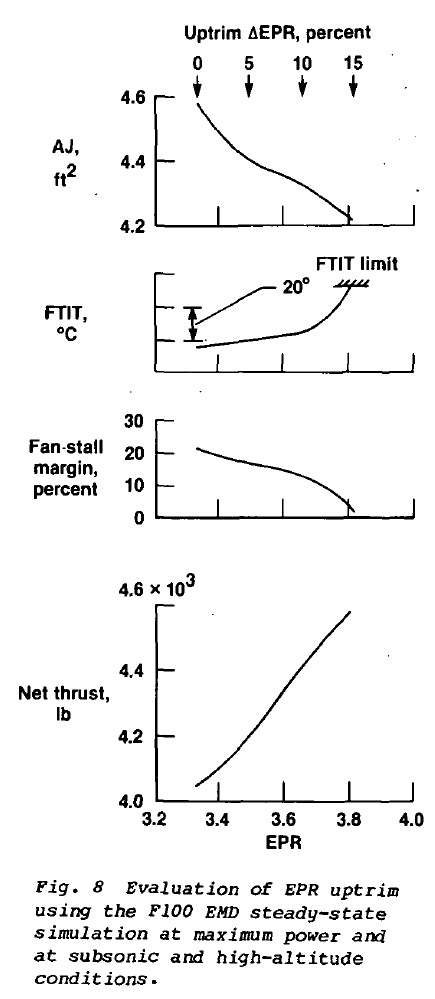

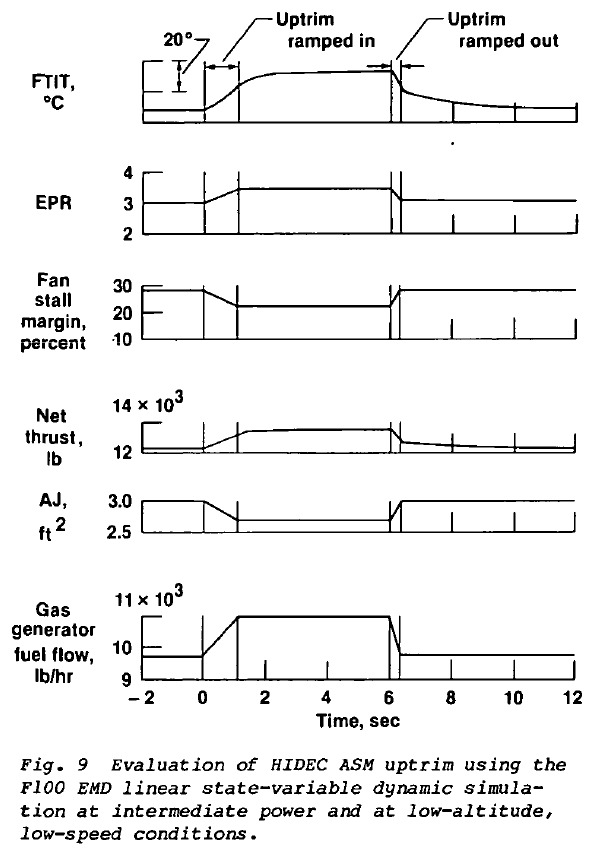

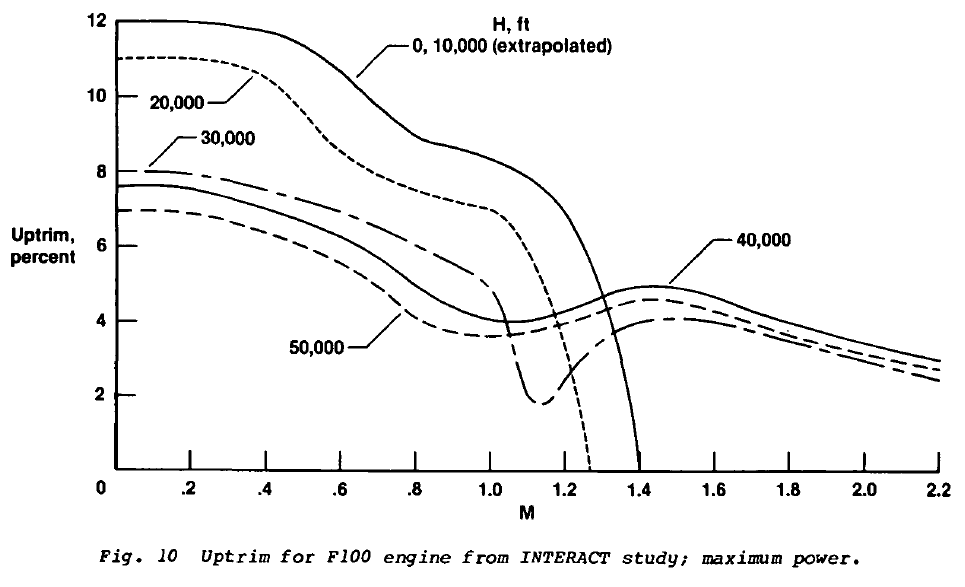

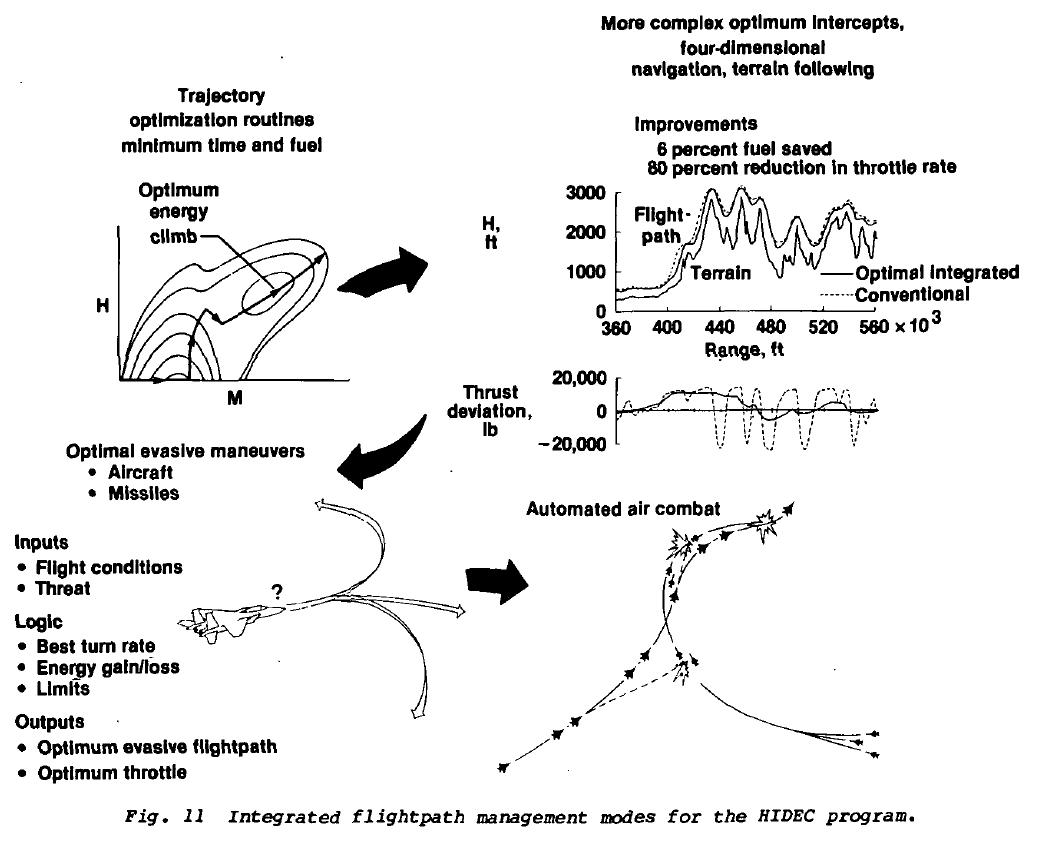

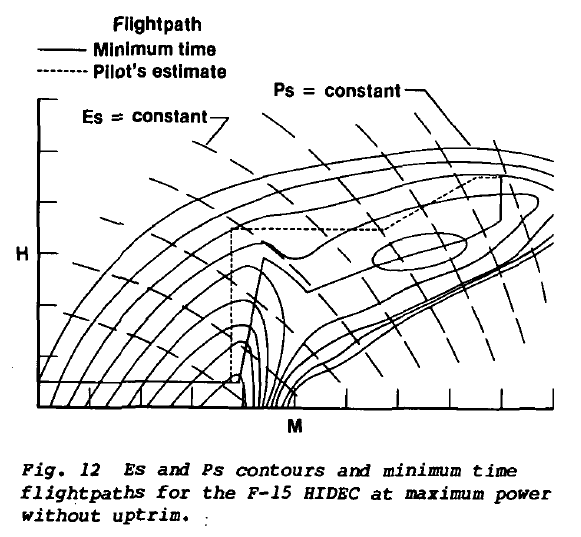

In [9]:
def show_source_figures(directory, count):
    figures = sorted((ROOT / "notebooks" / "references" / directory).glob("*.png"))
    if len(figures) != count:
        raise FileNotFoundError(f"Expected {count} source images for {directory}, found {len(figures)}.")
    for figure in figures:
        display(Image(filename=str(figure), width=900))

display(Markdown("### NASA TM-86040 · HIDEC report · Figures 1–12"))
show_source_figures("hidec", 12)

### NASA TM X-3261 · Hybrid F100-PW-100 · Figures 1–23

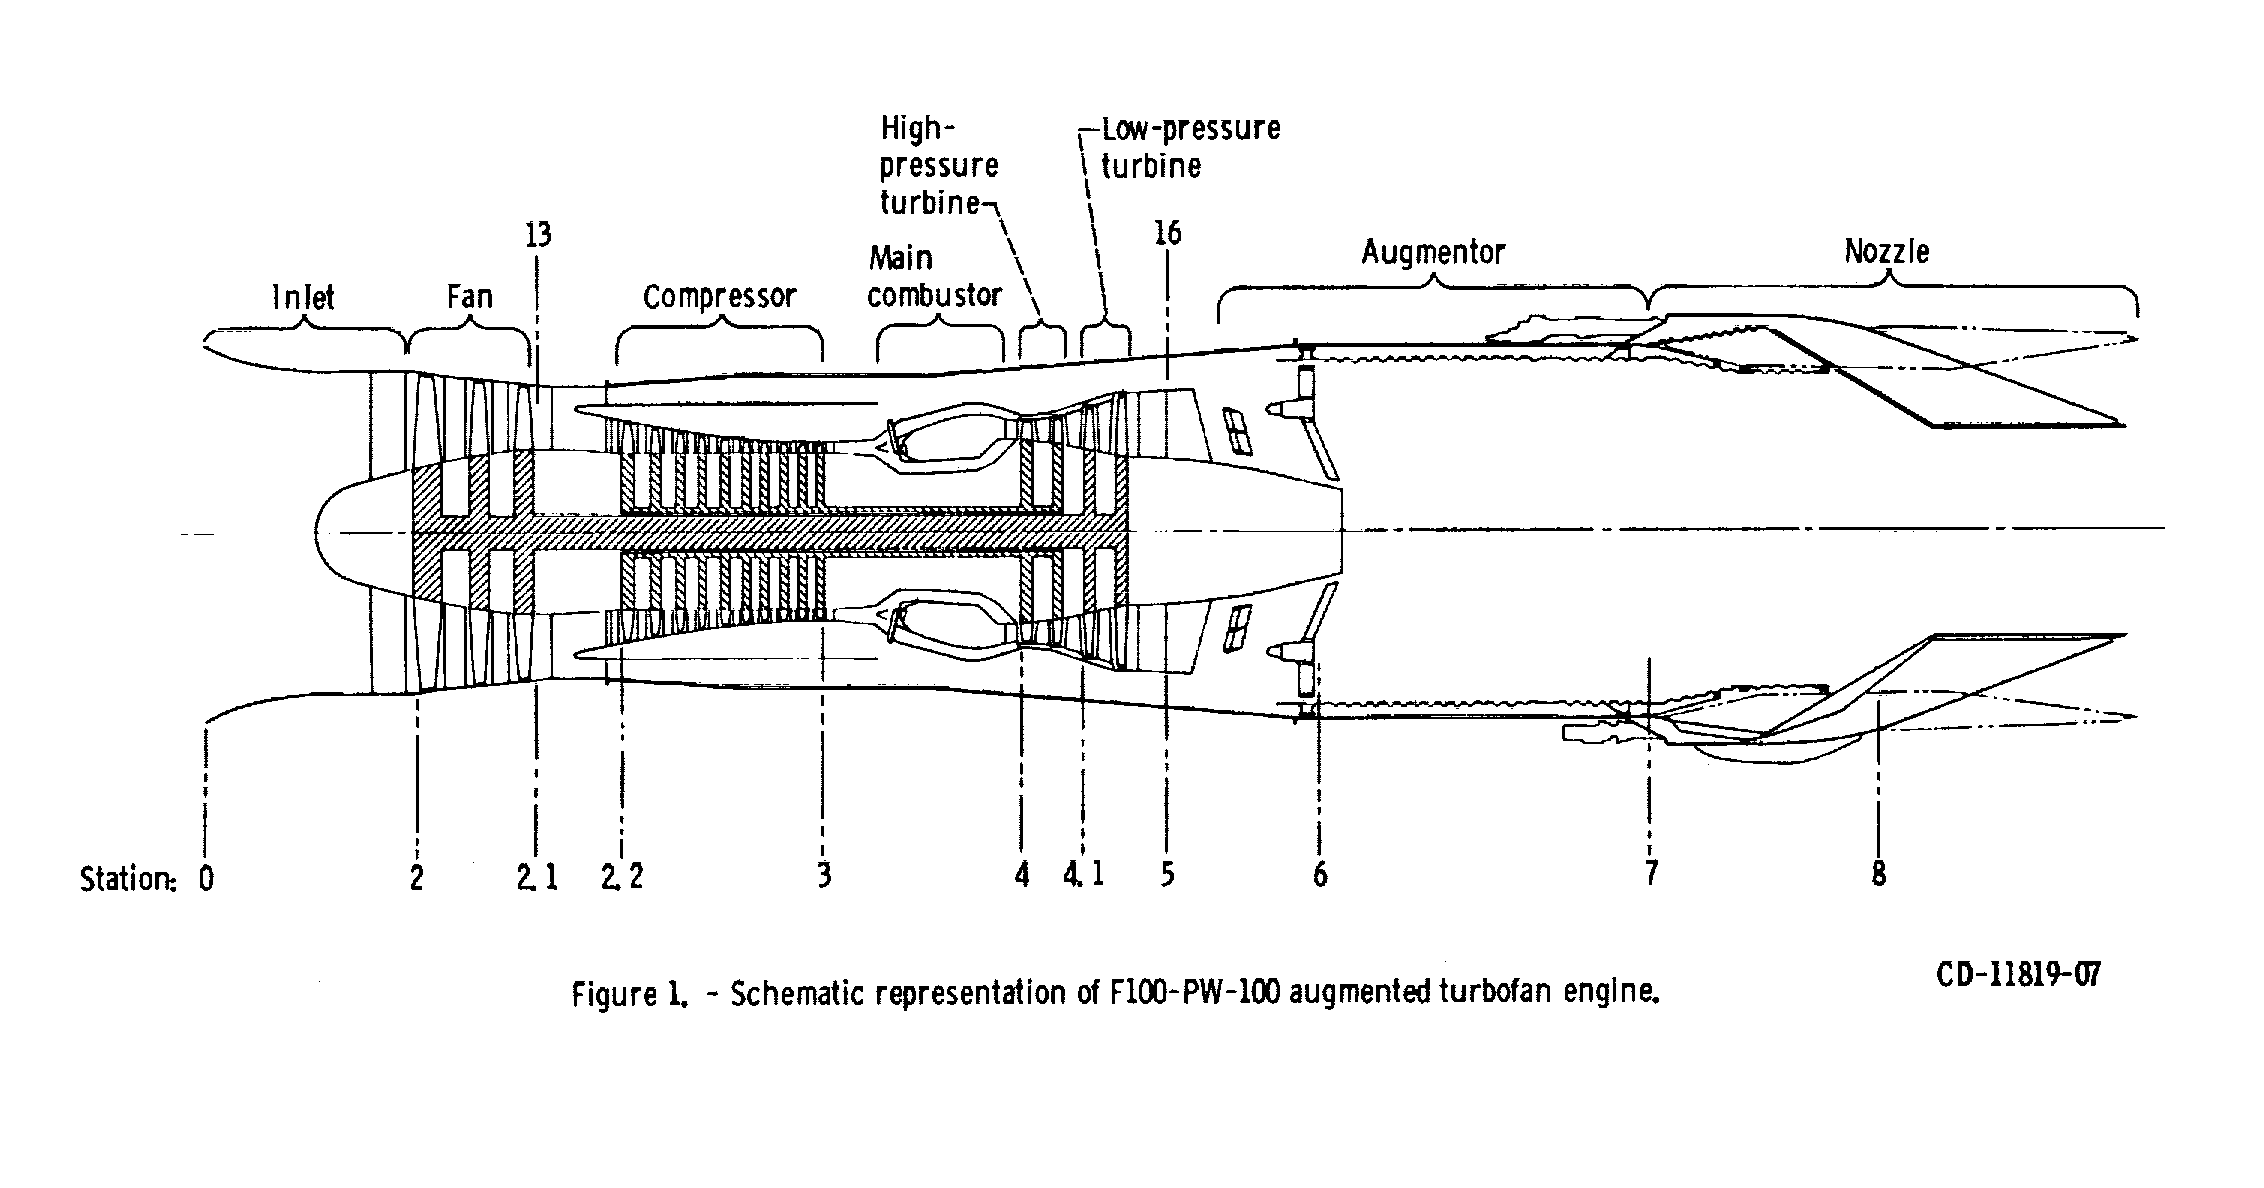

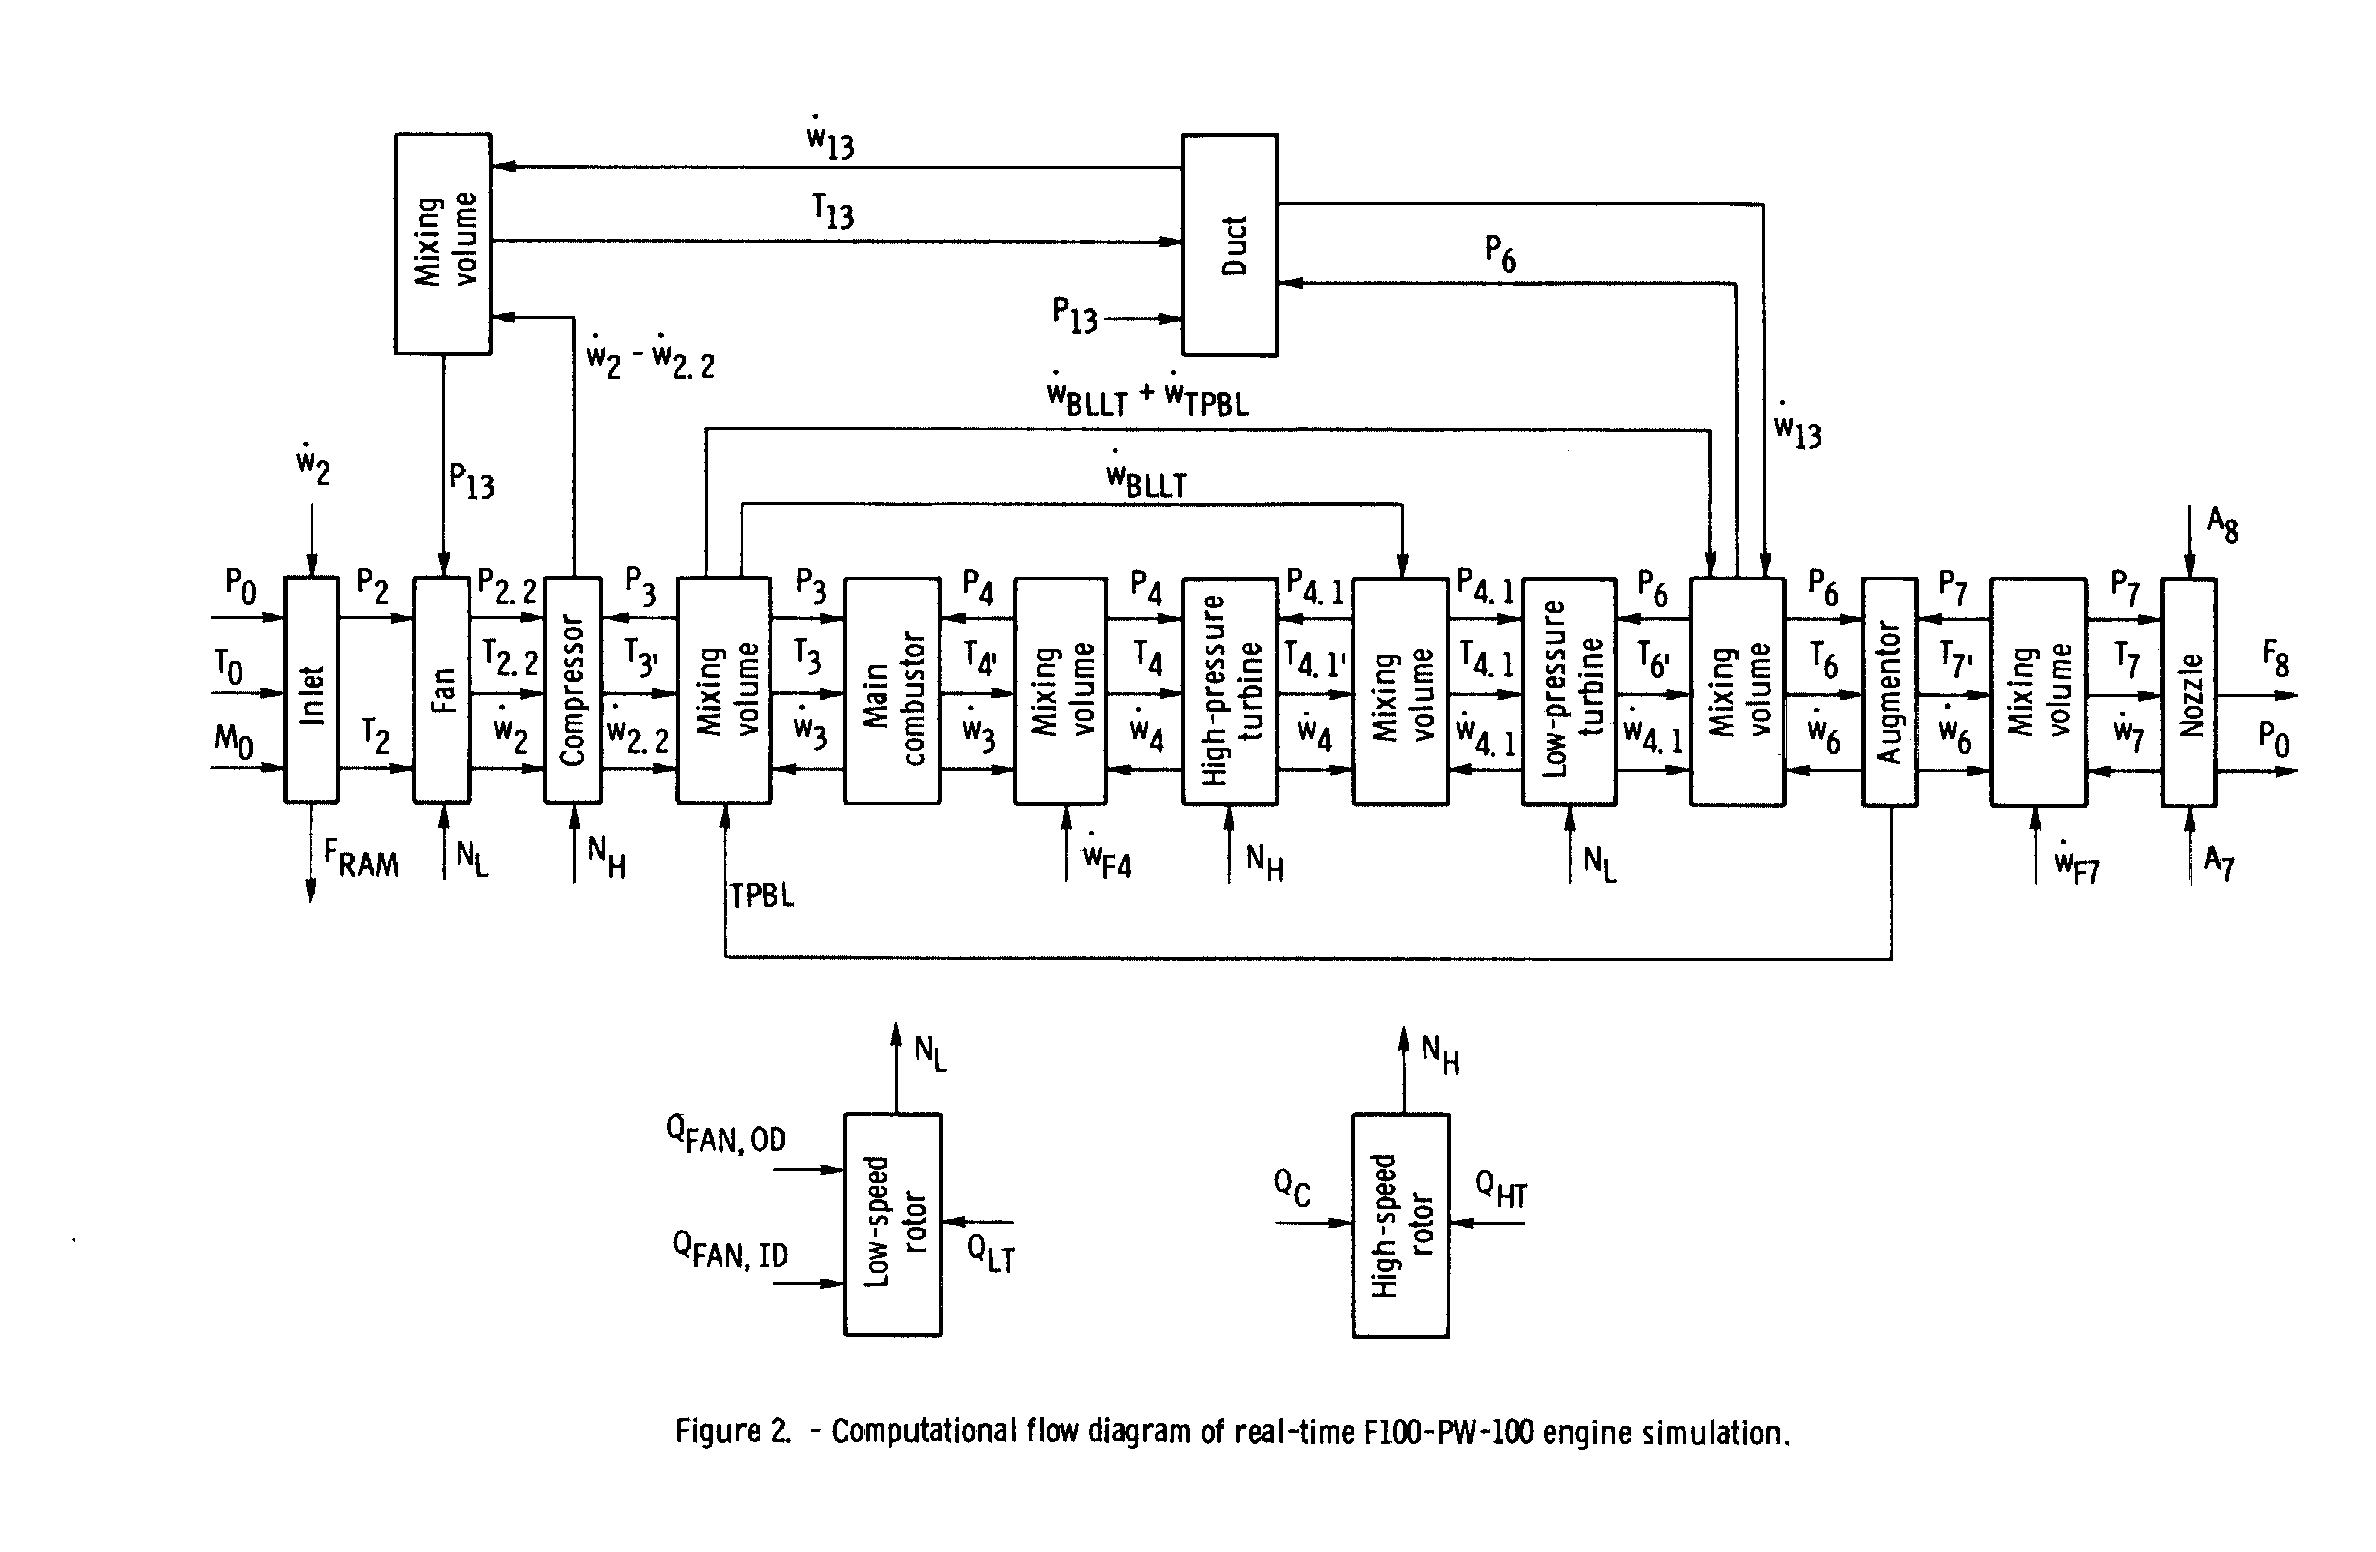

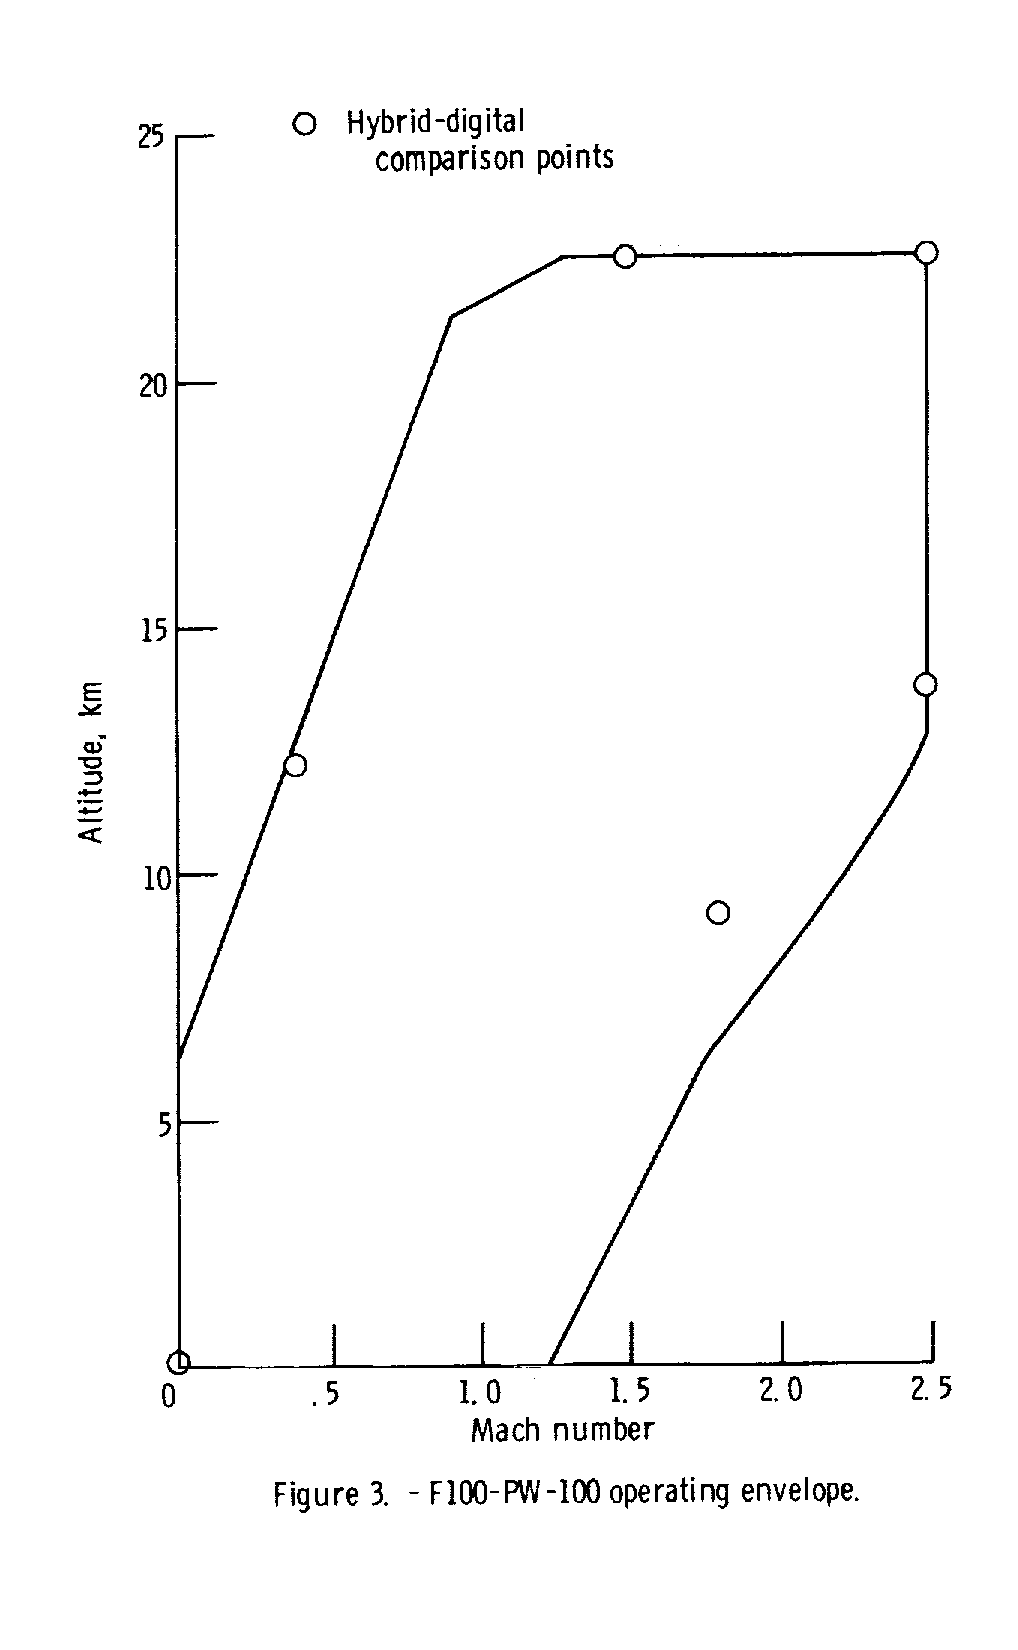

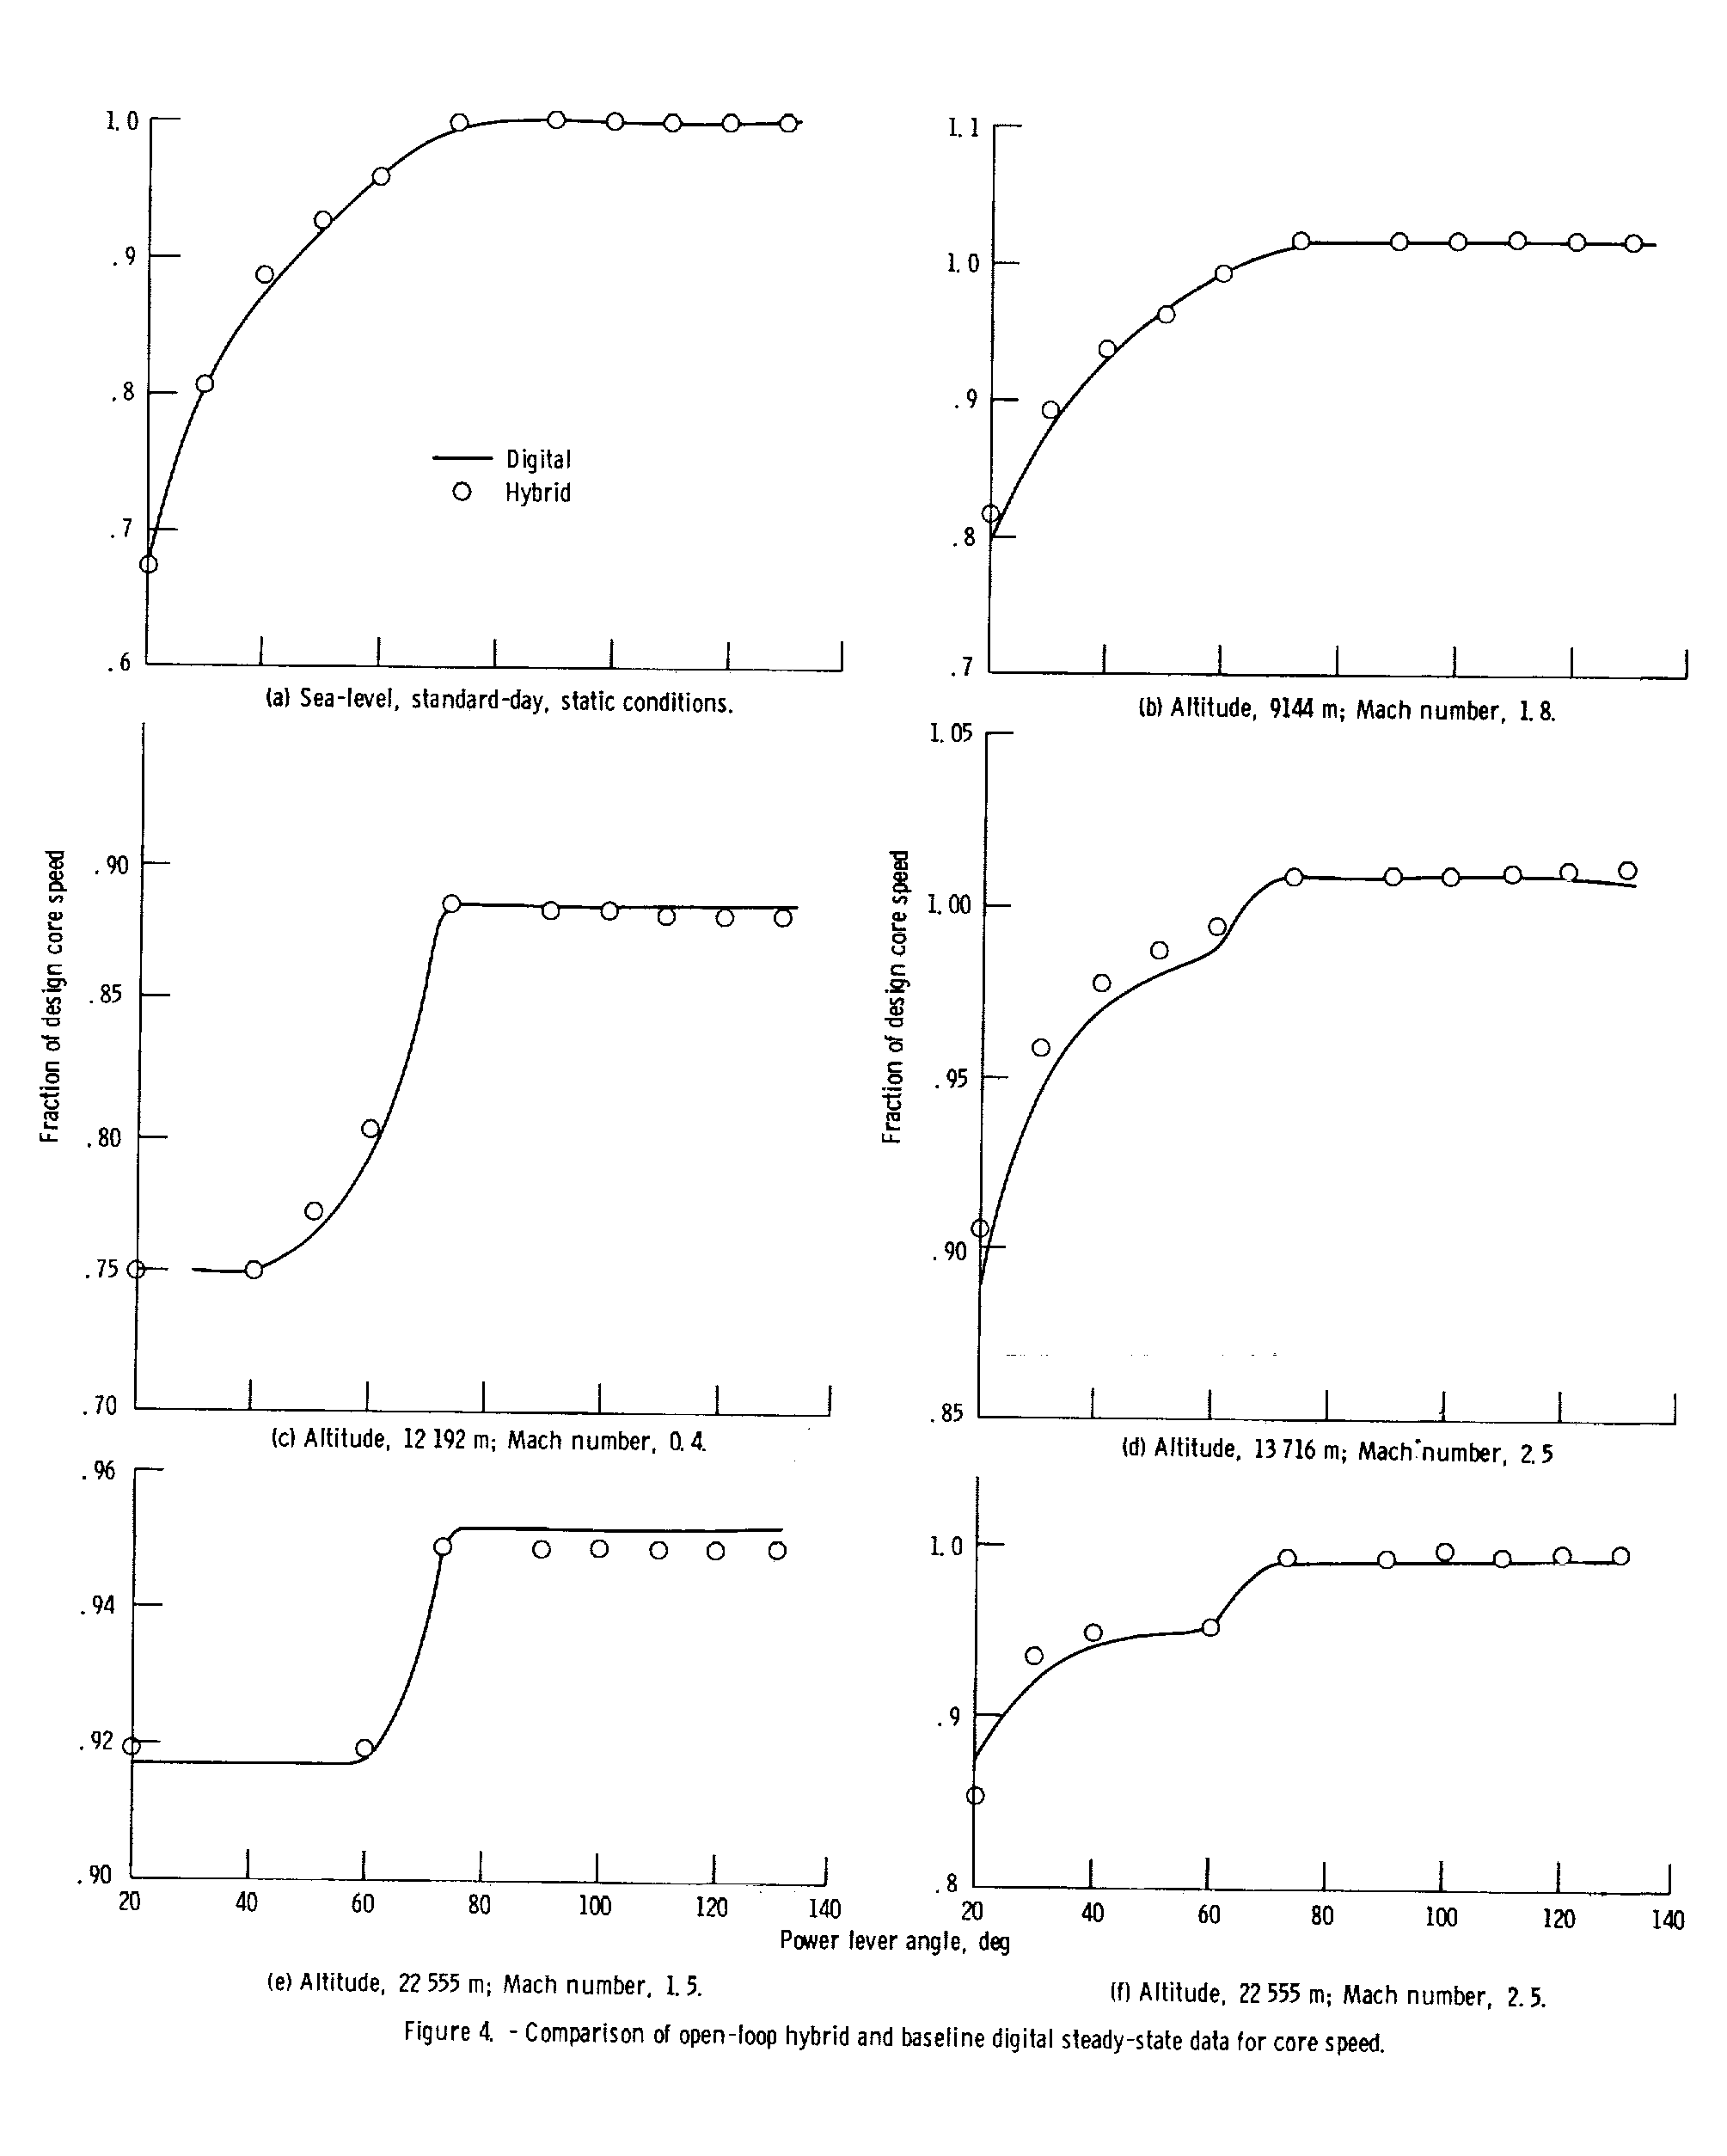

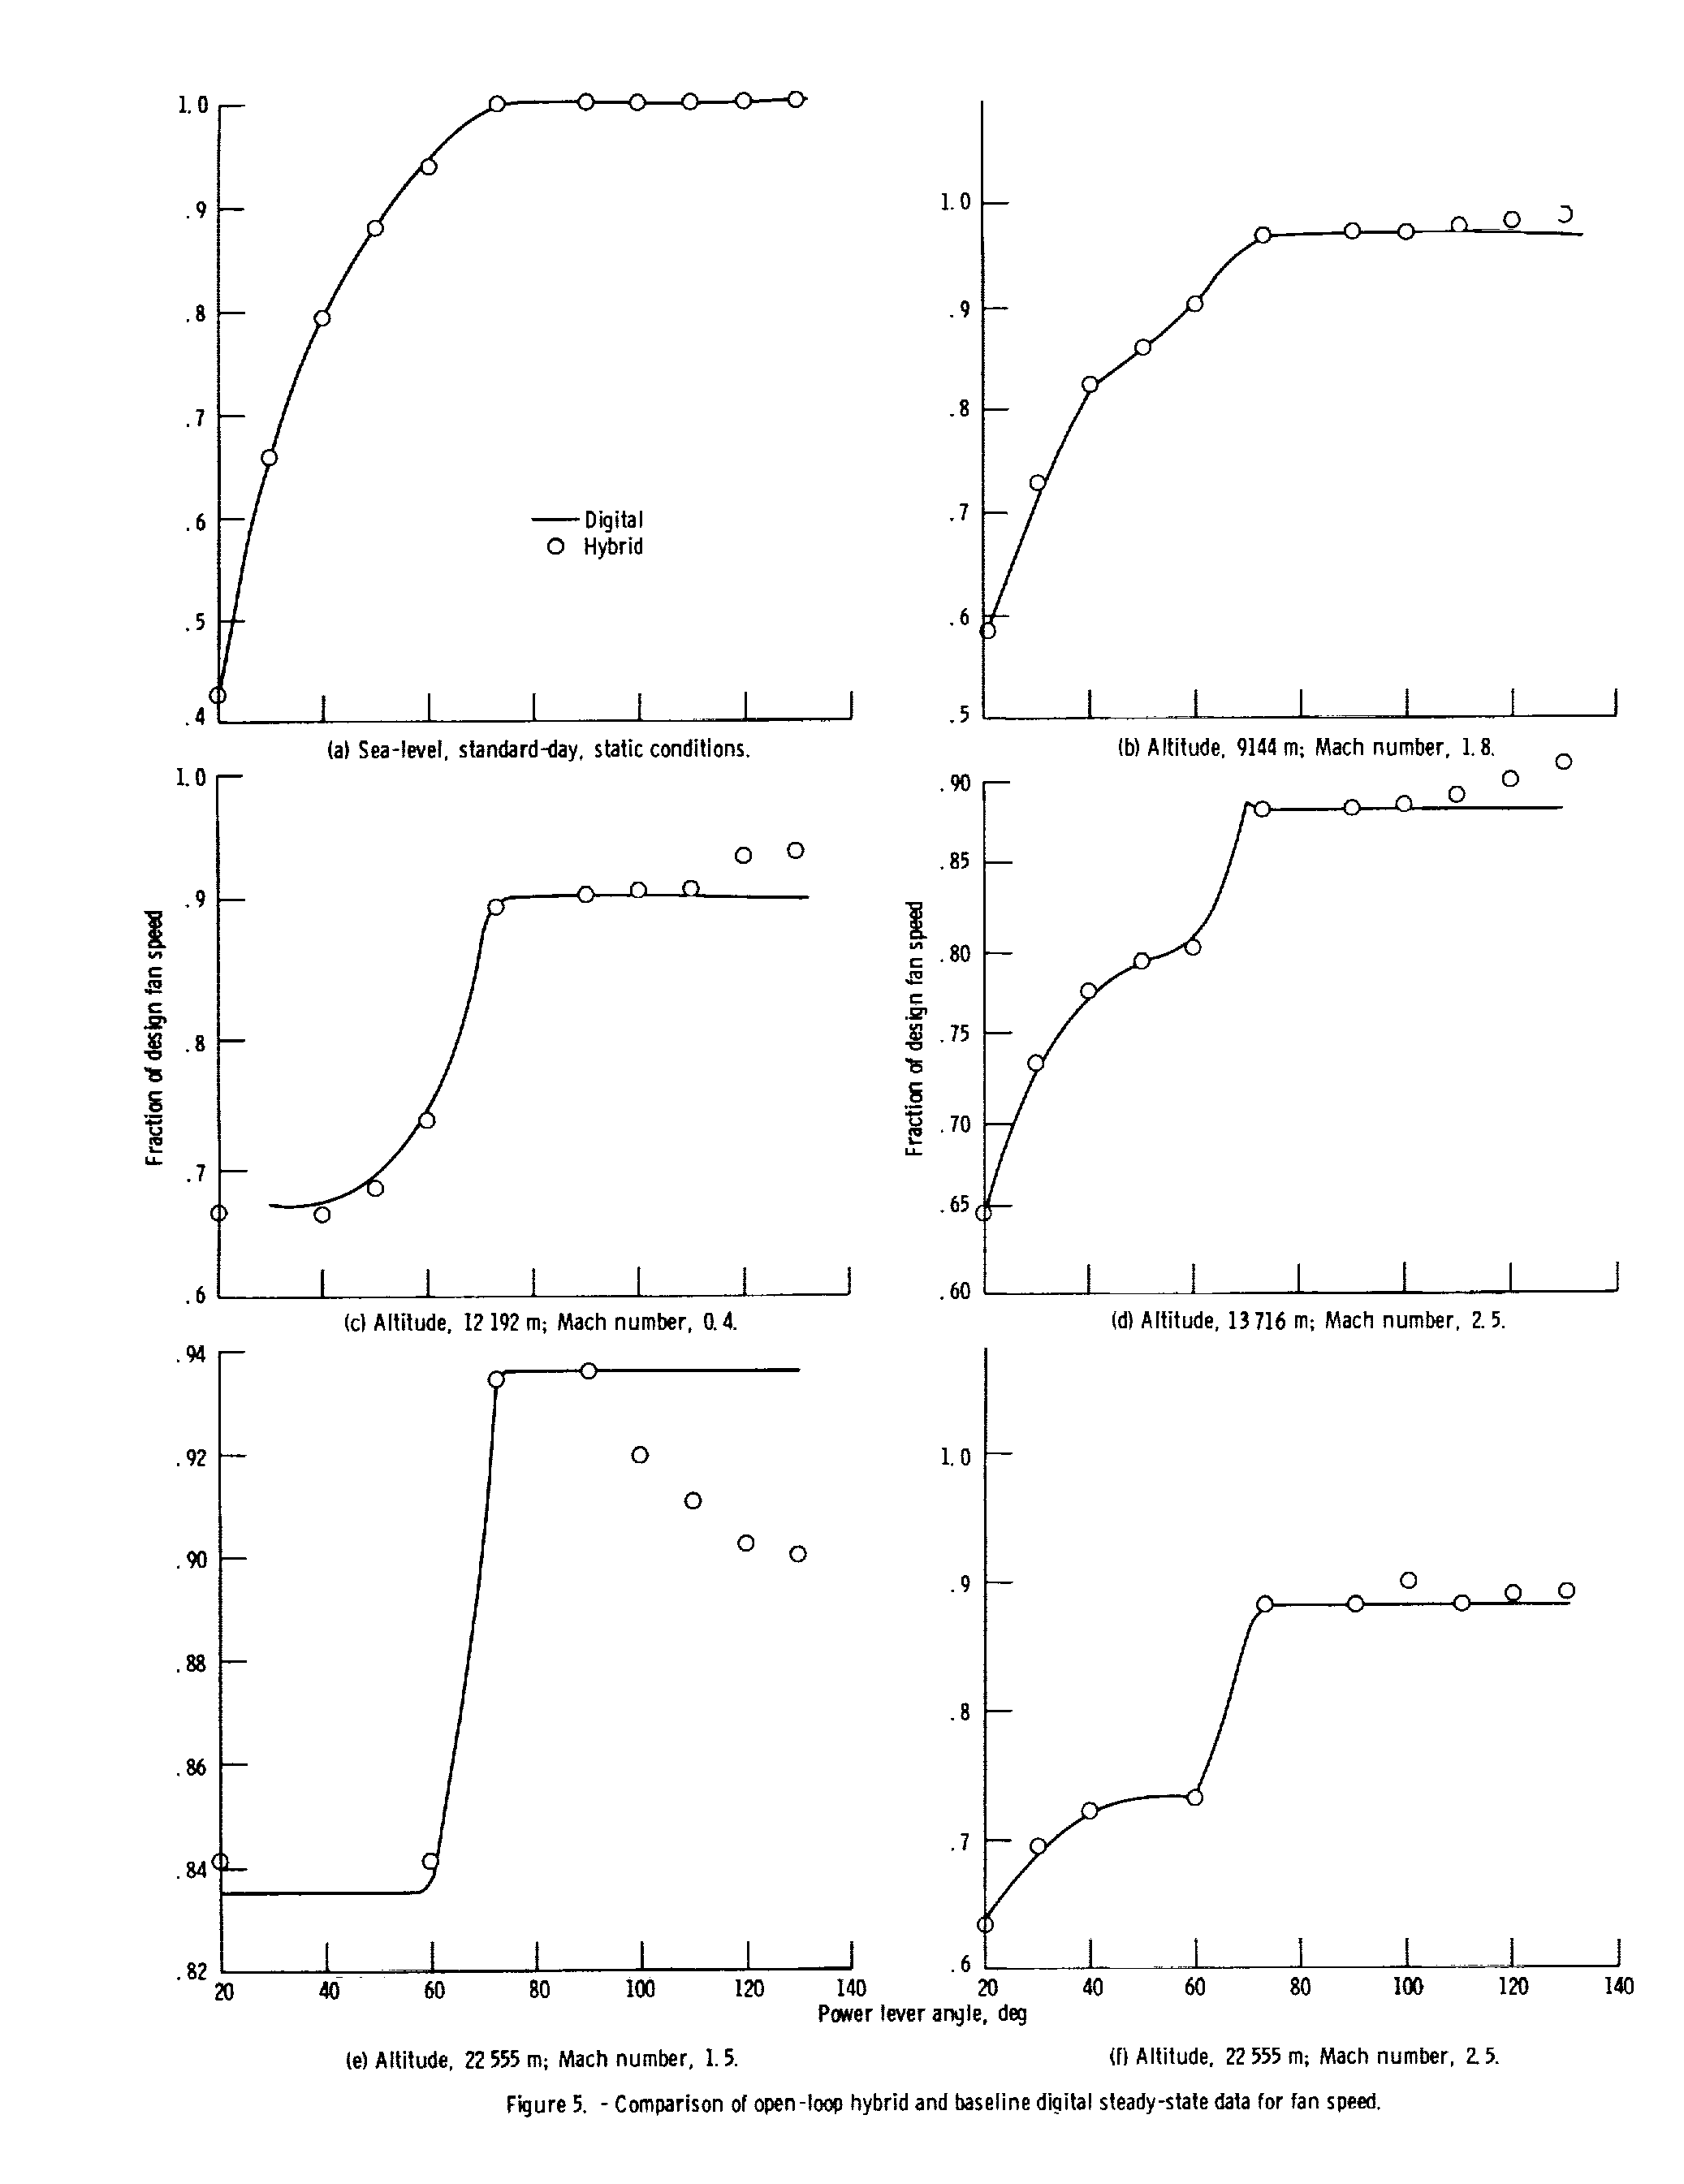

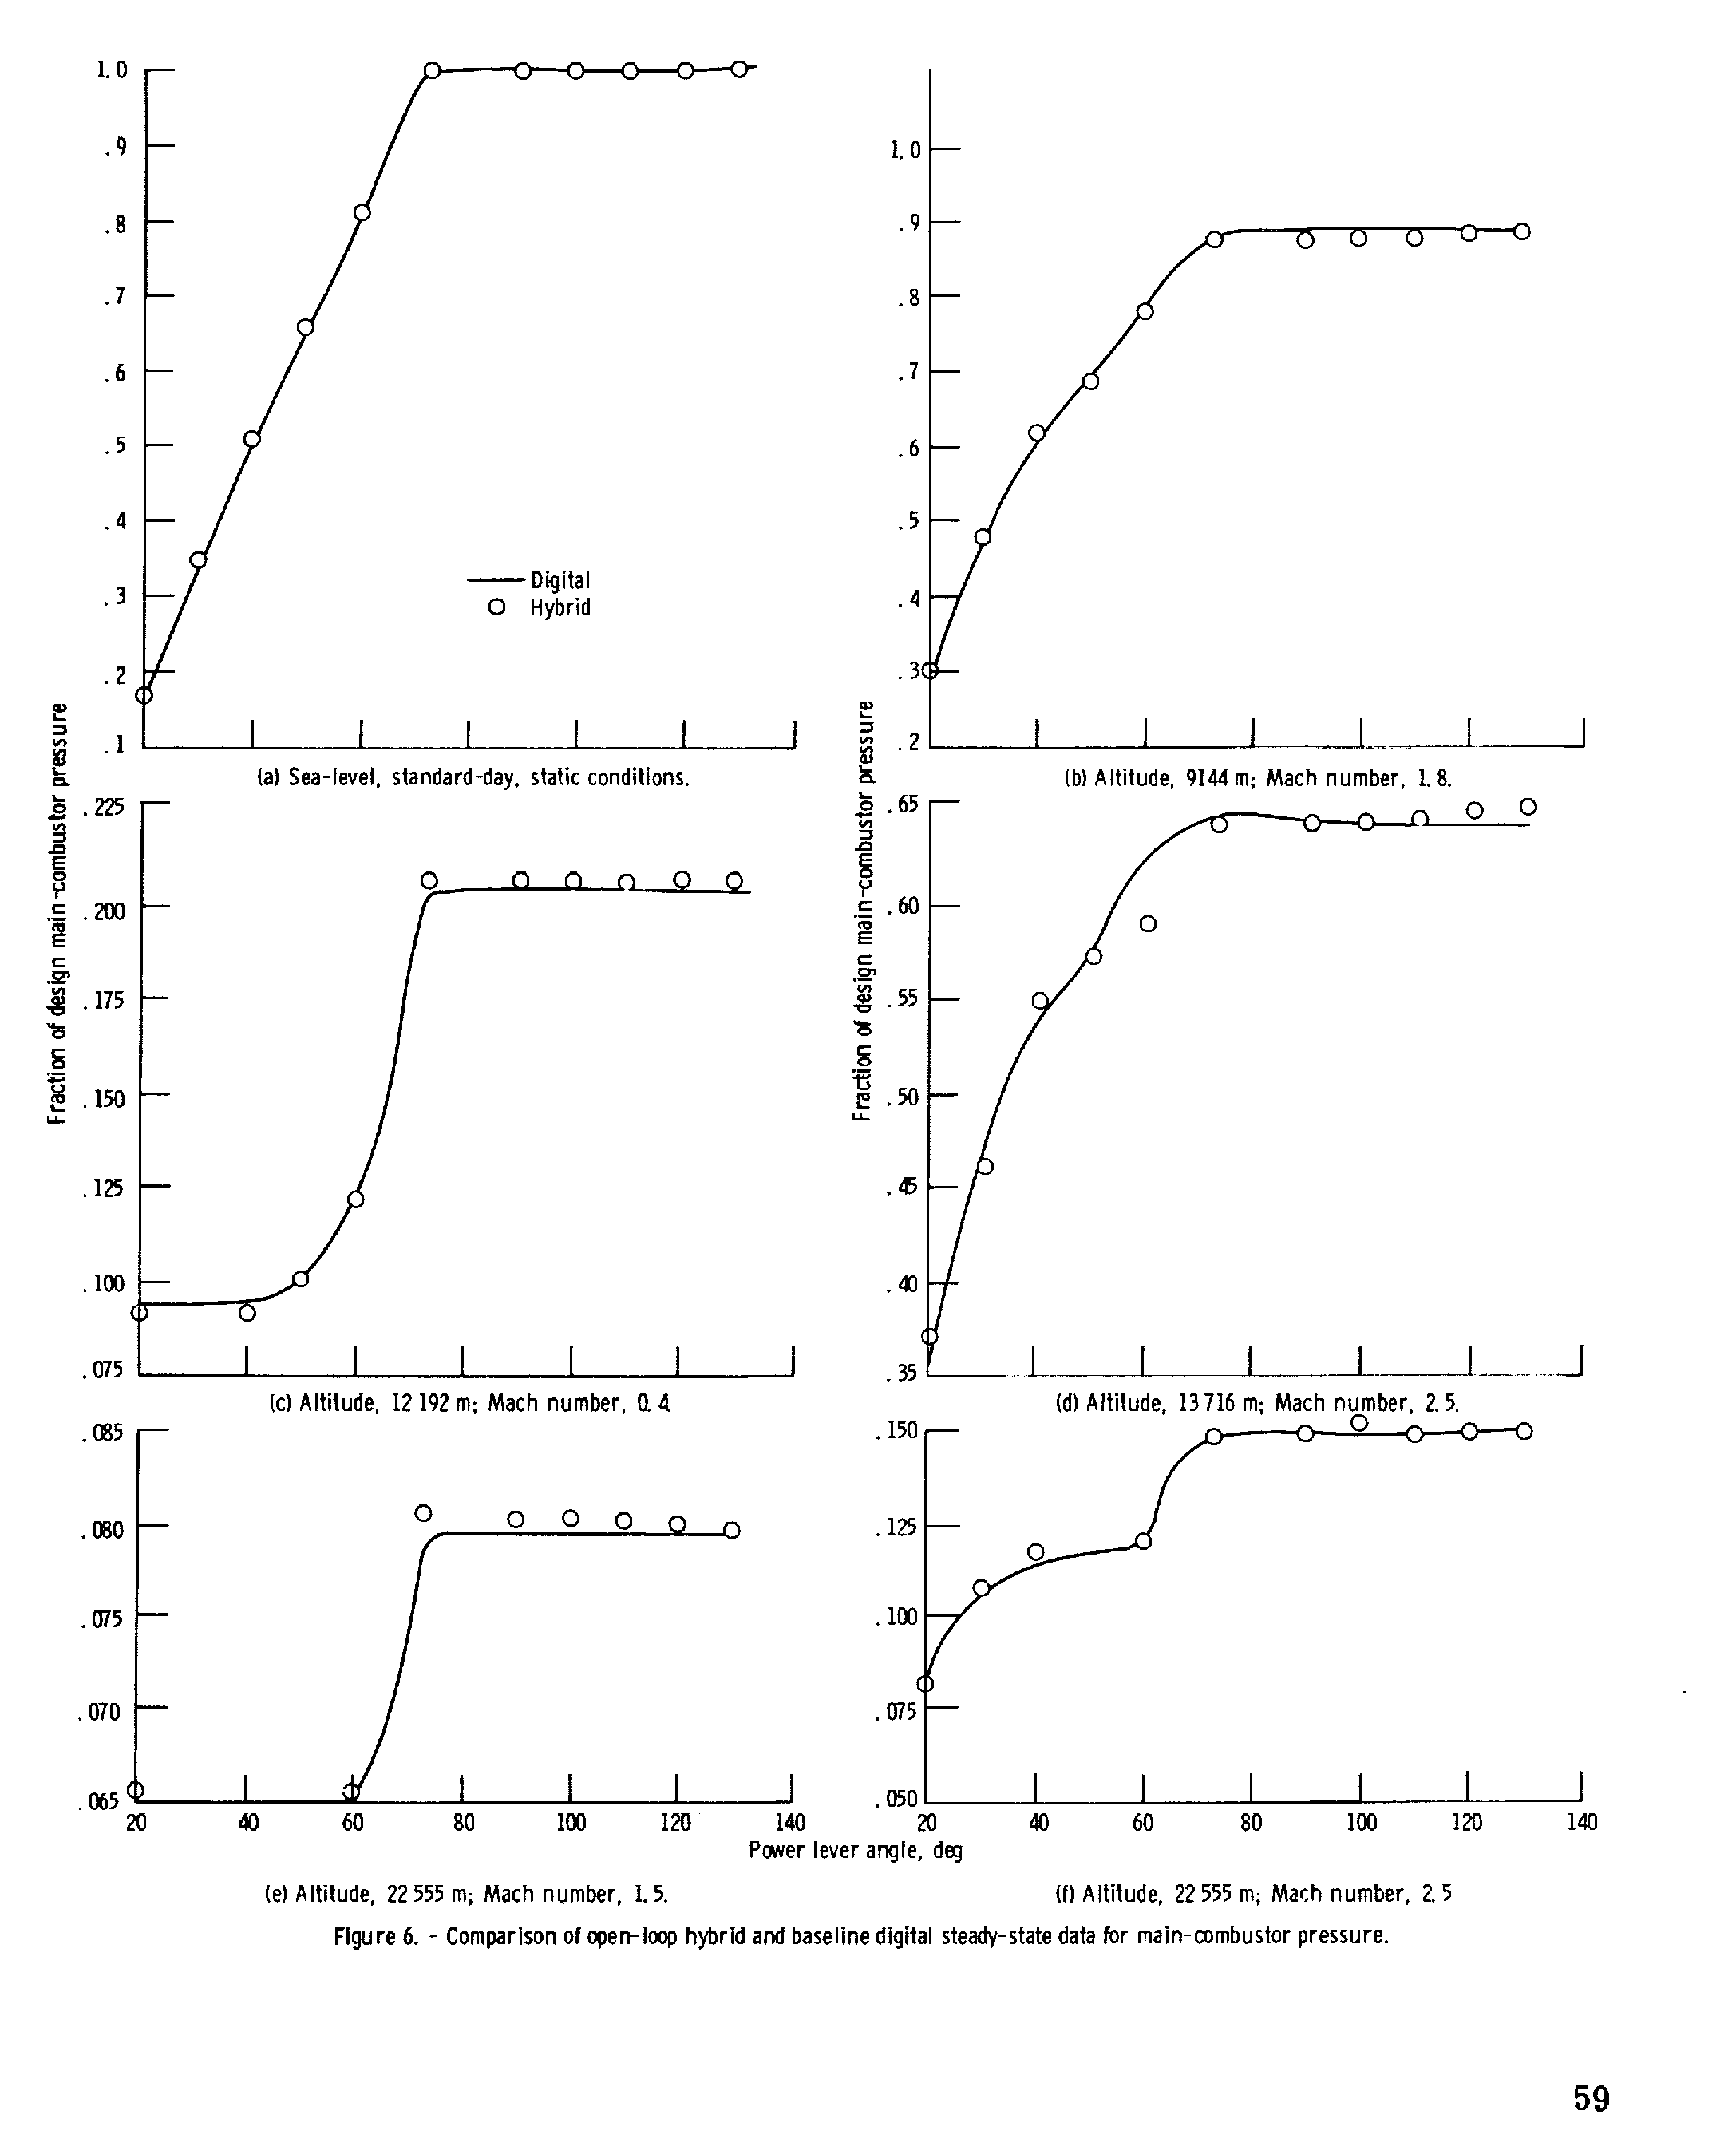

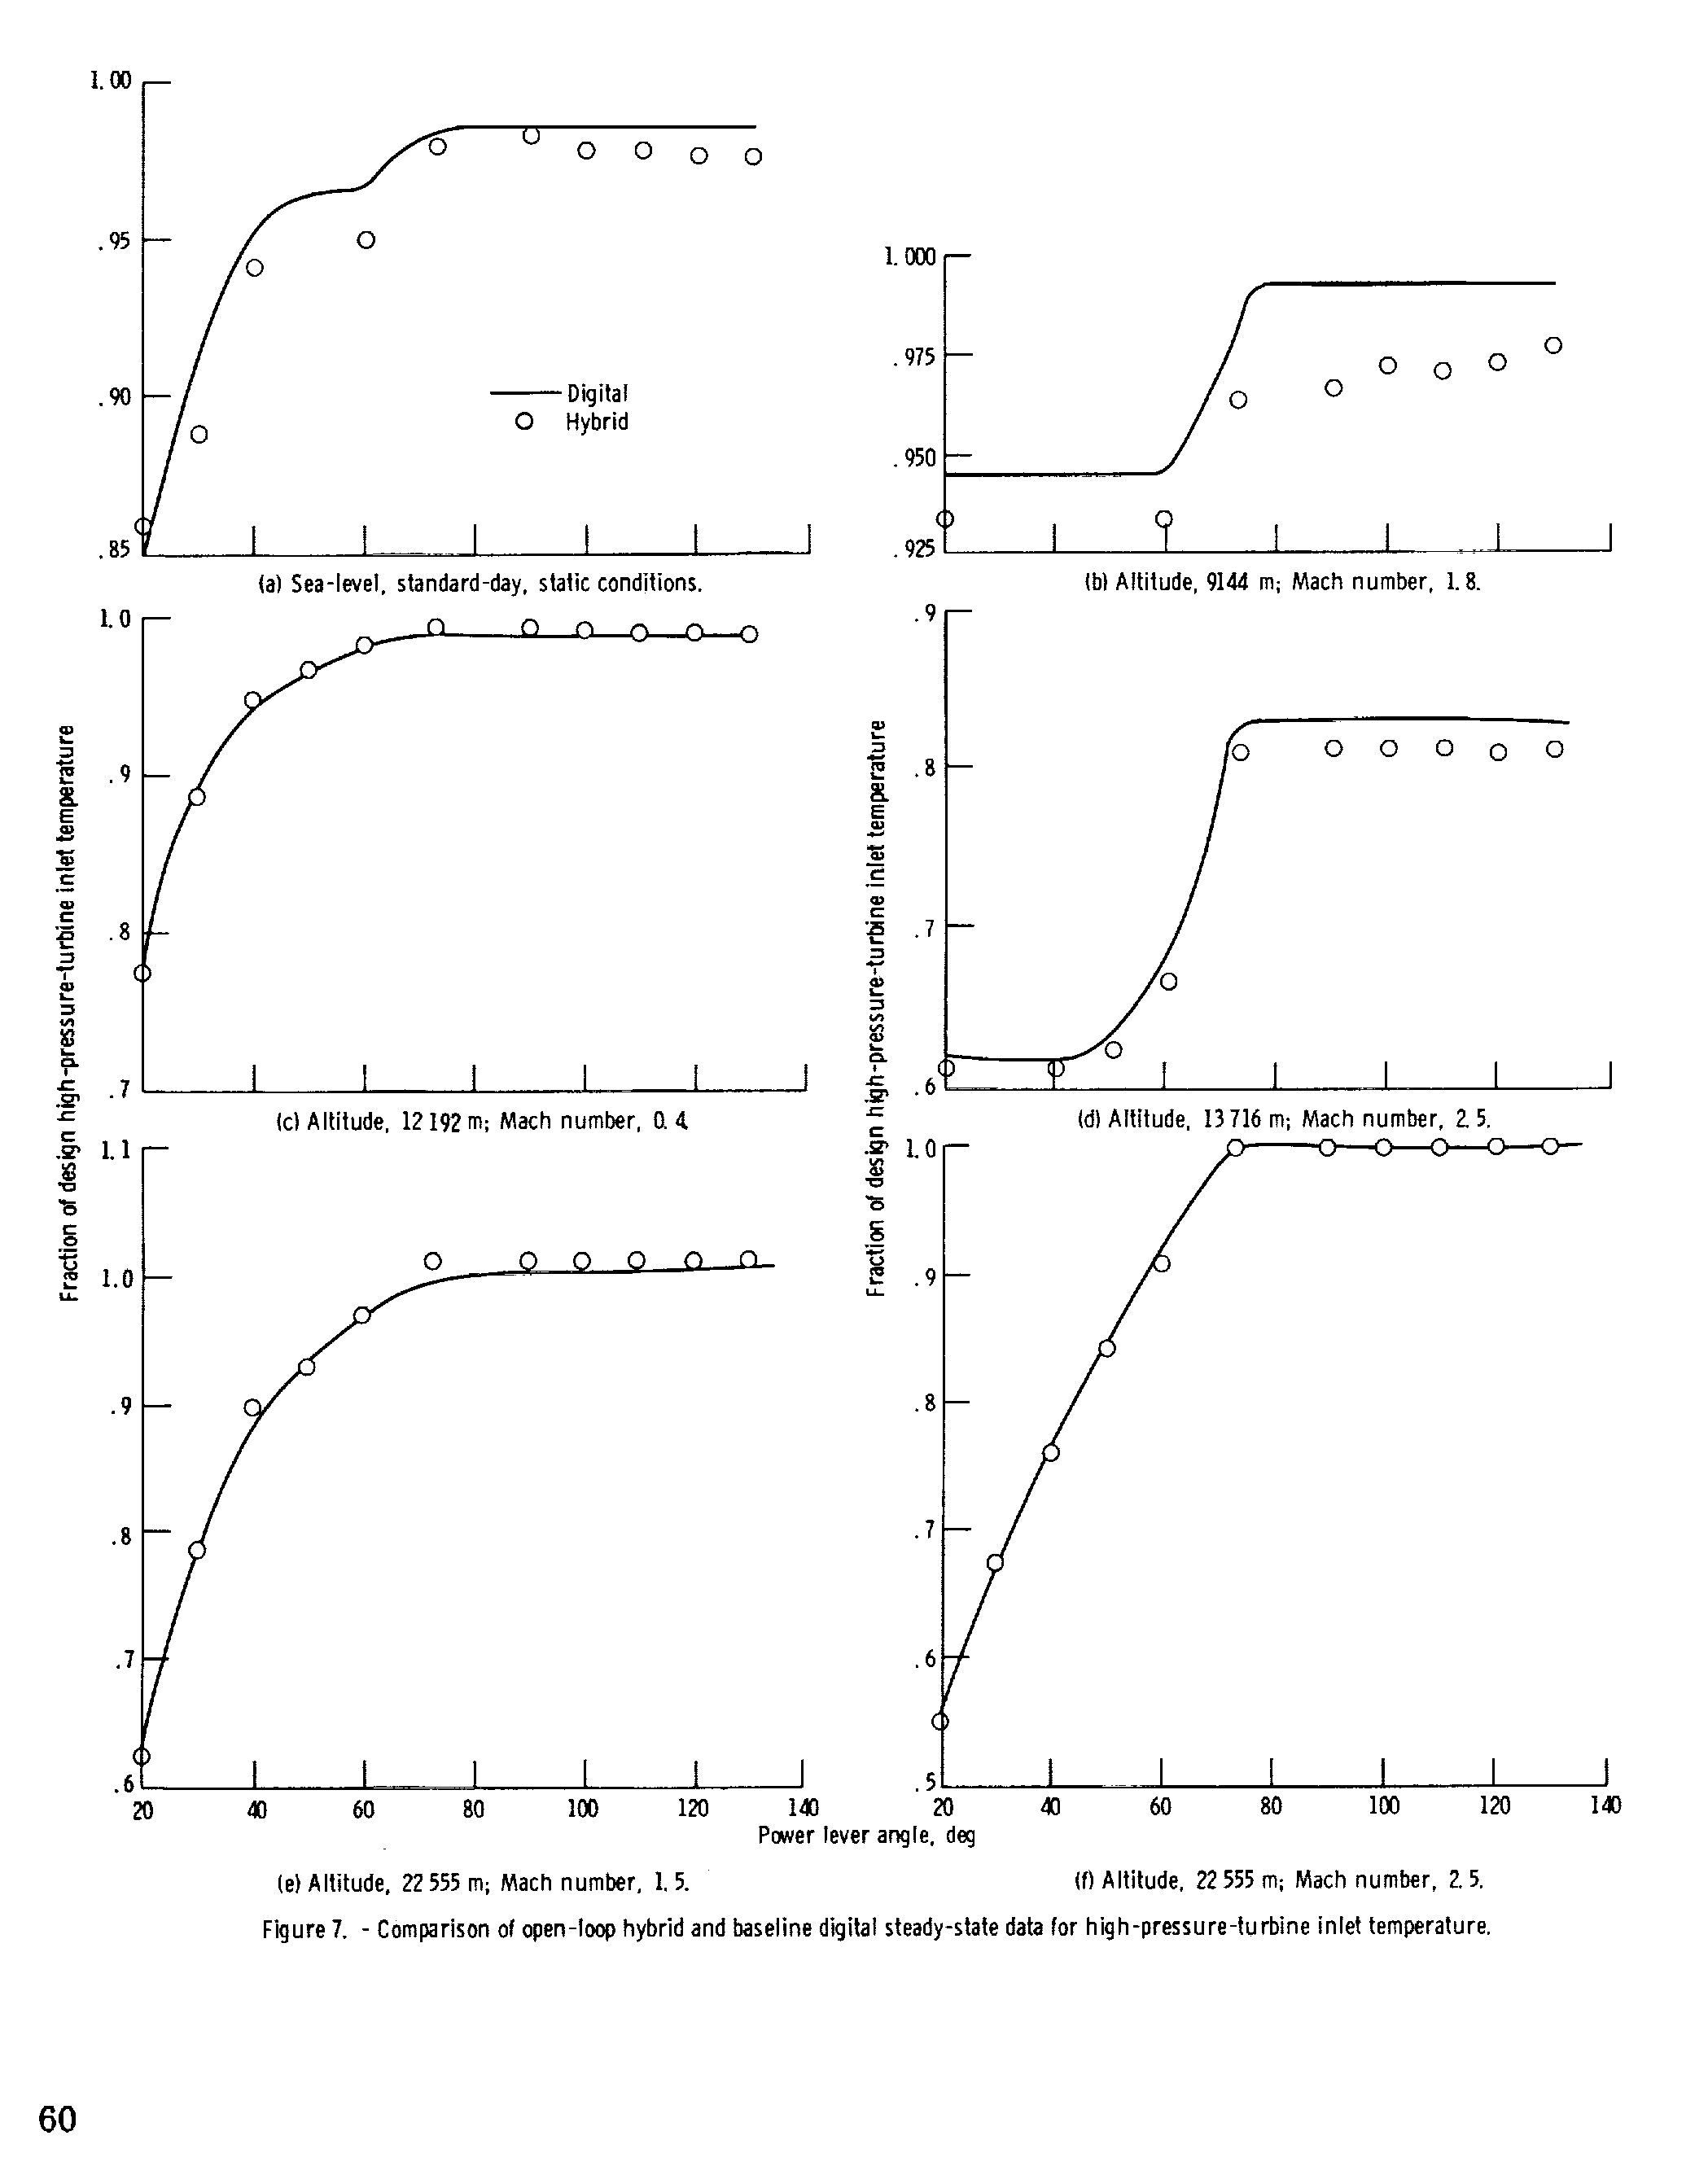

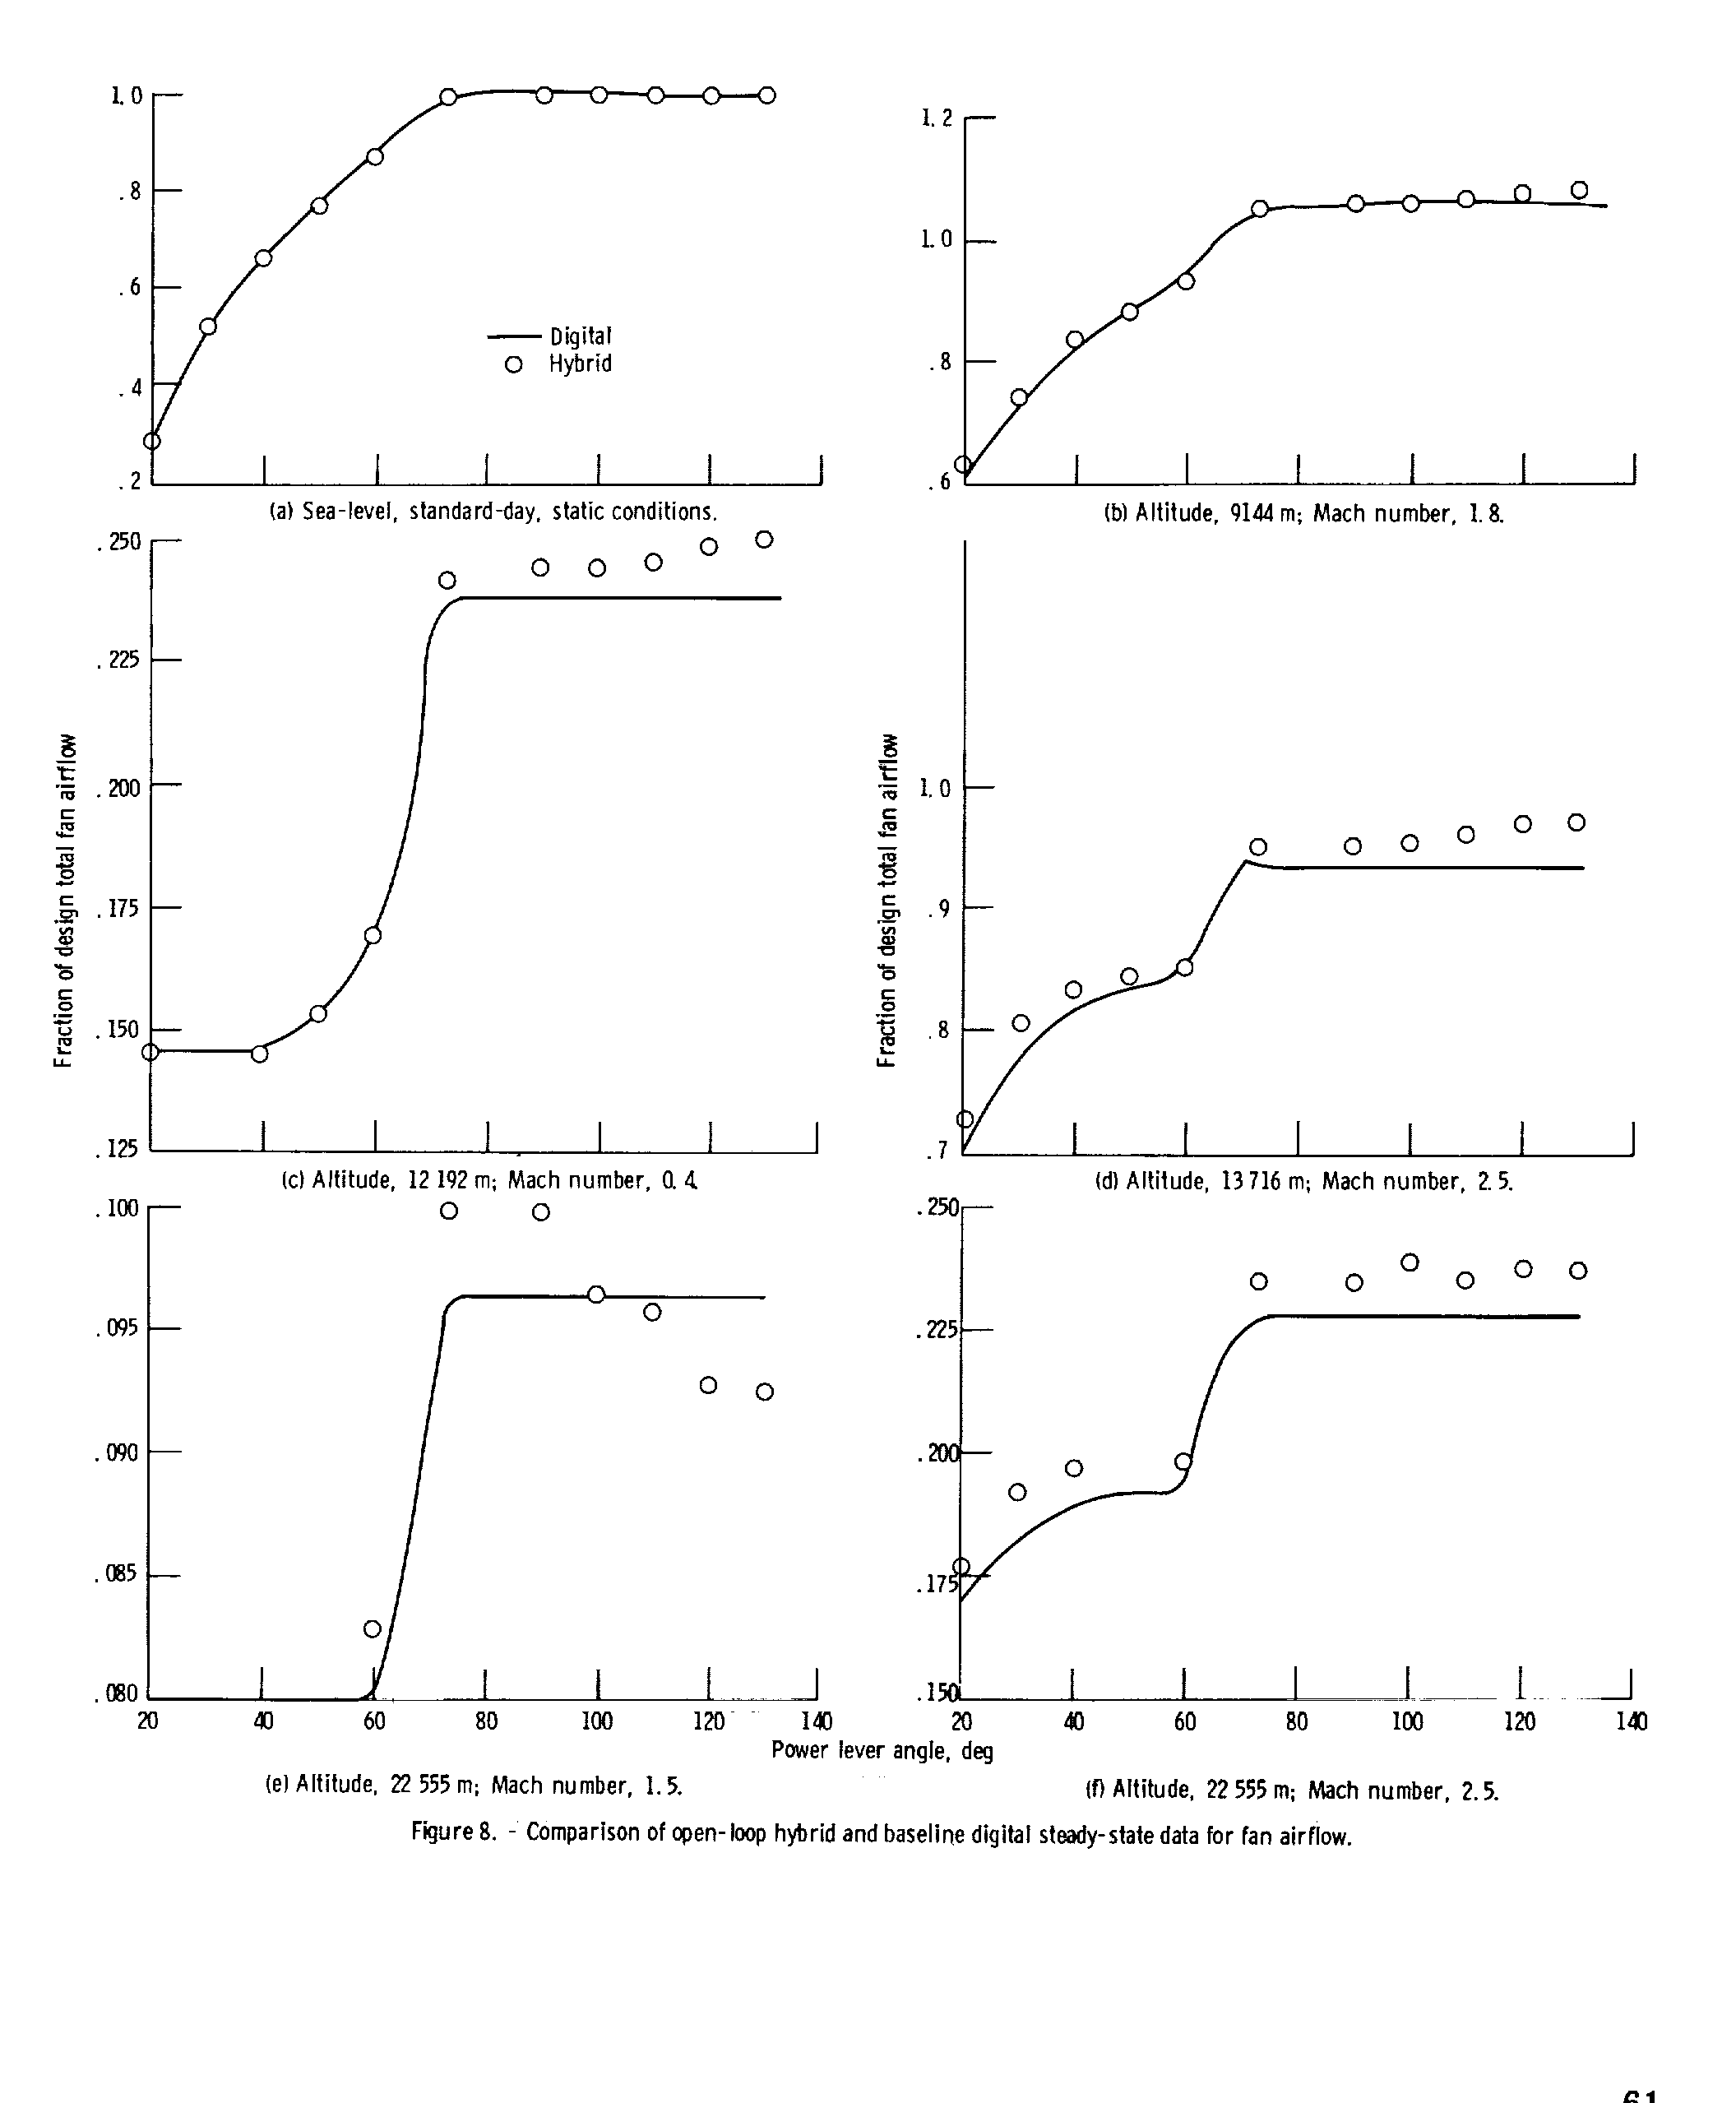

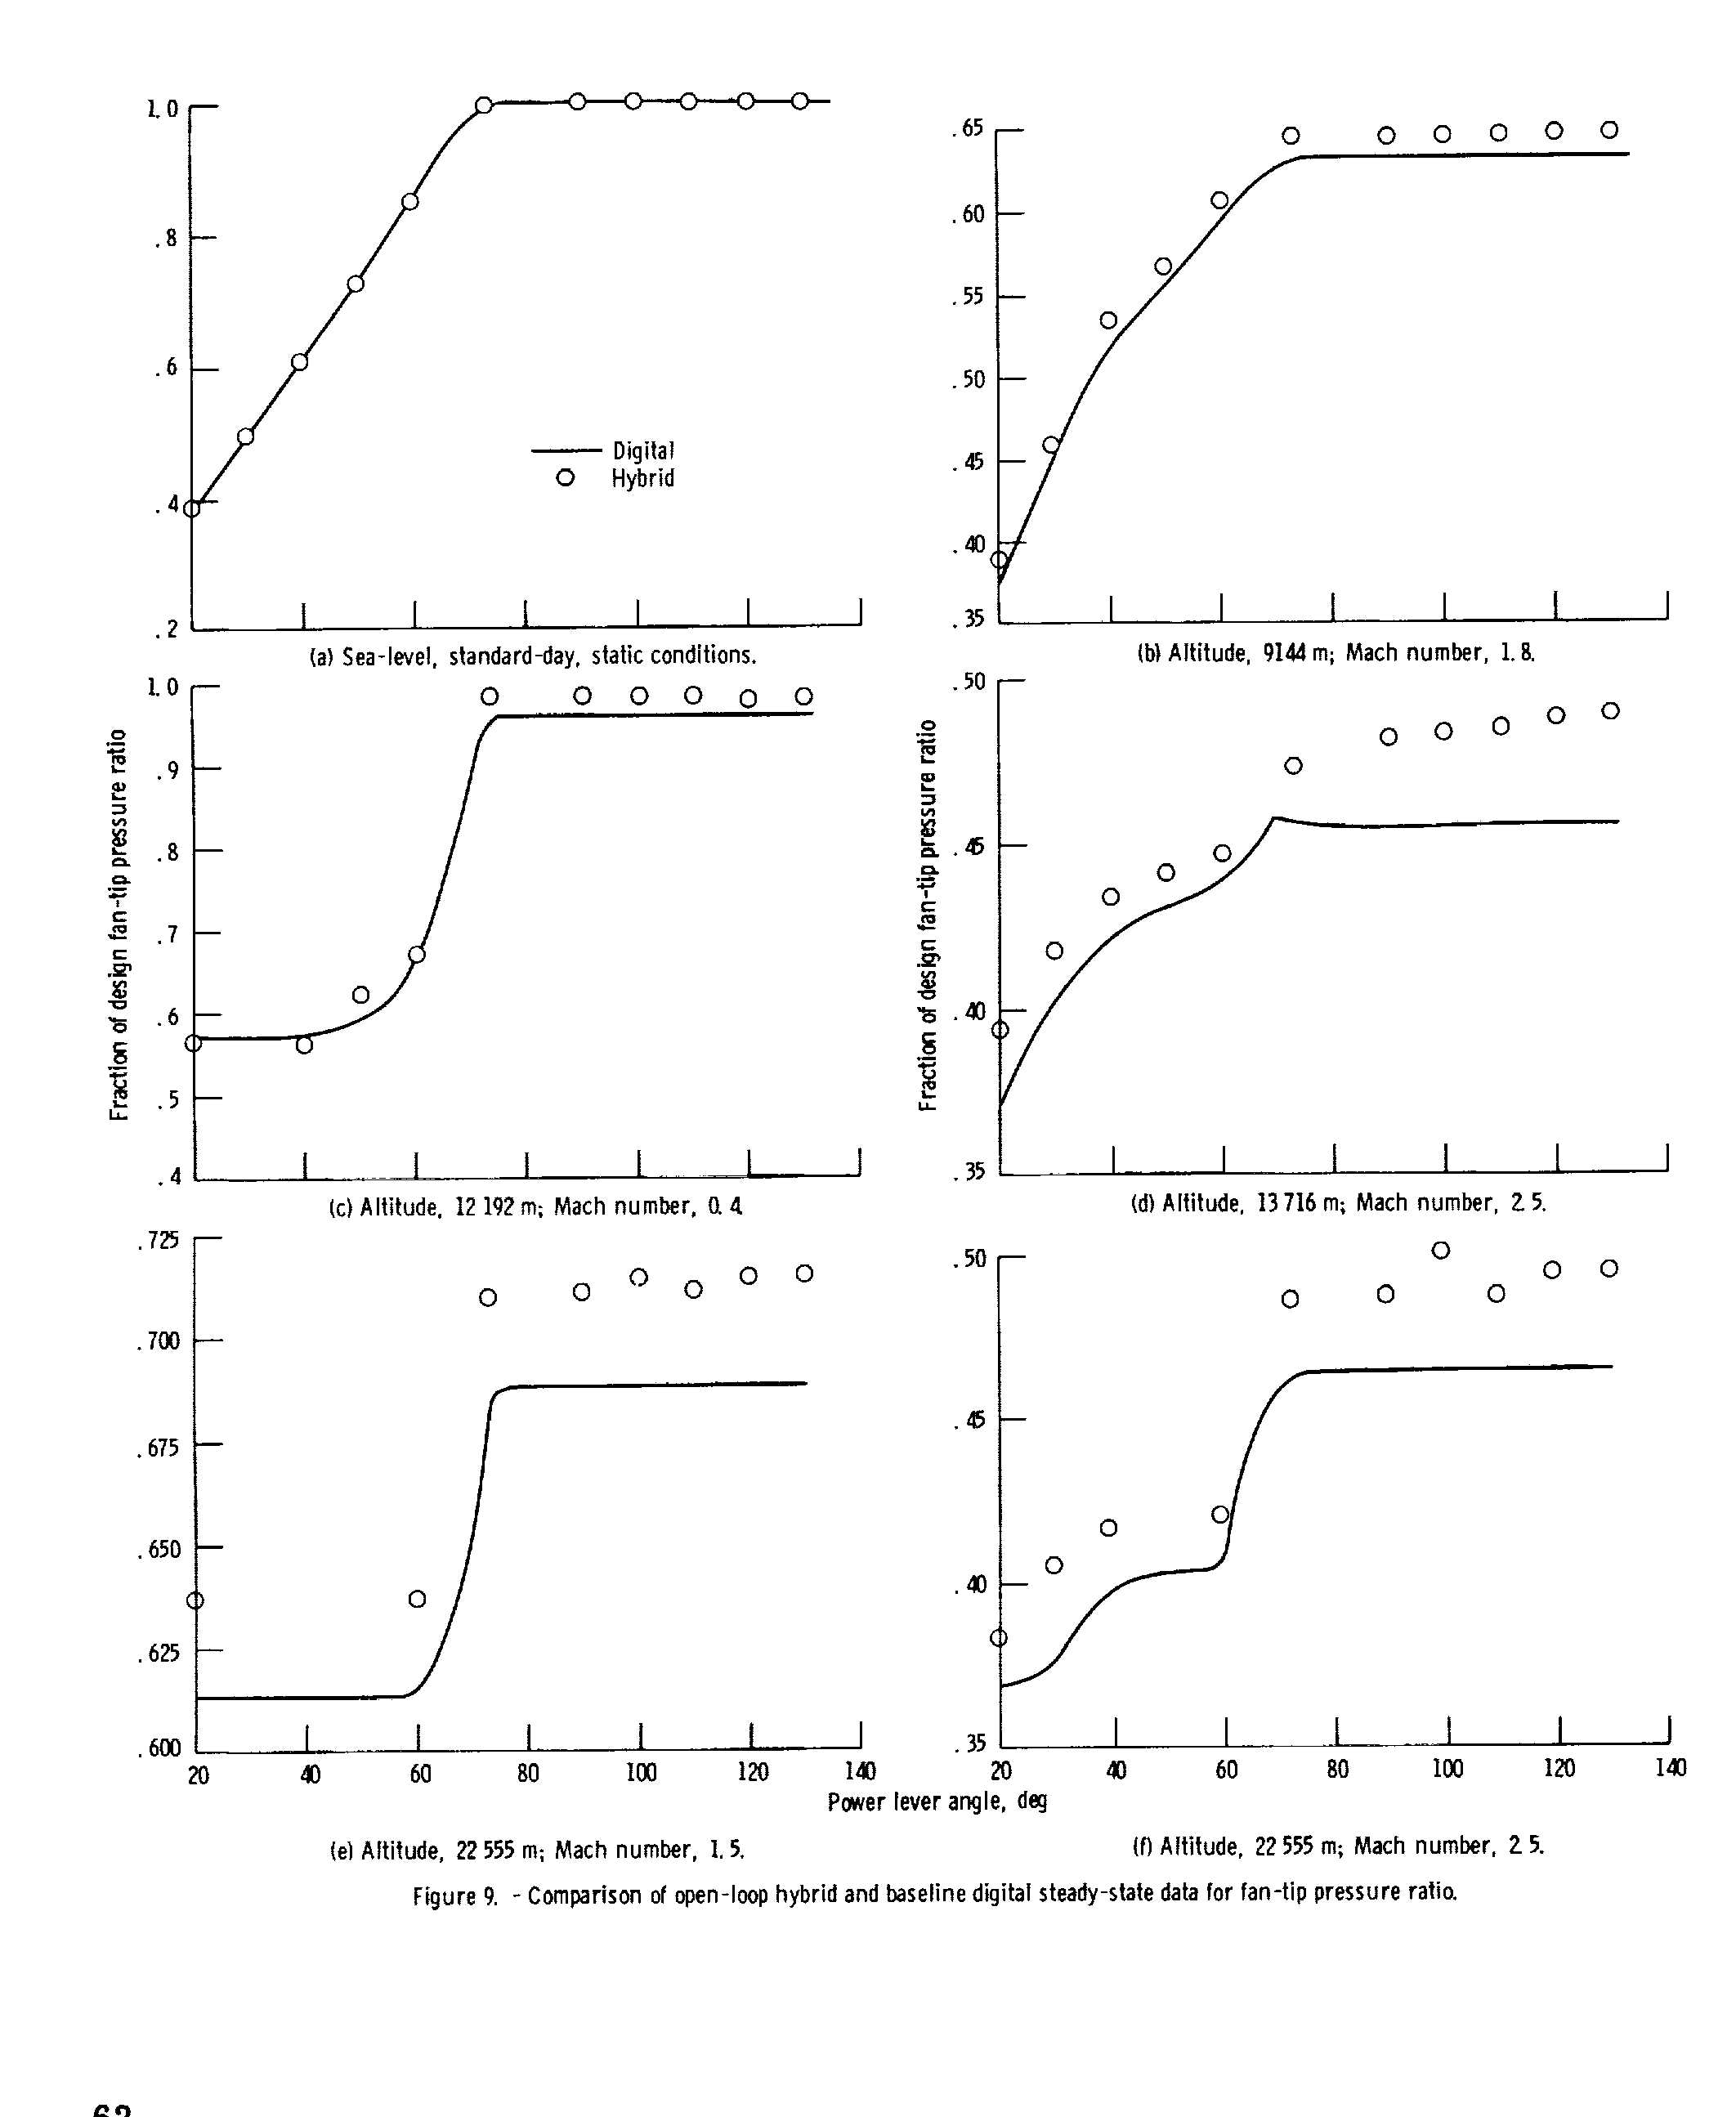

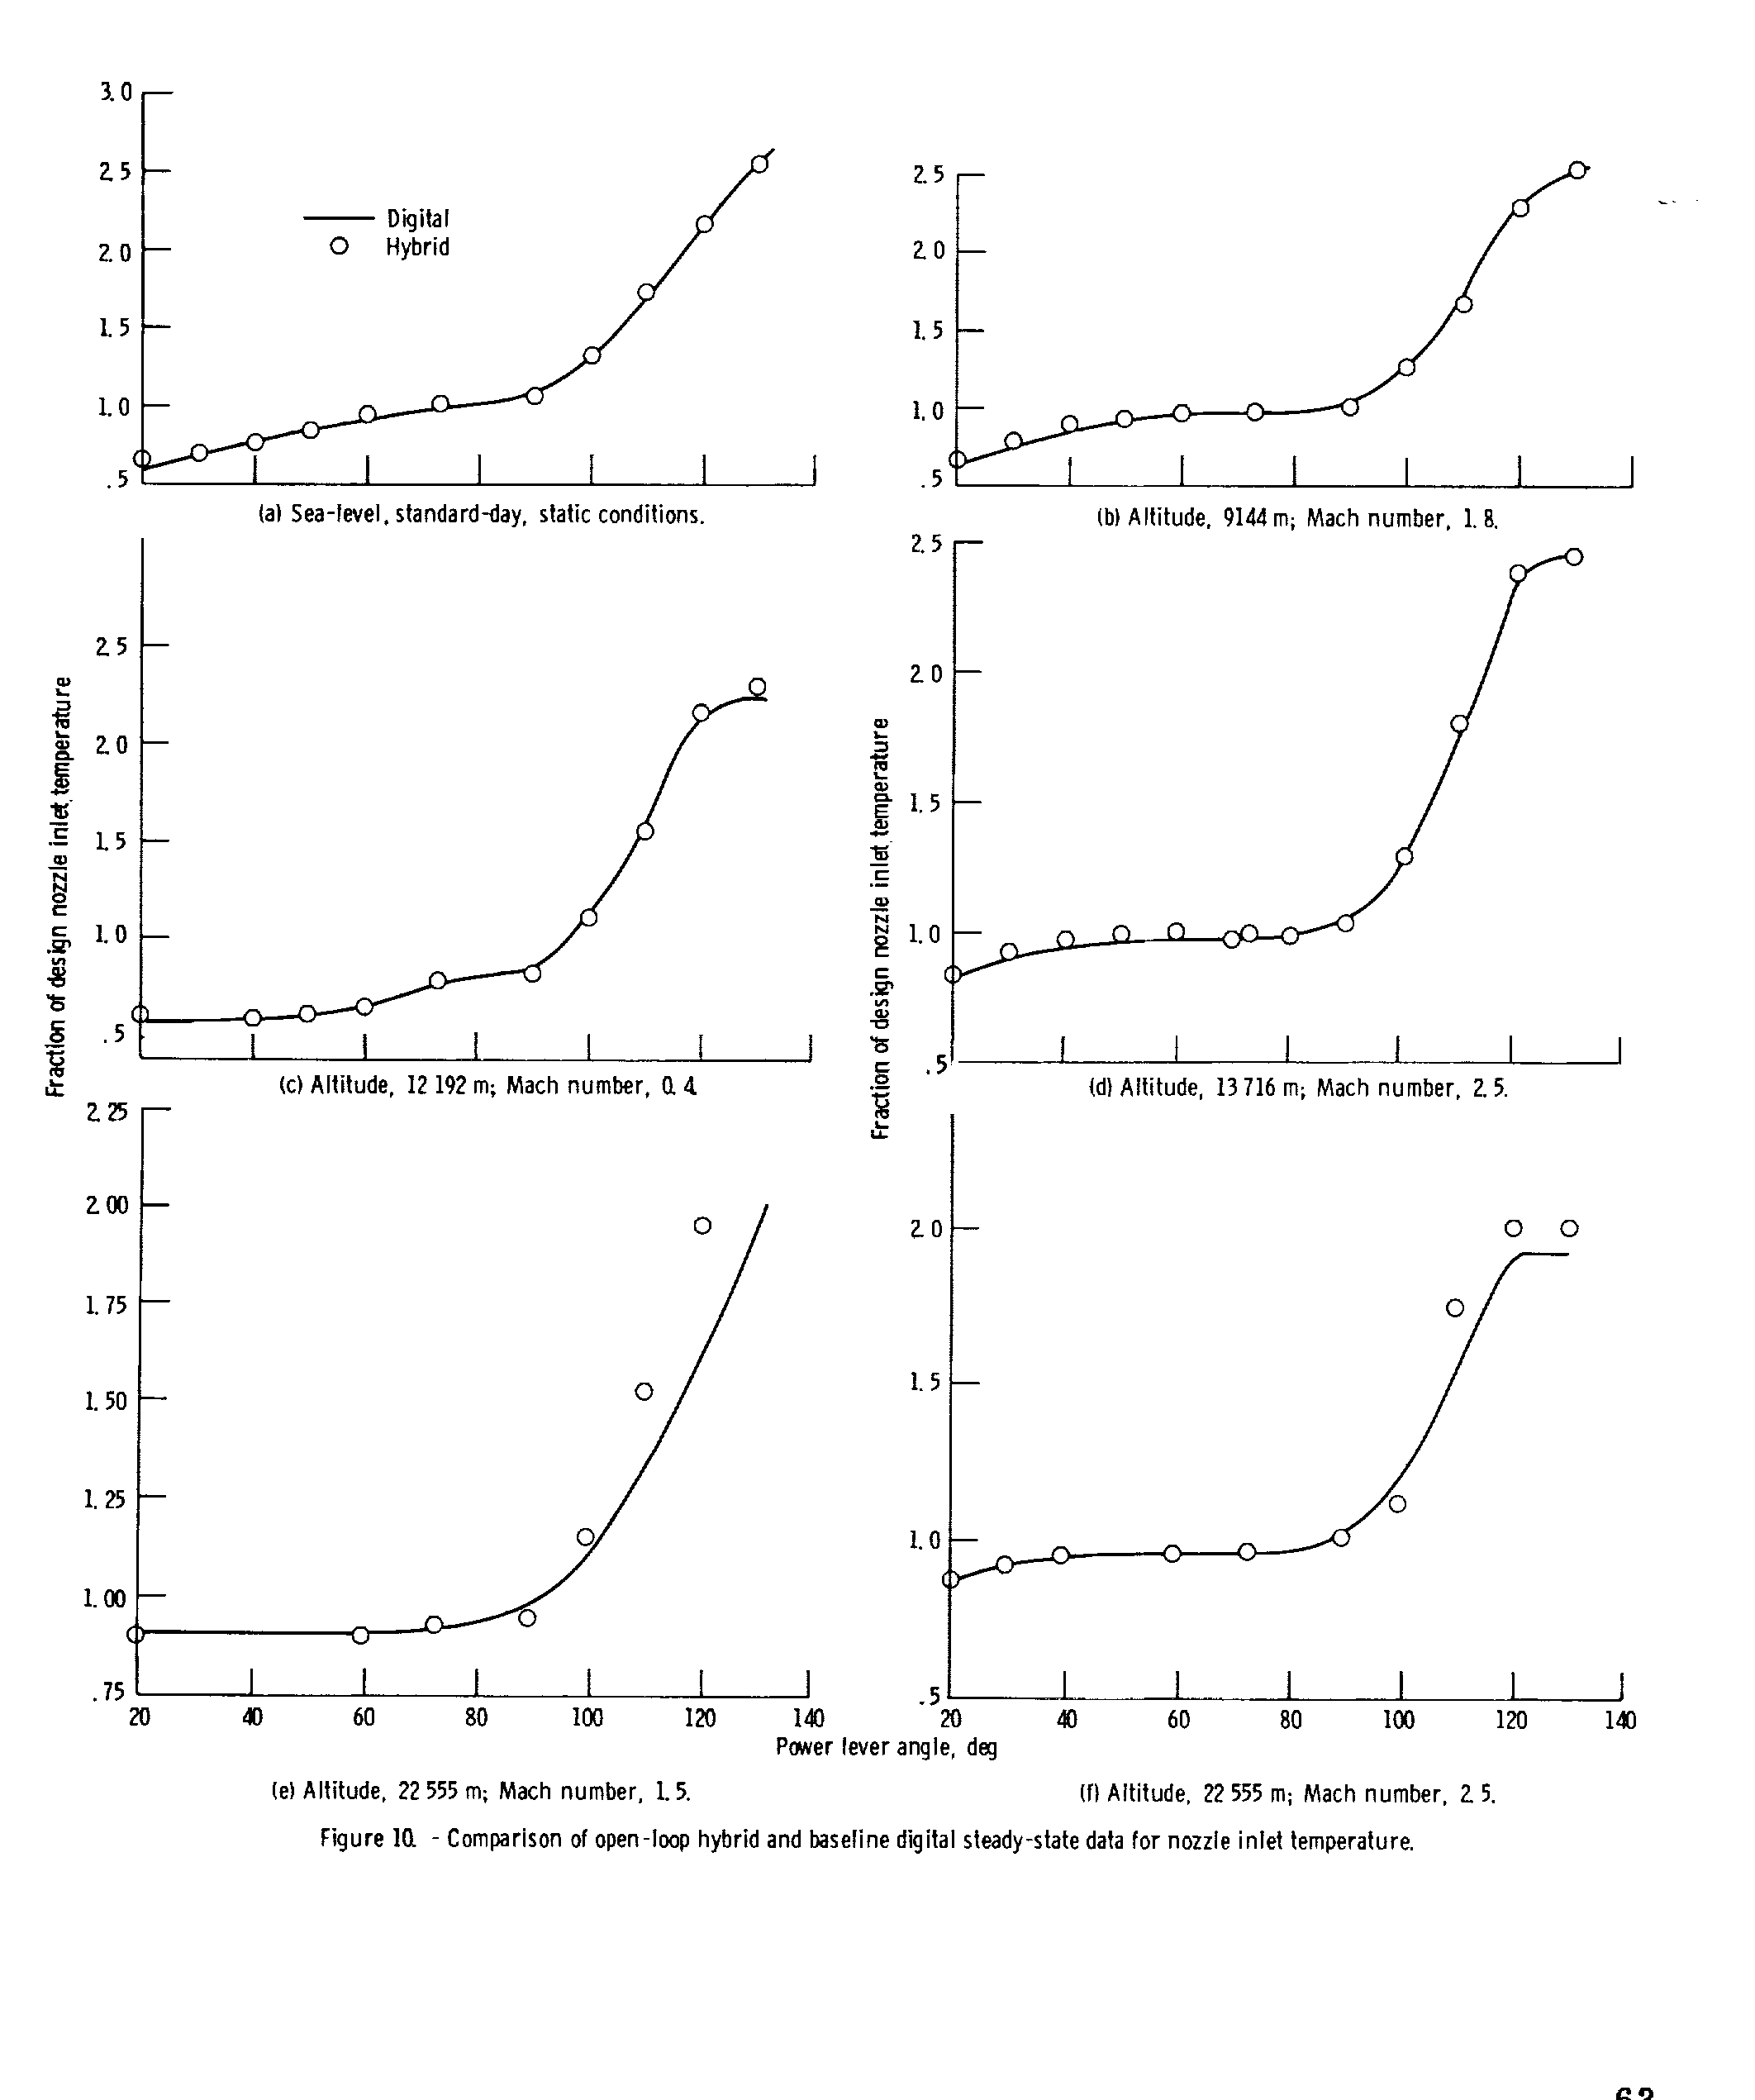

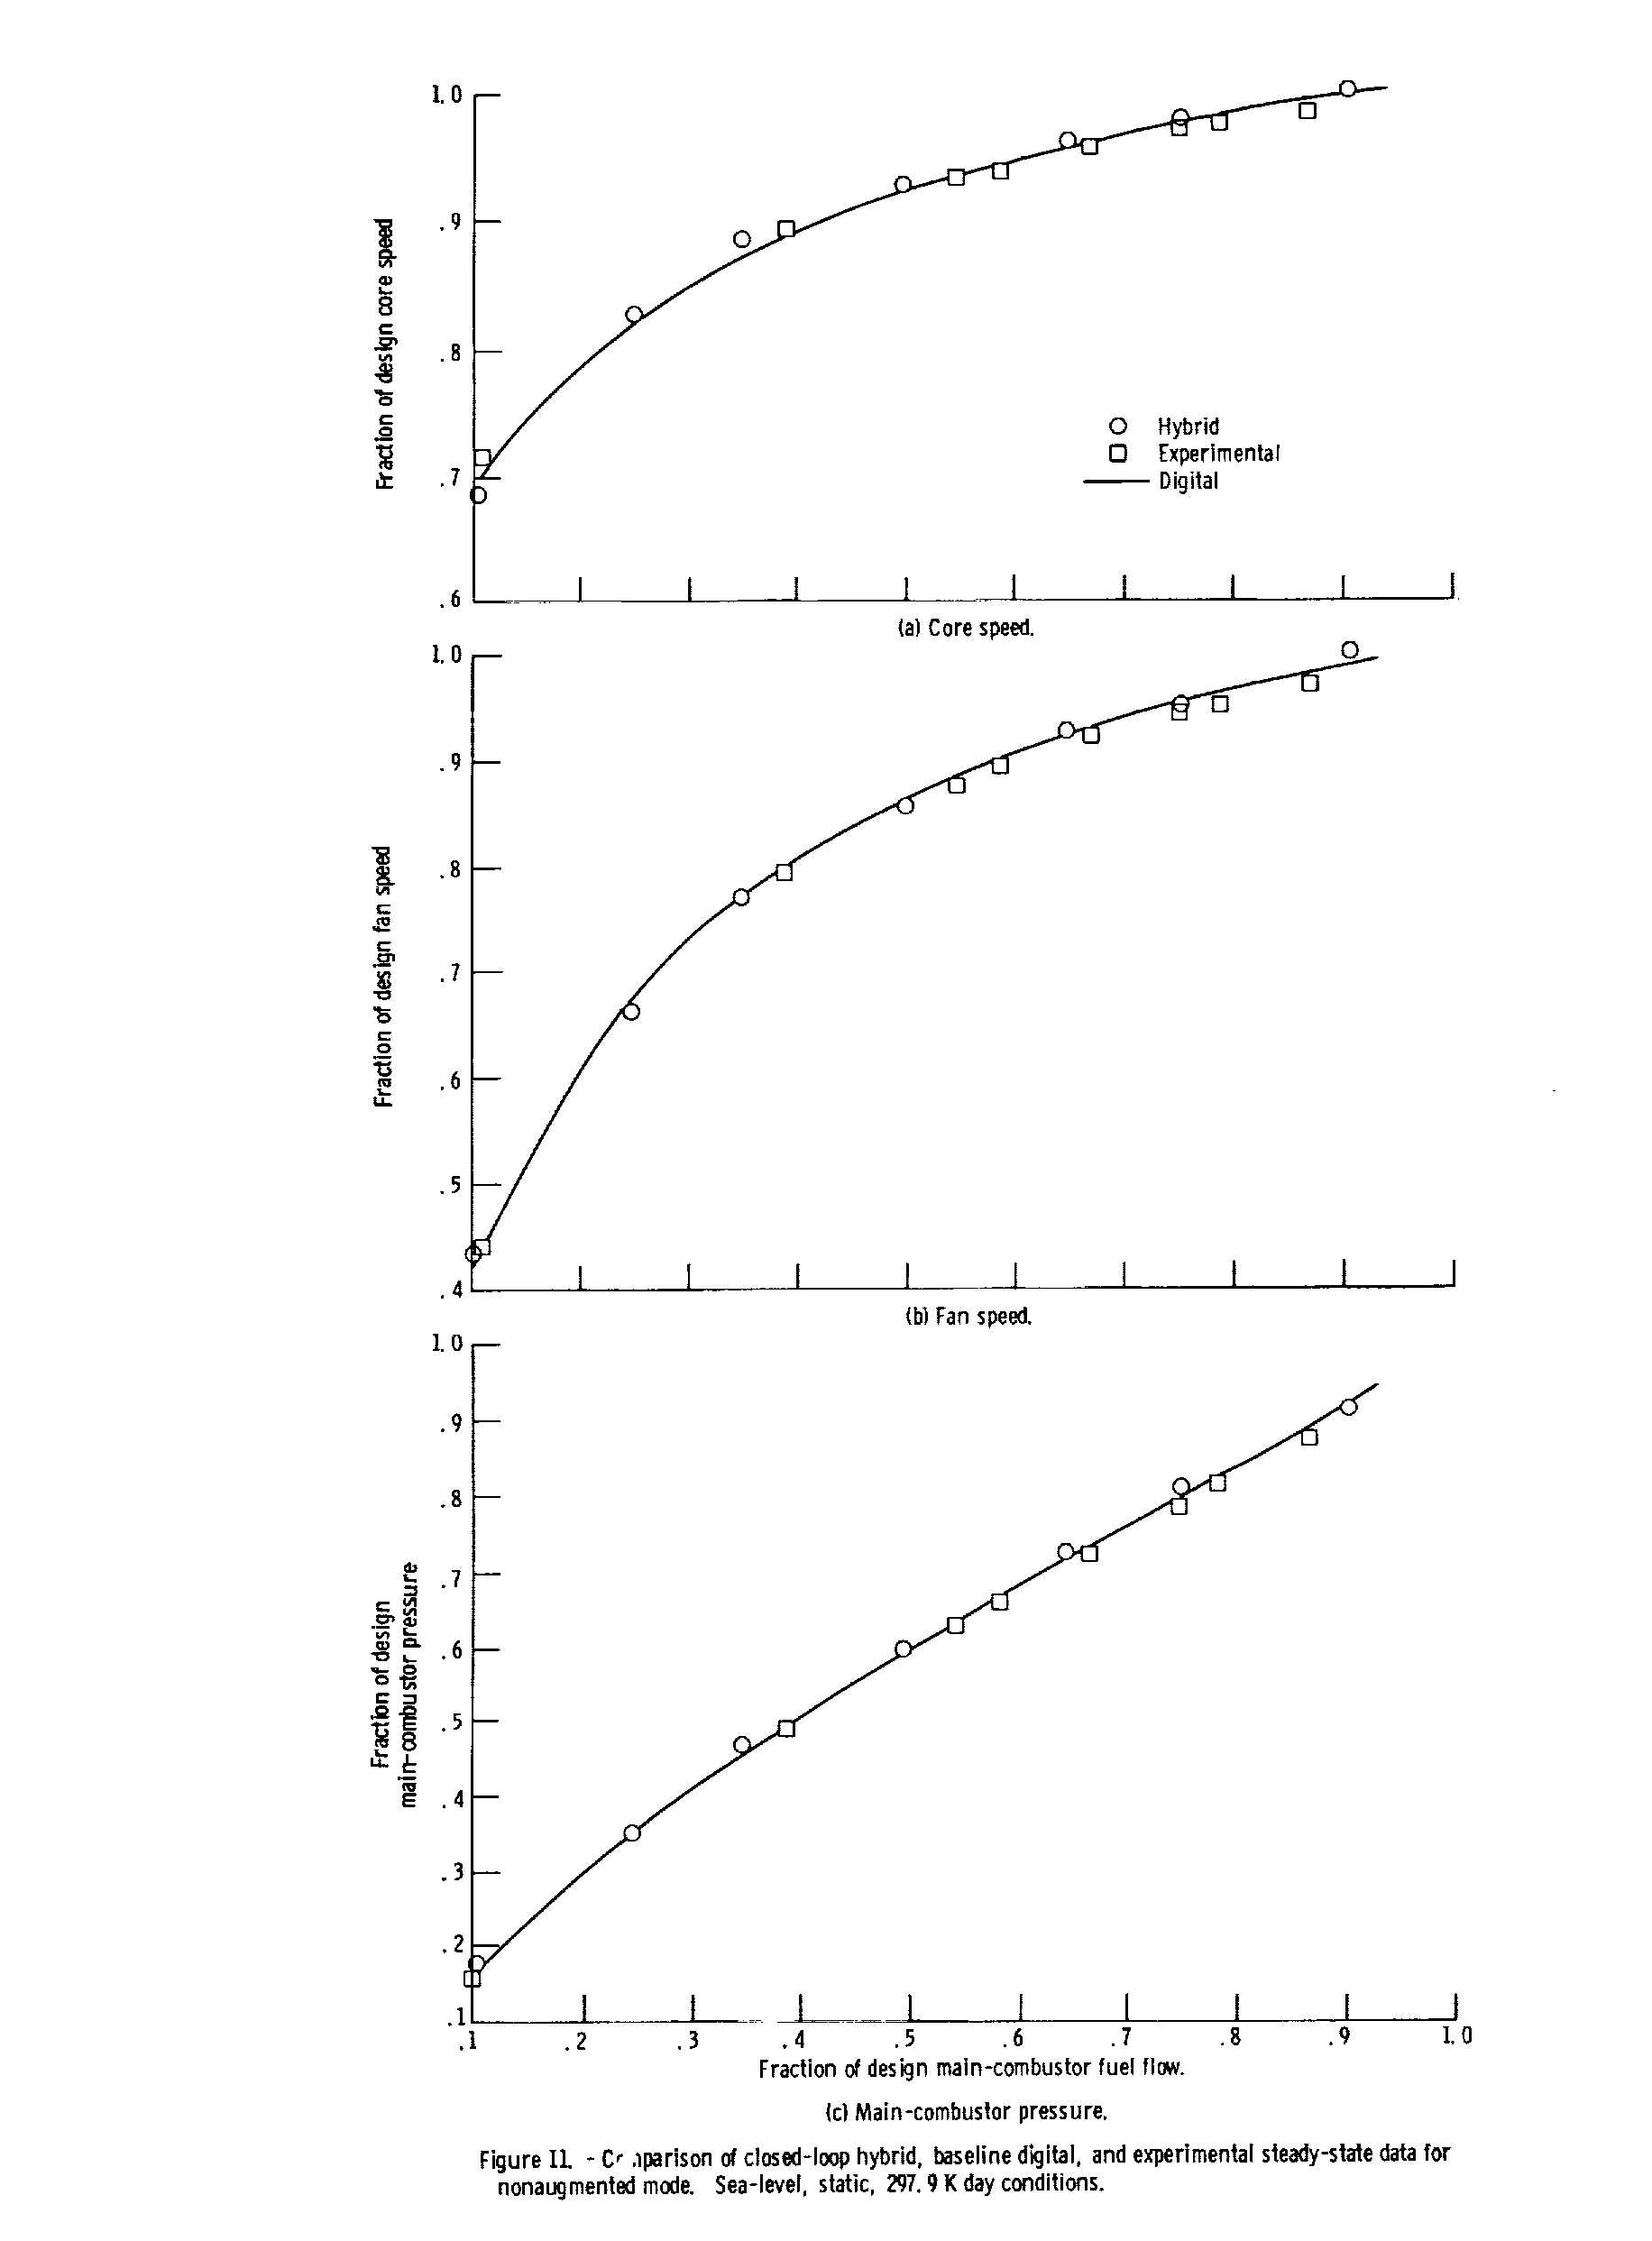

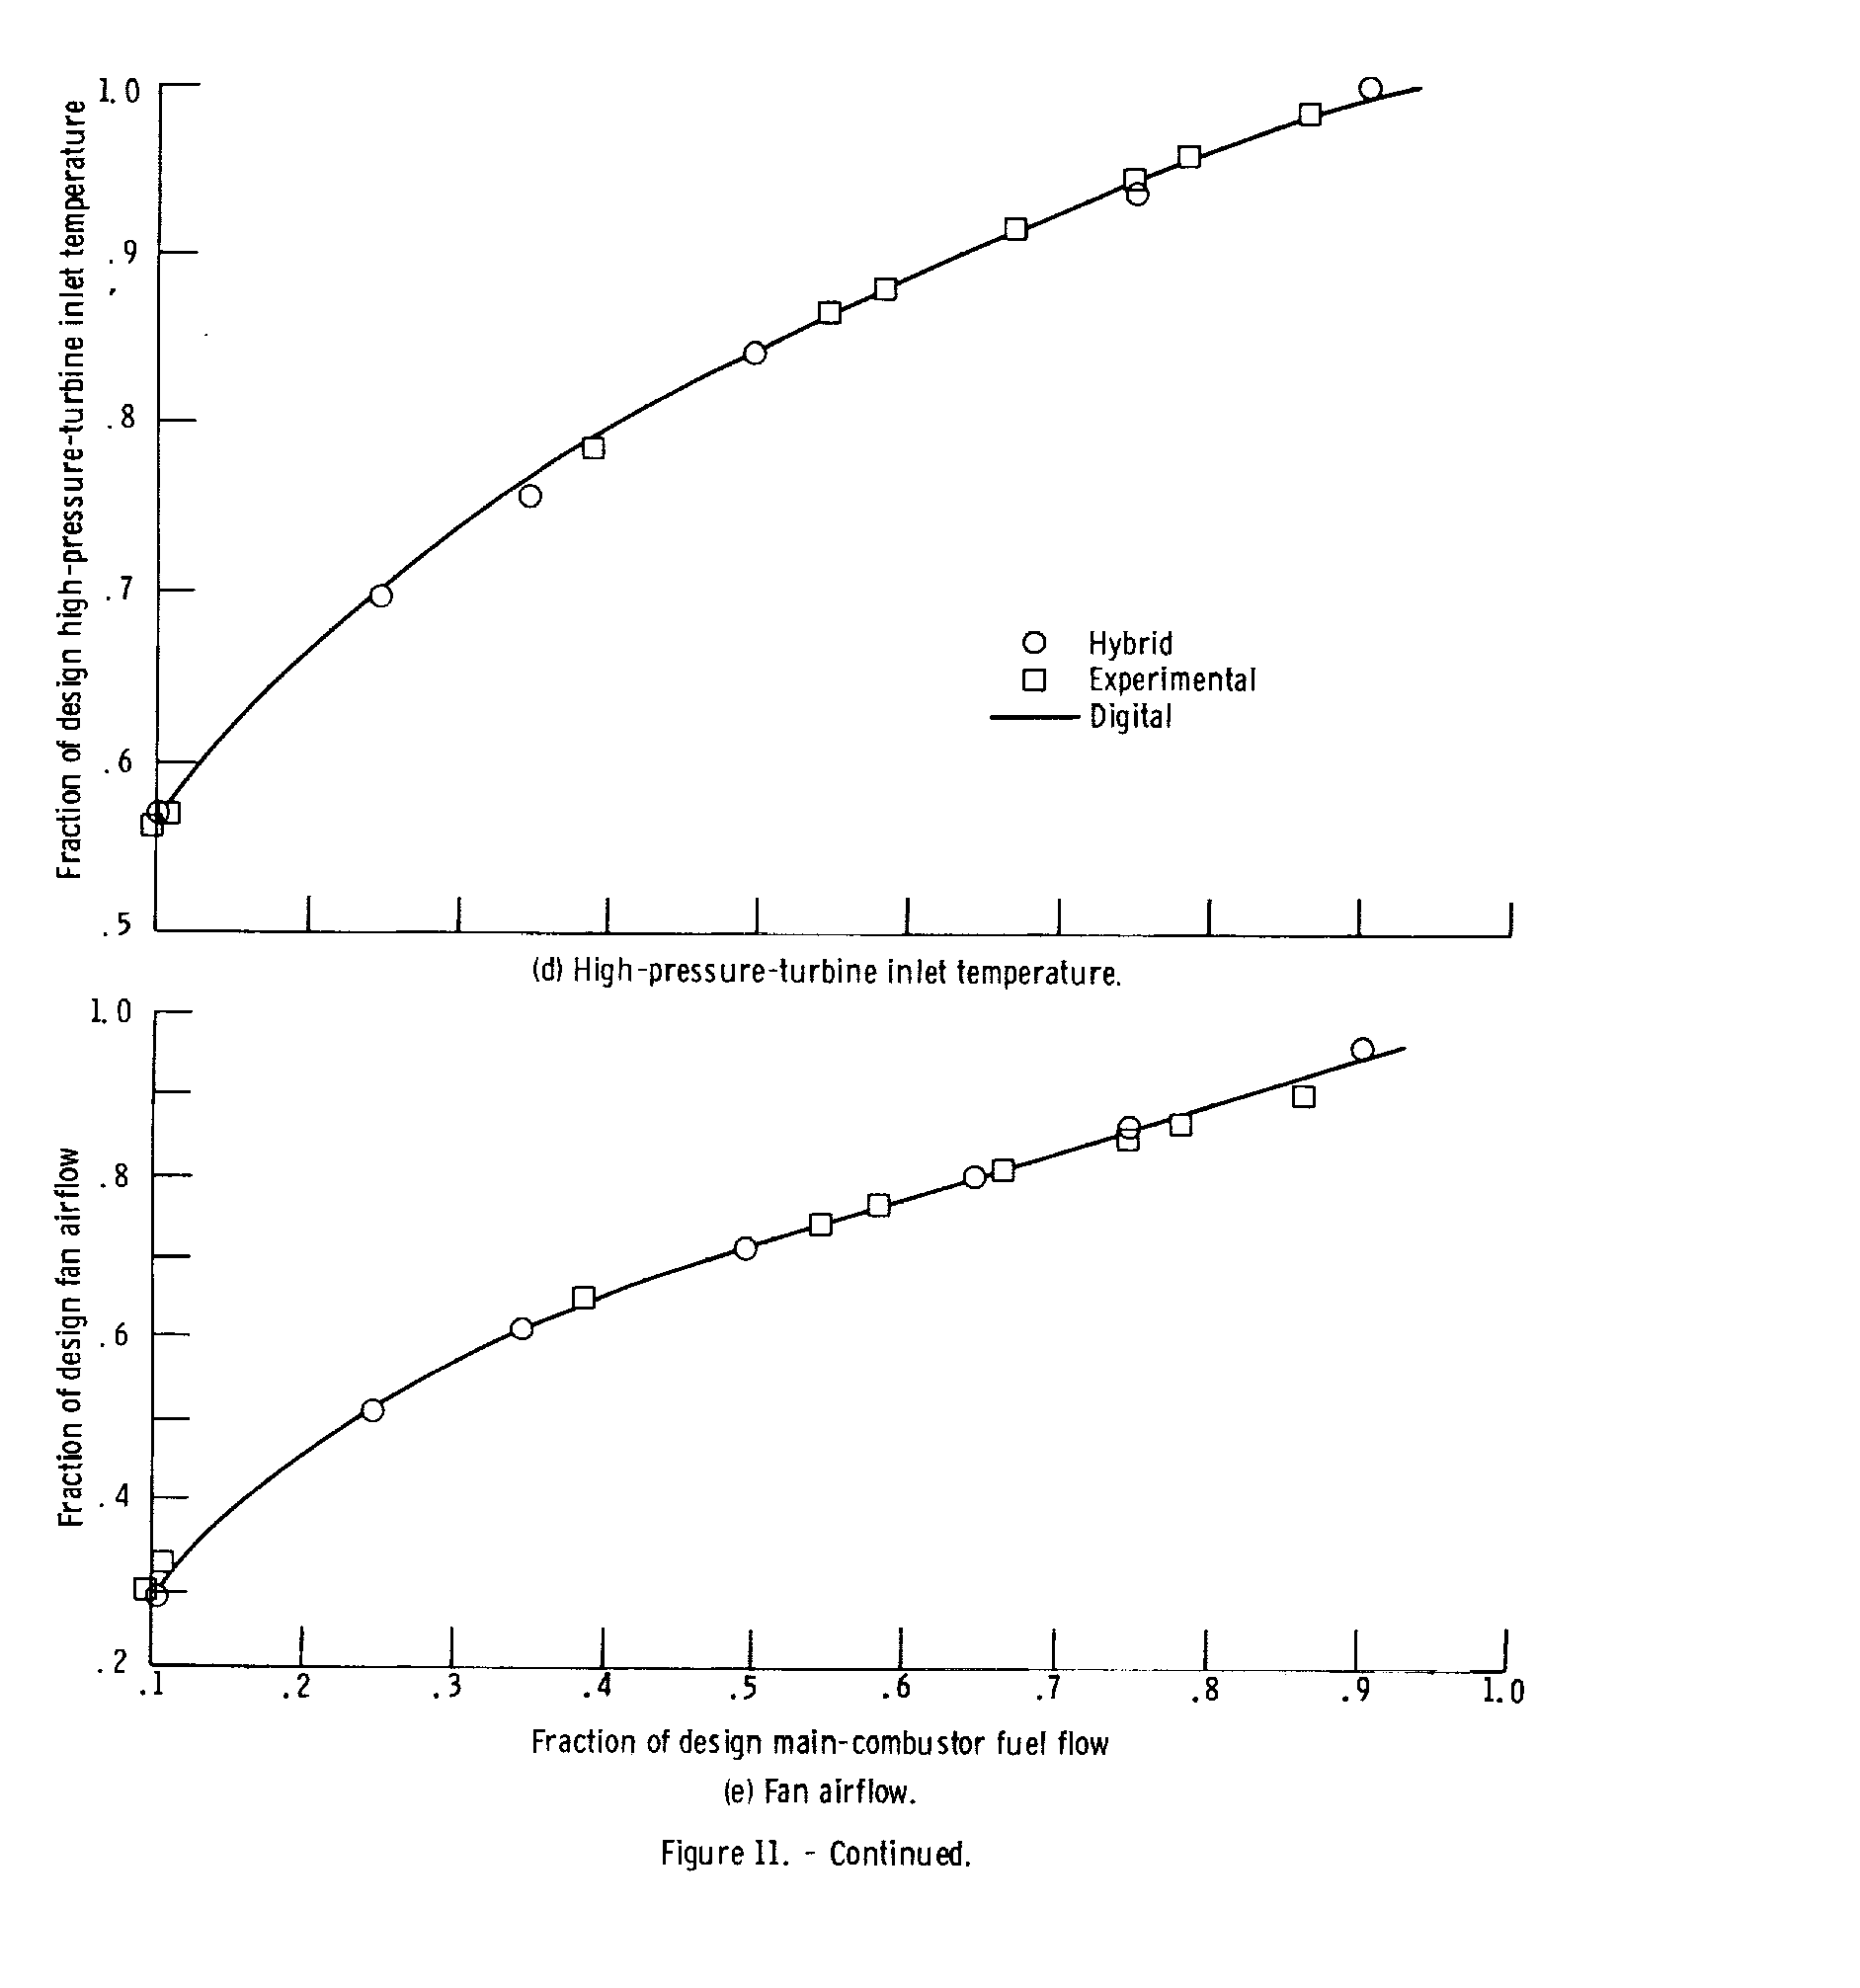

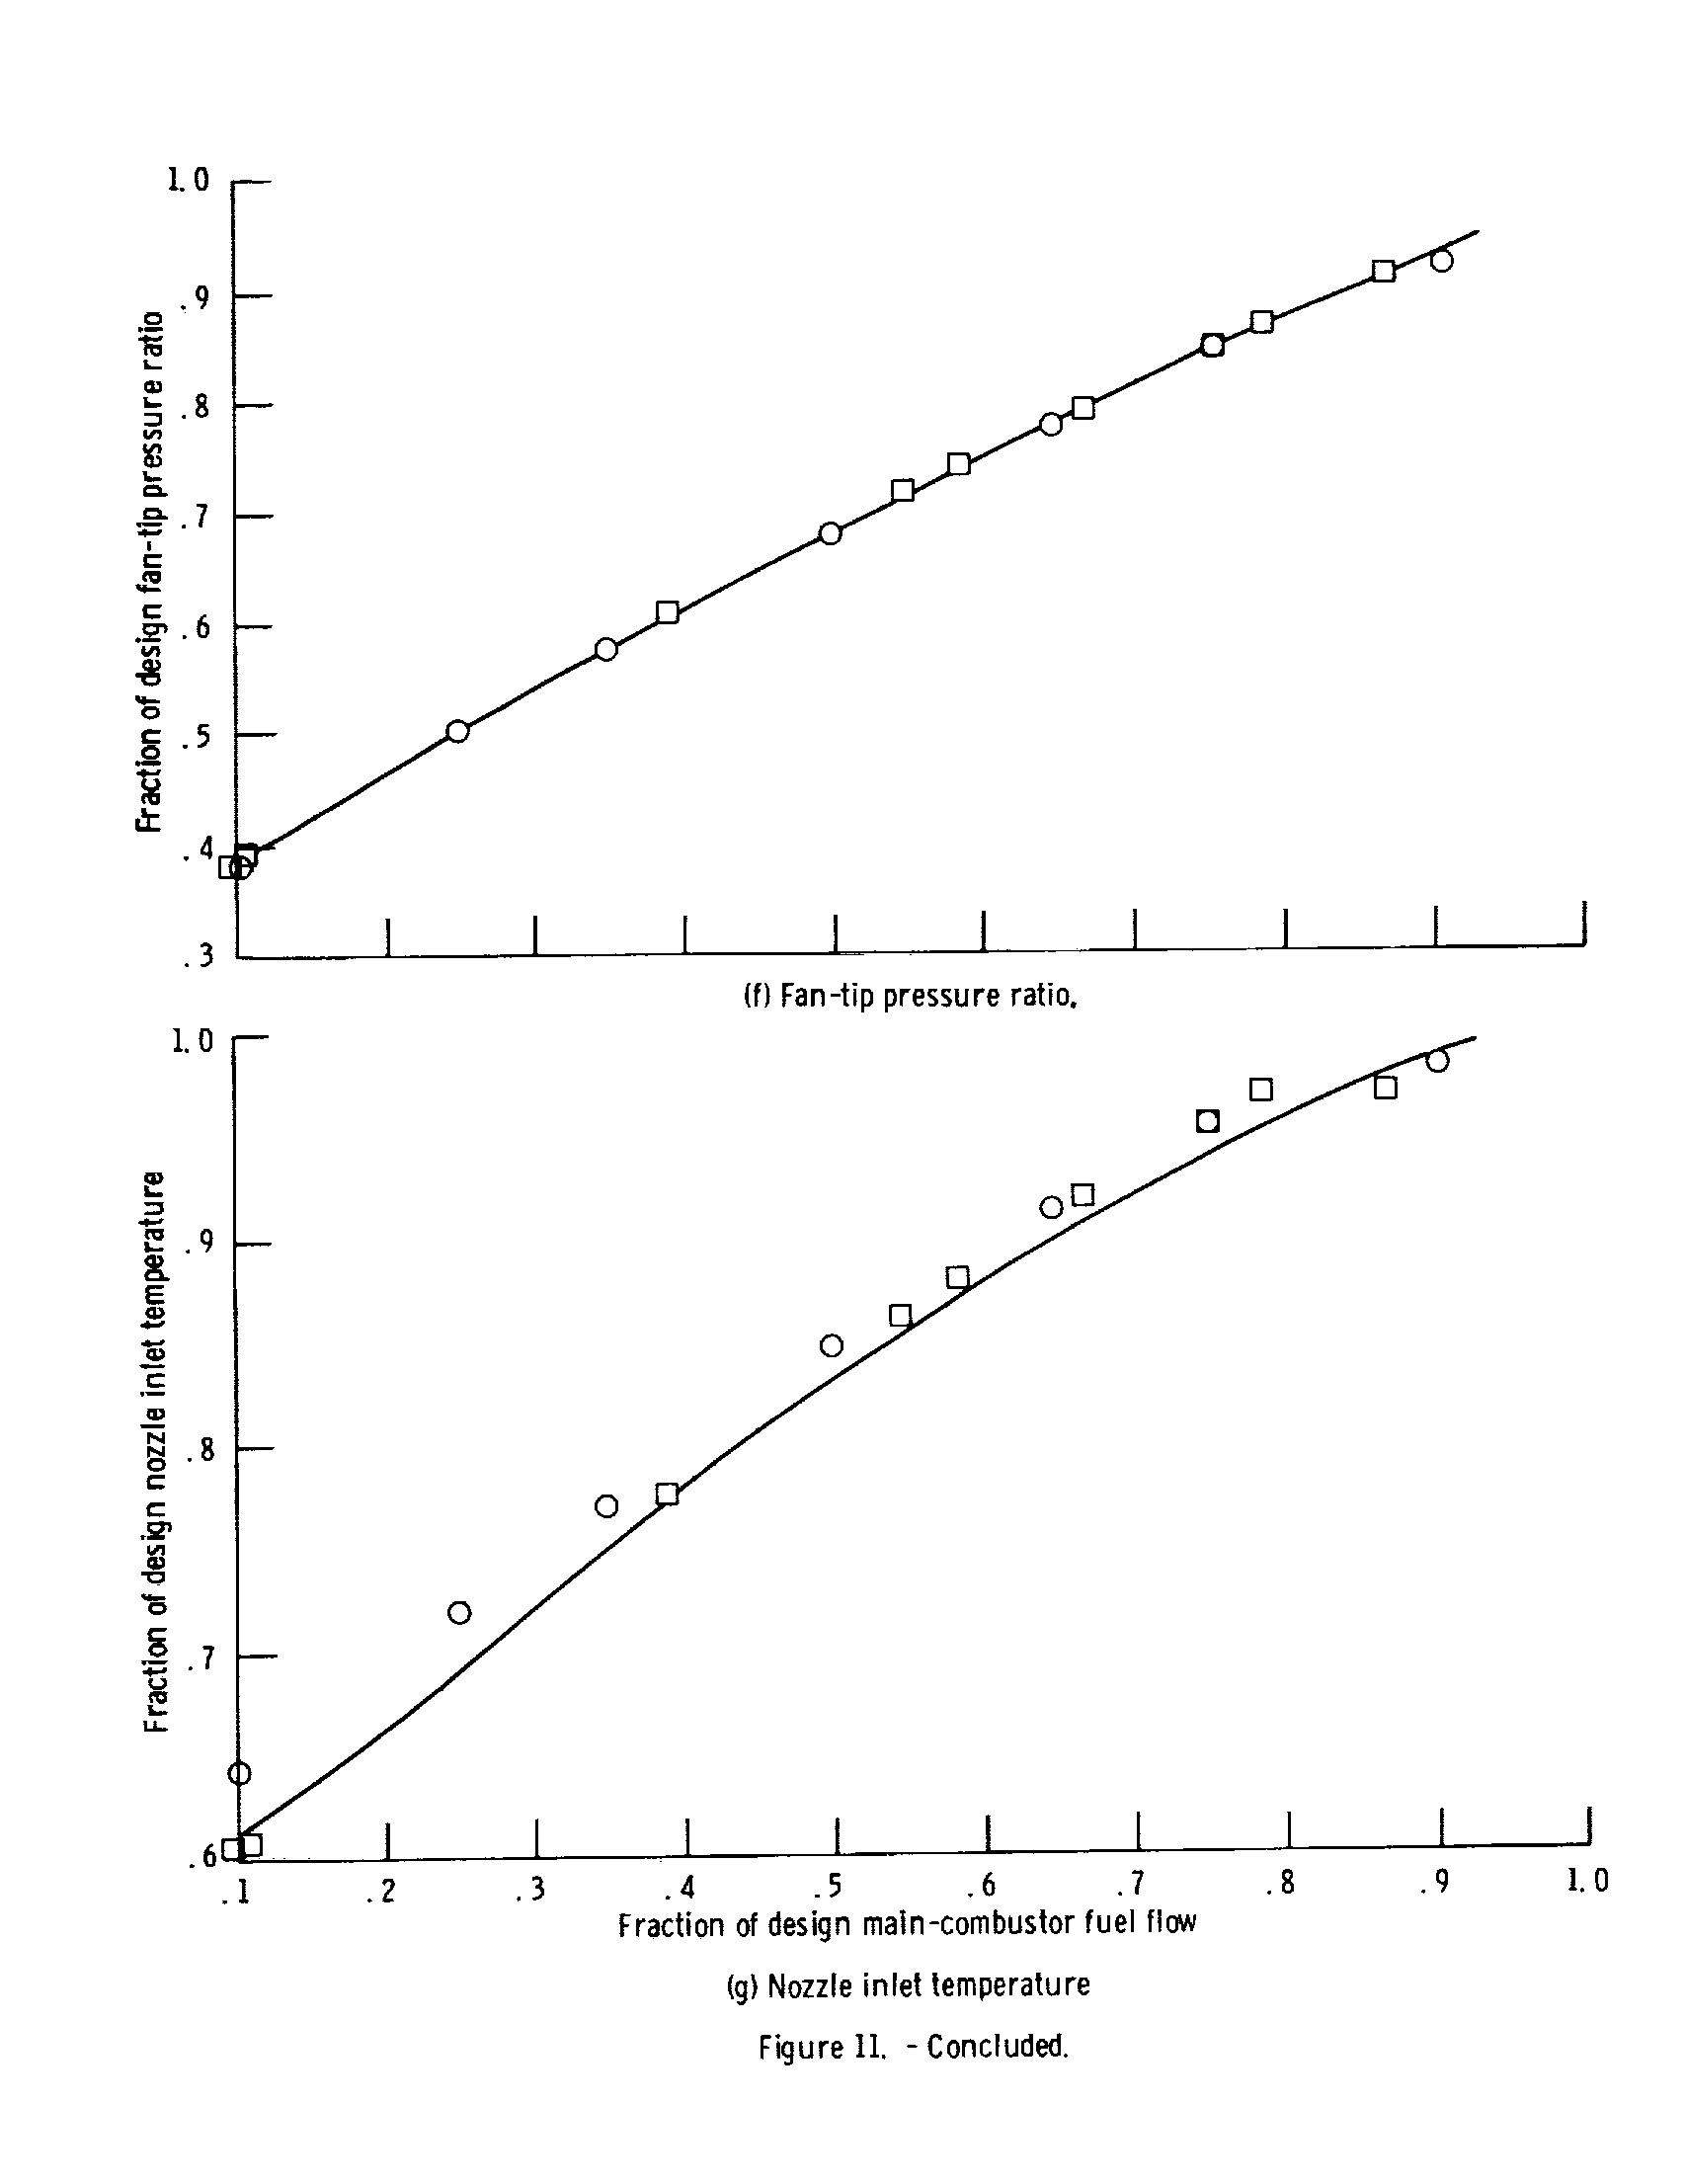

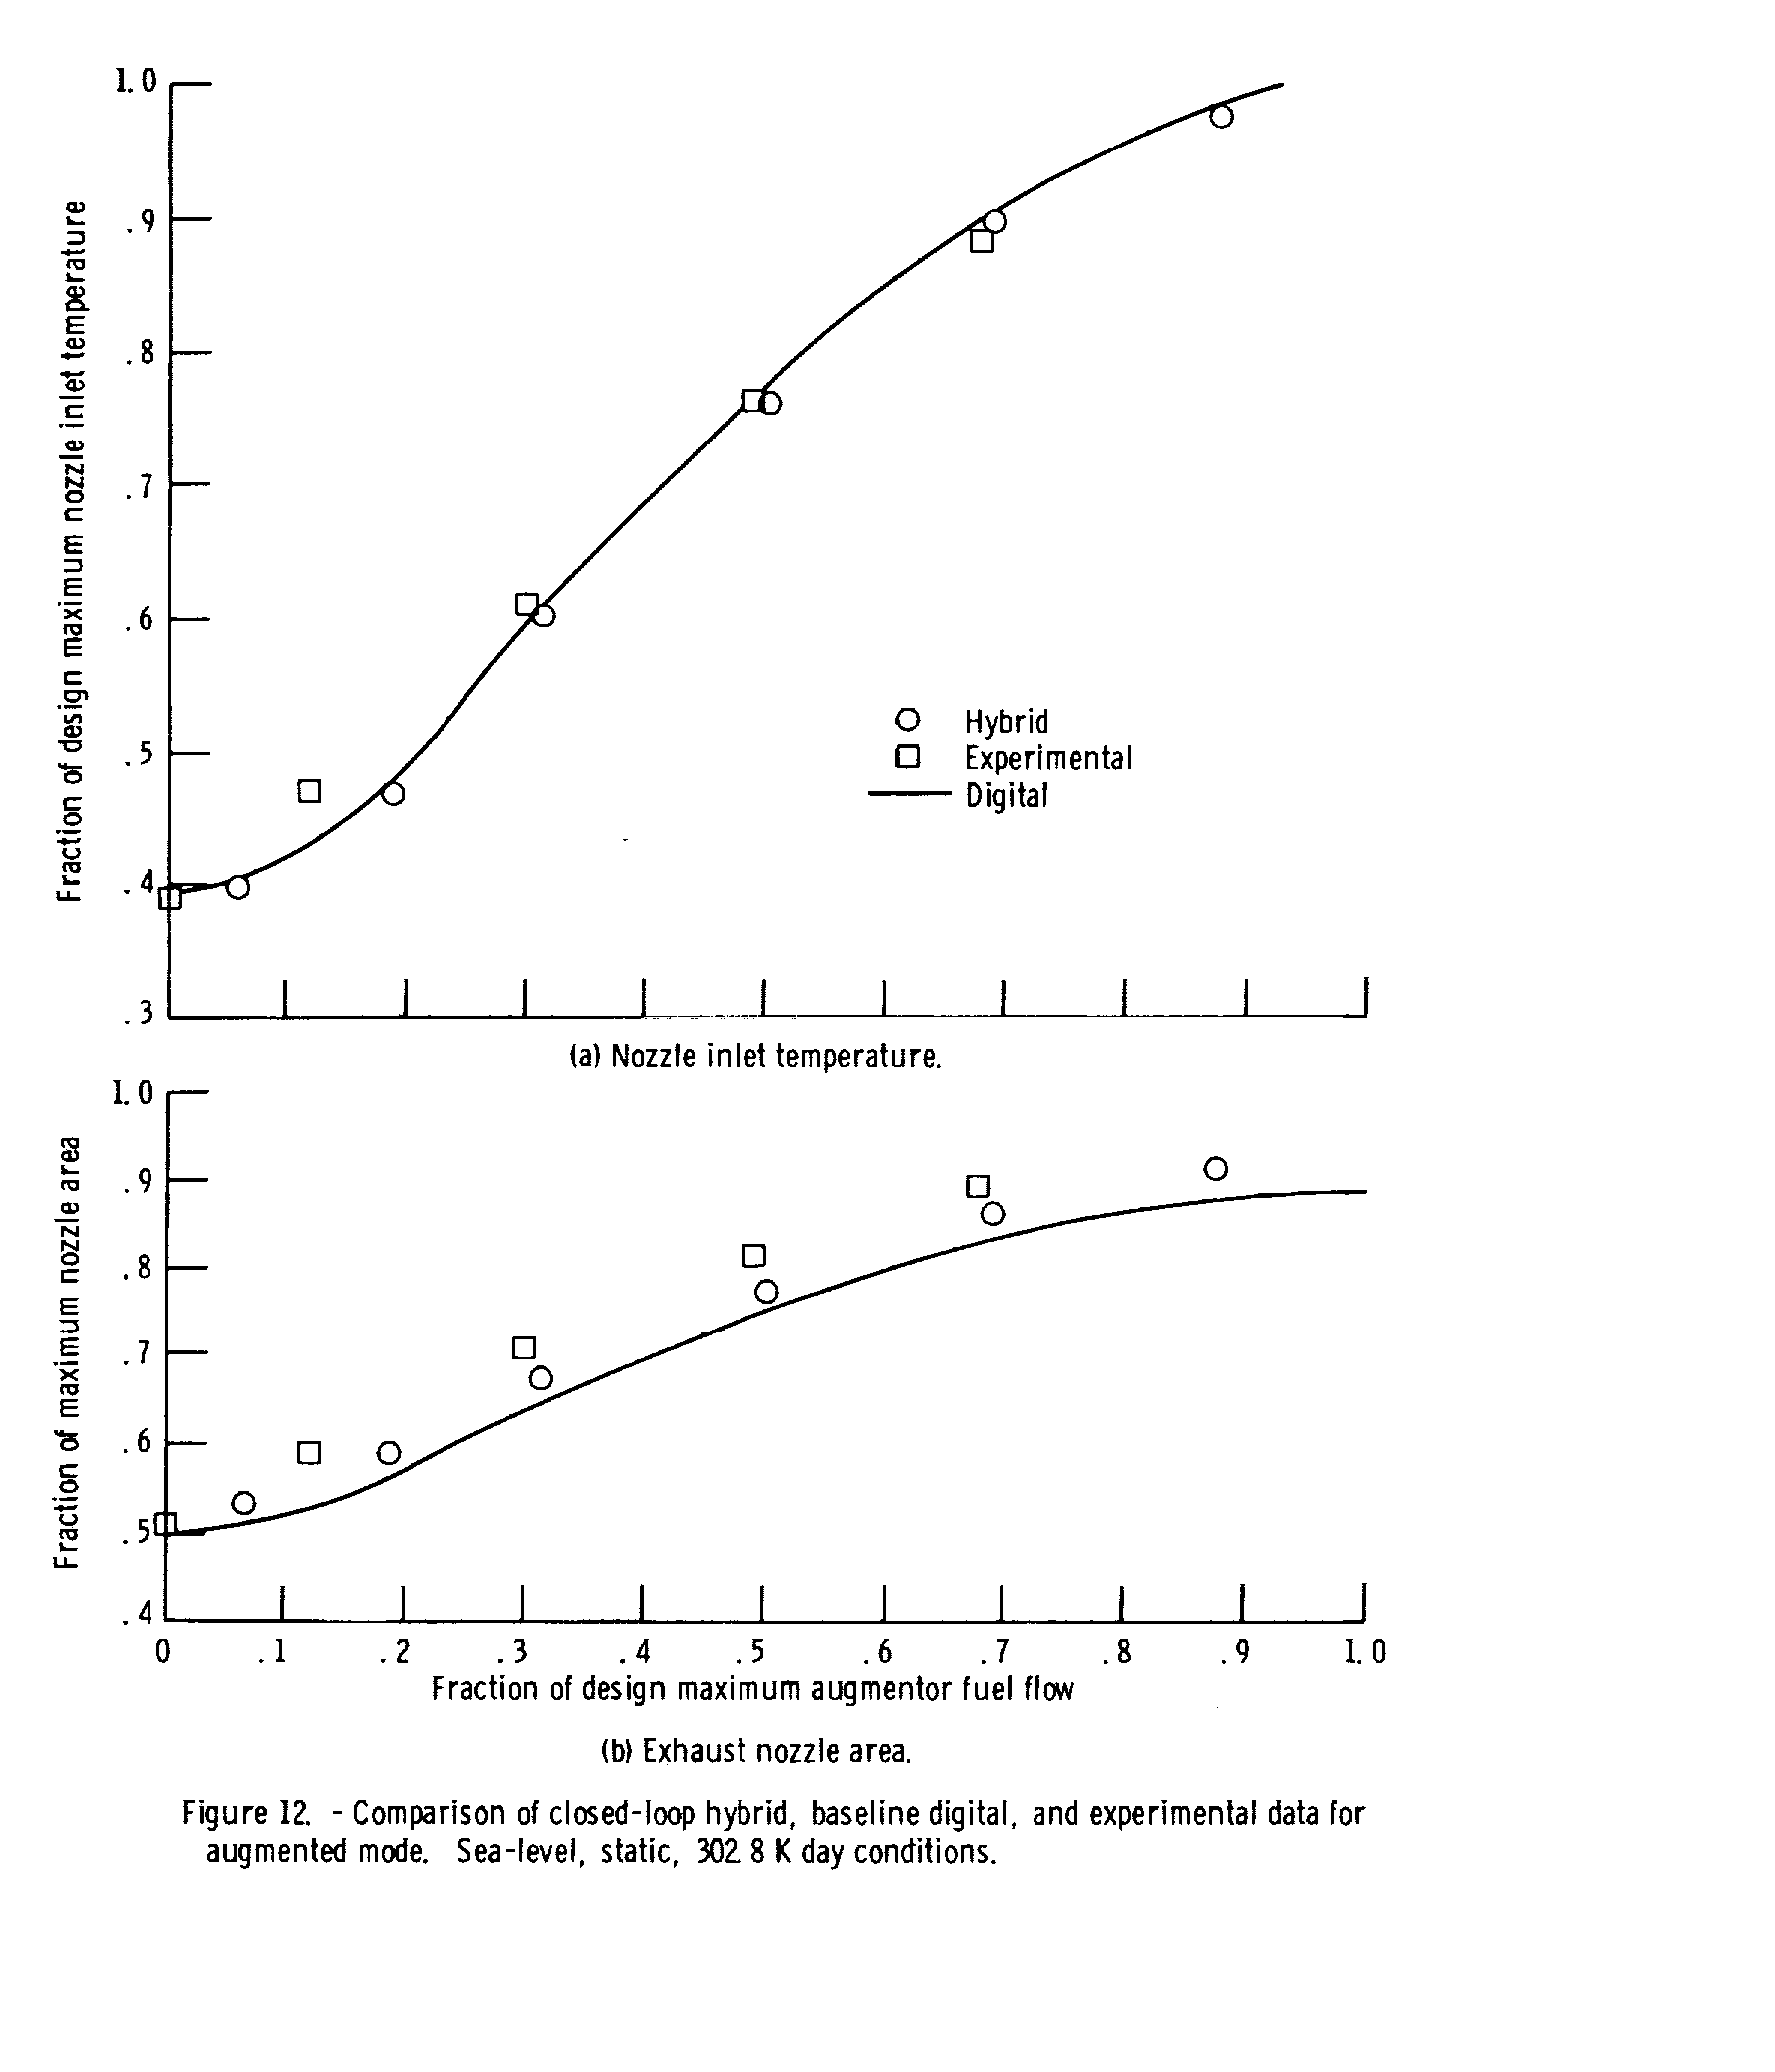

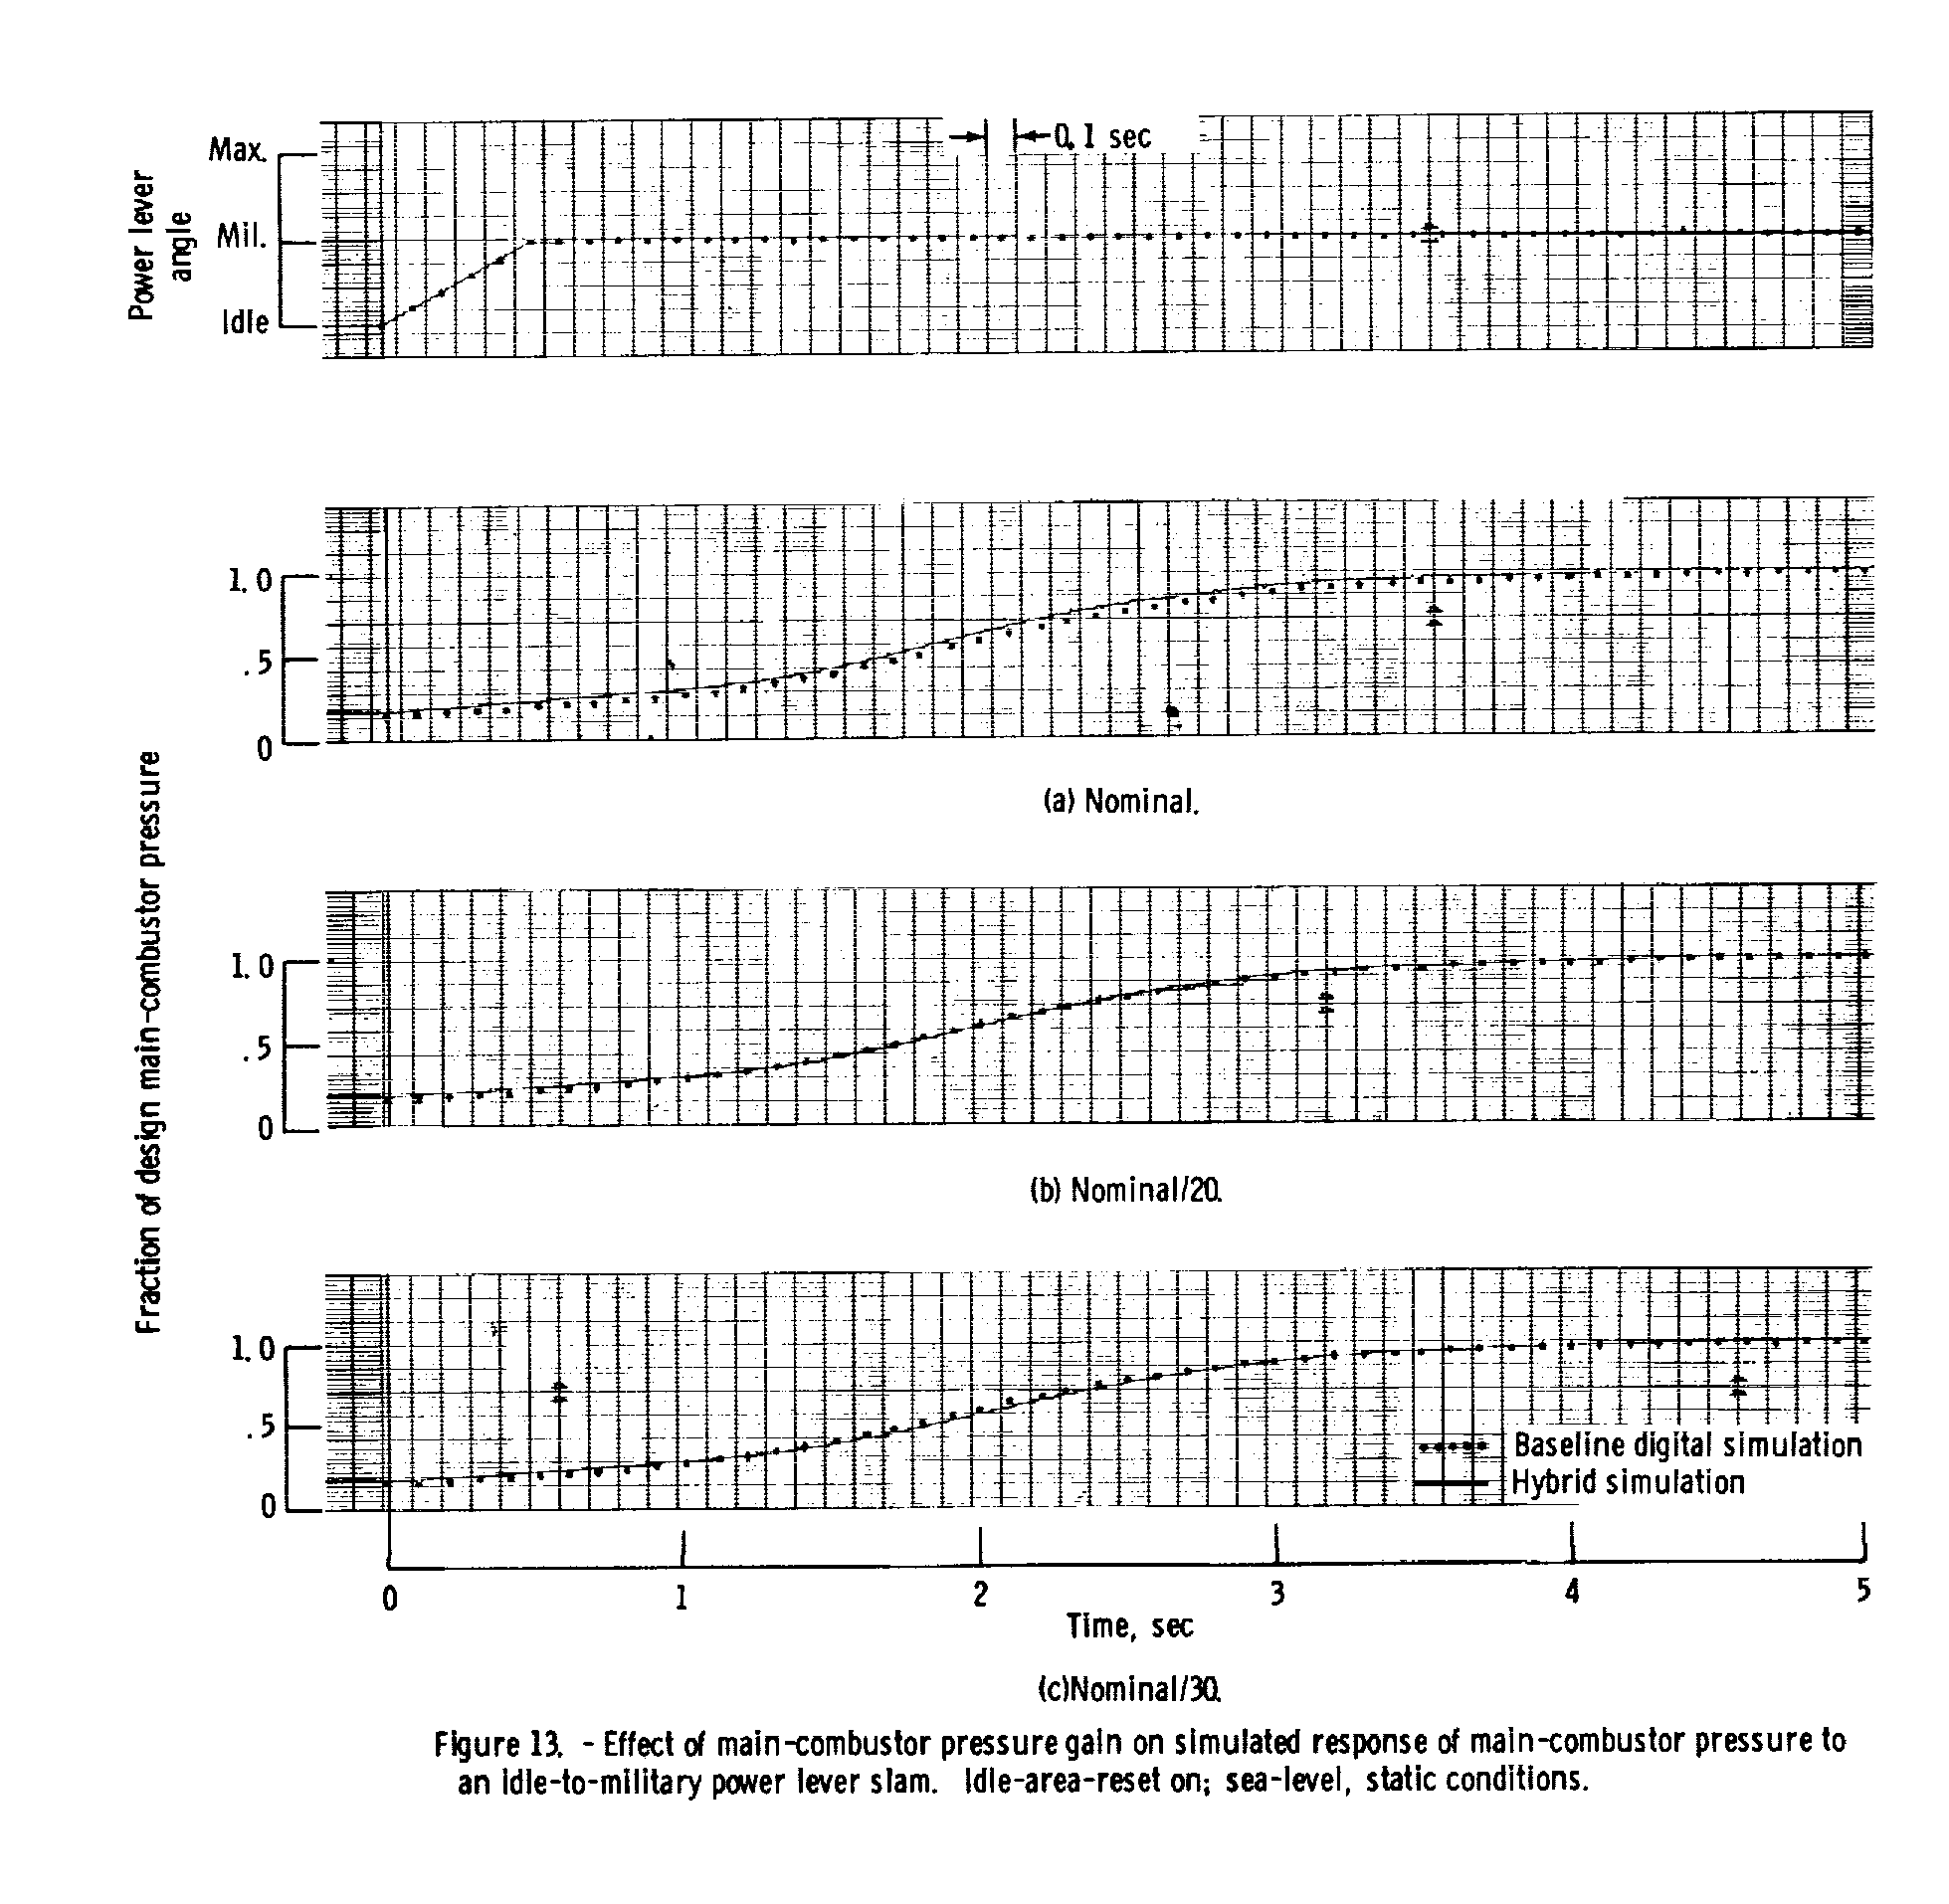

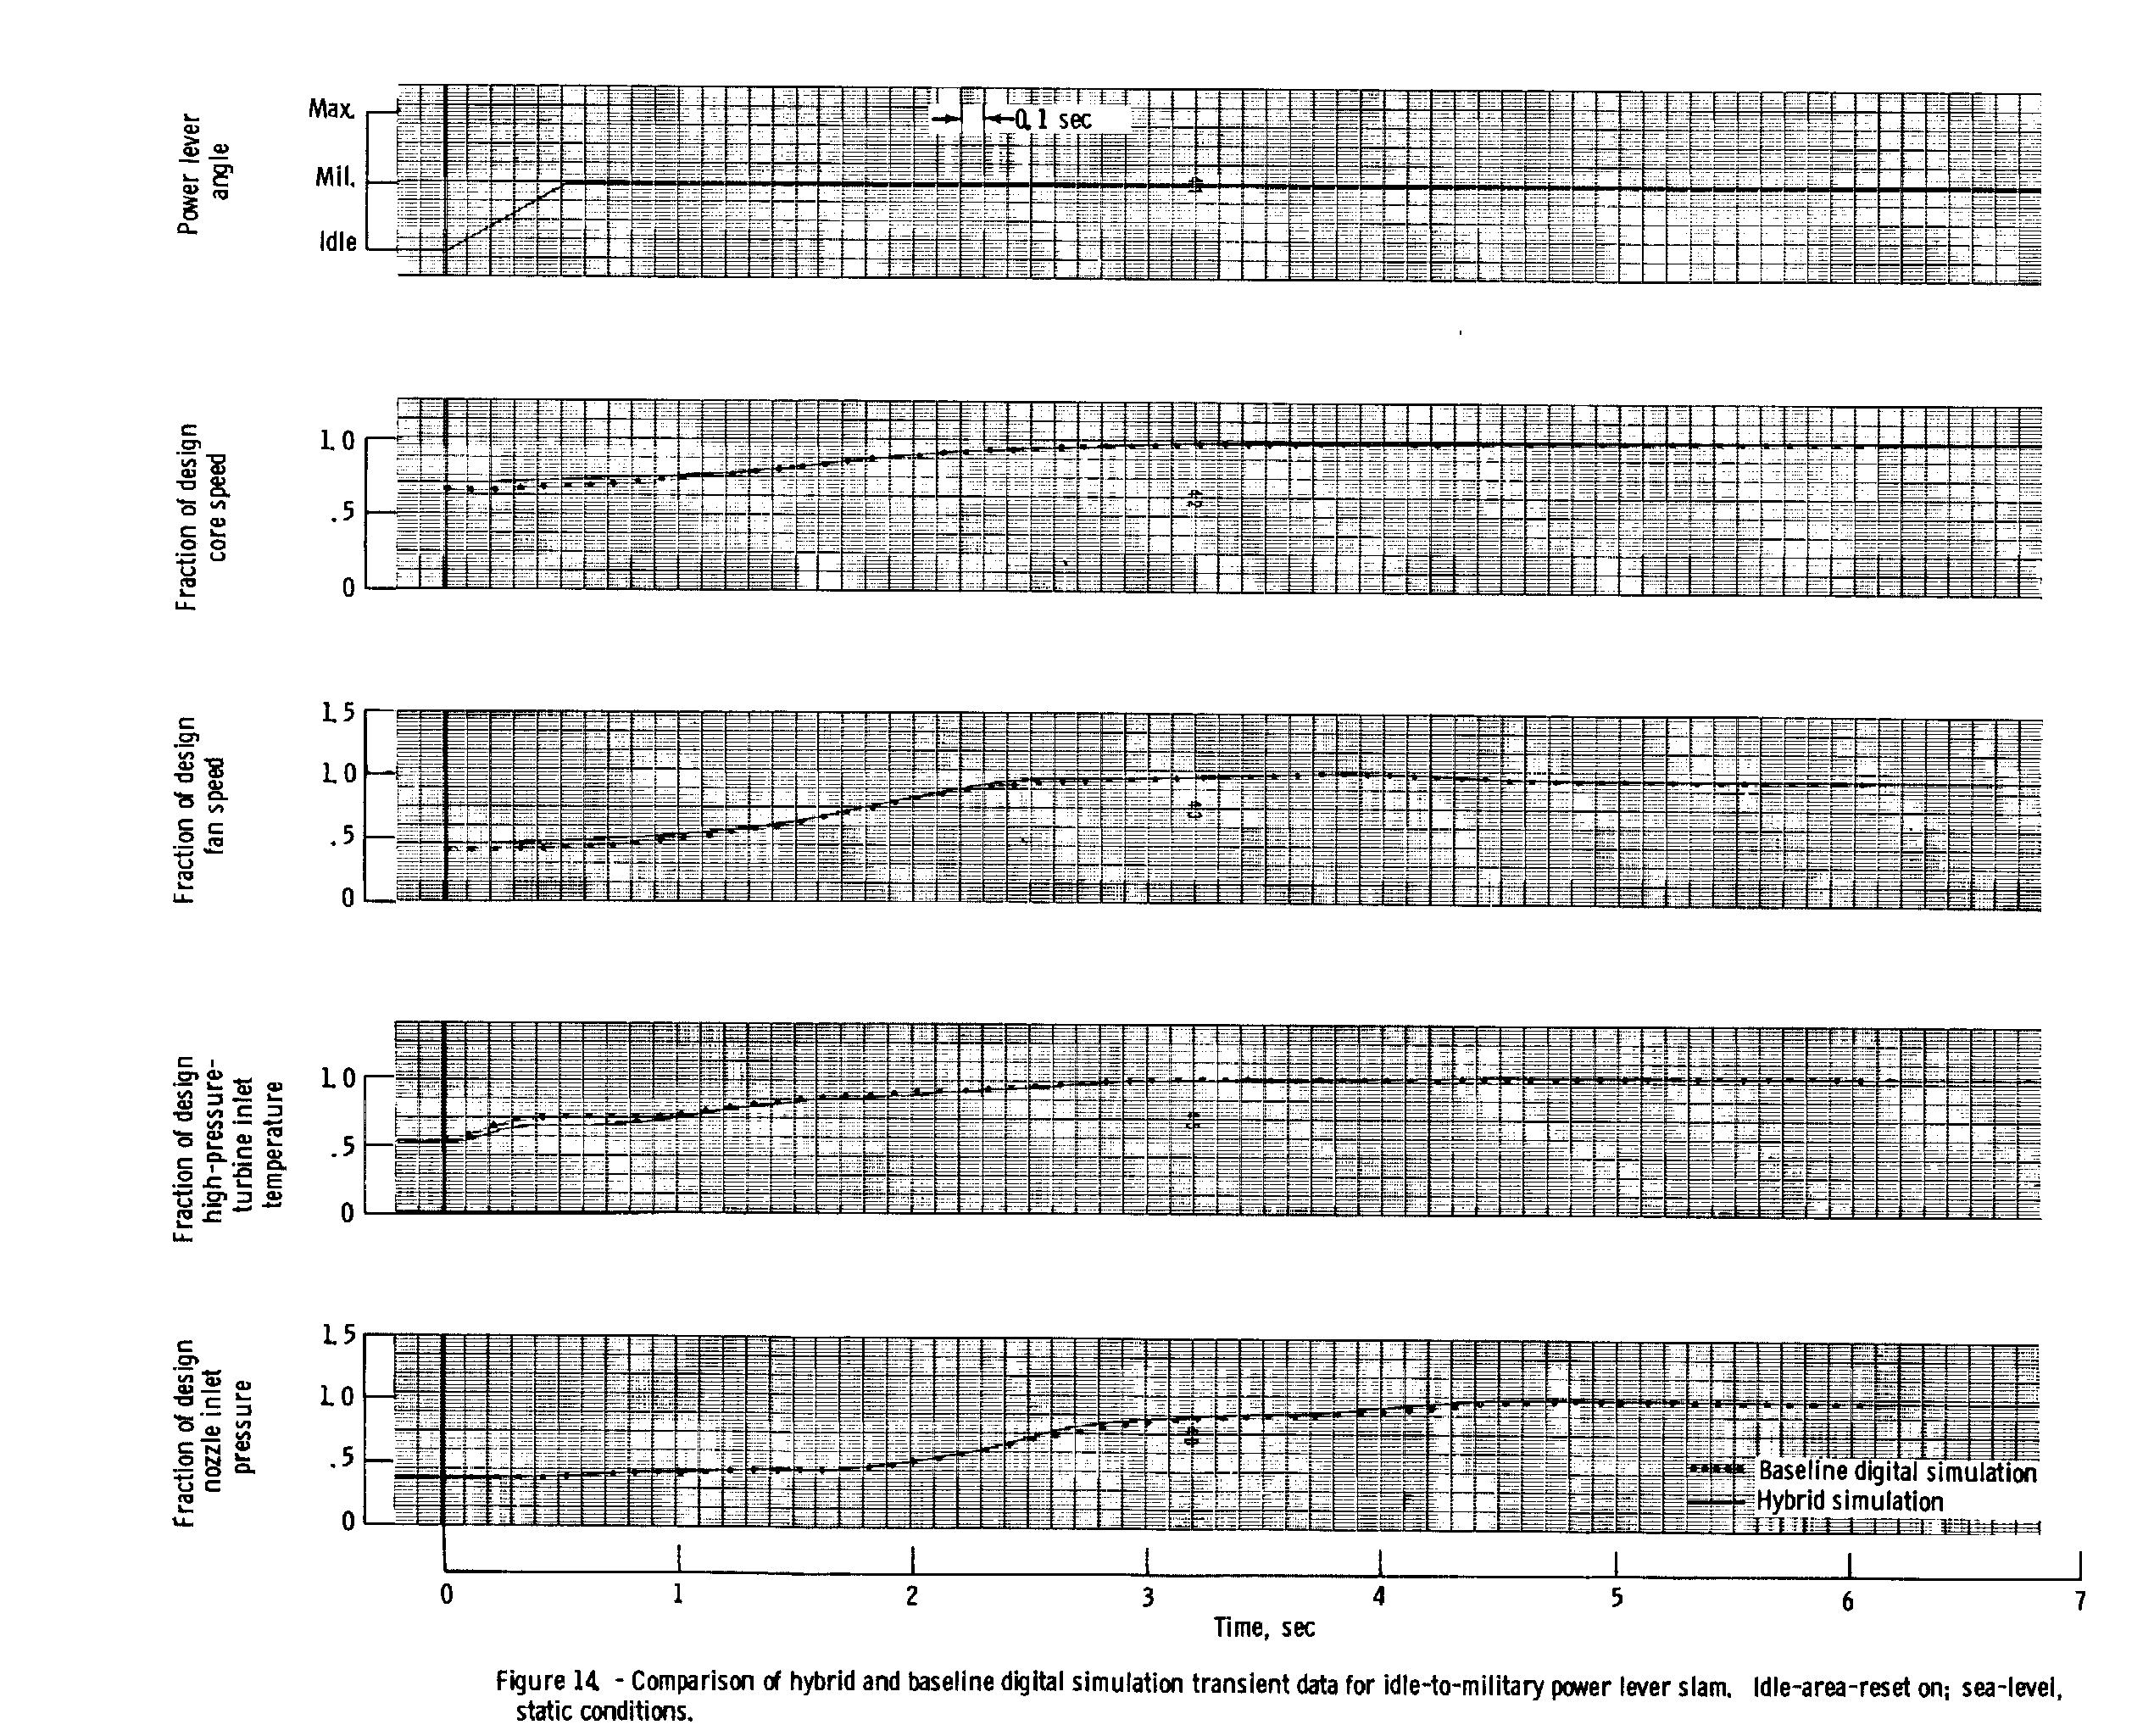

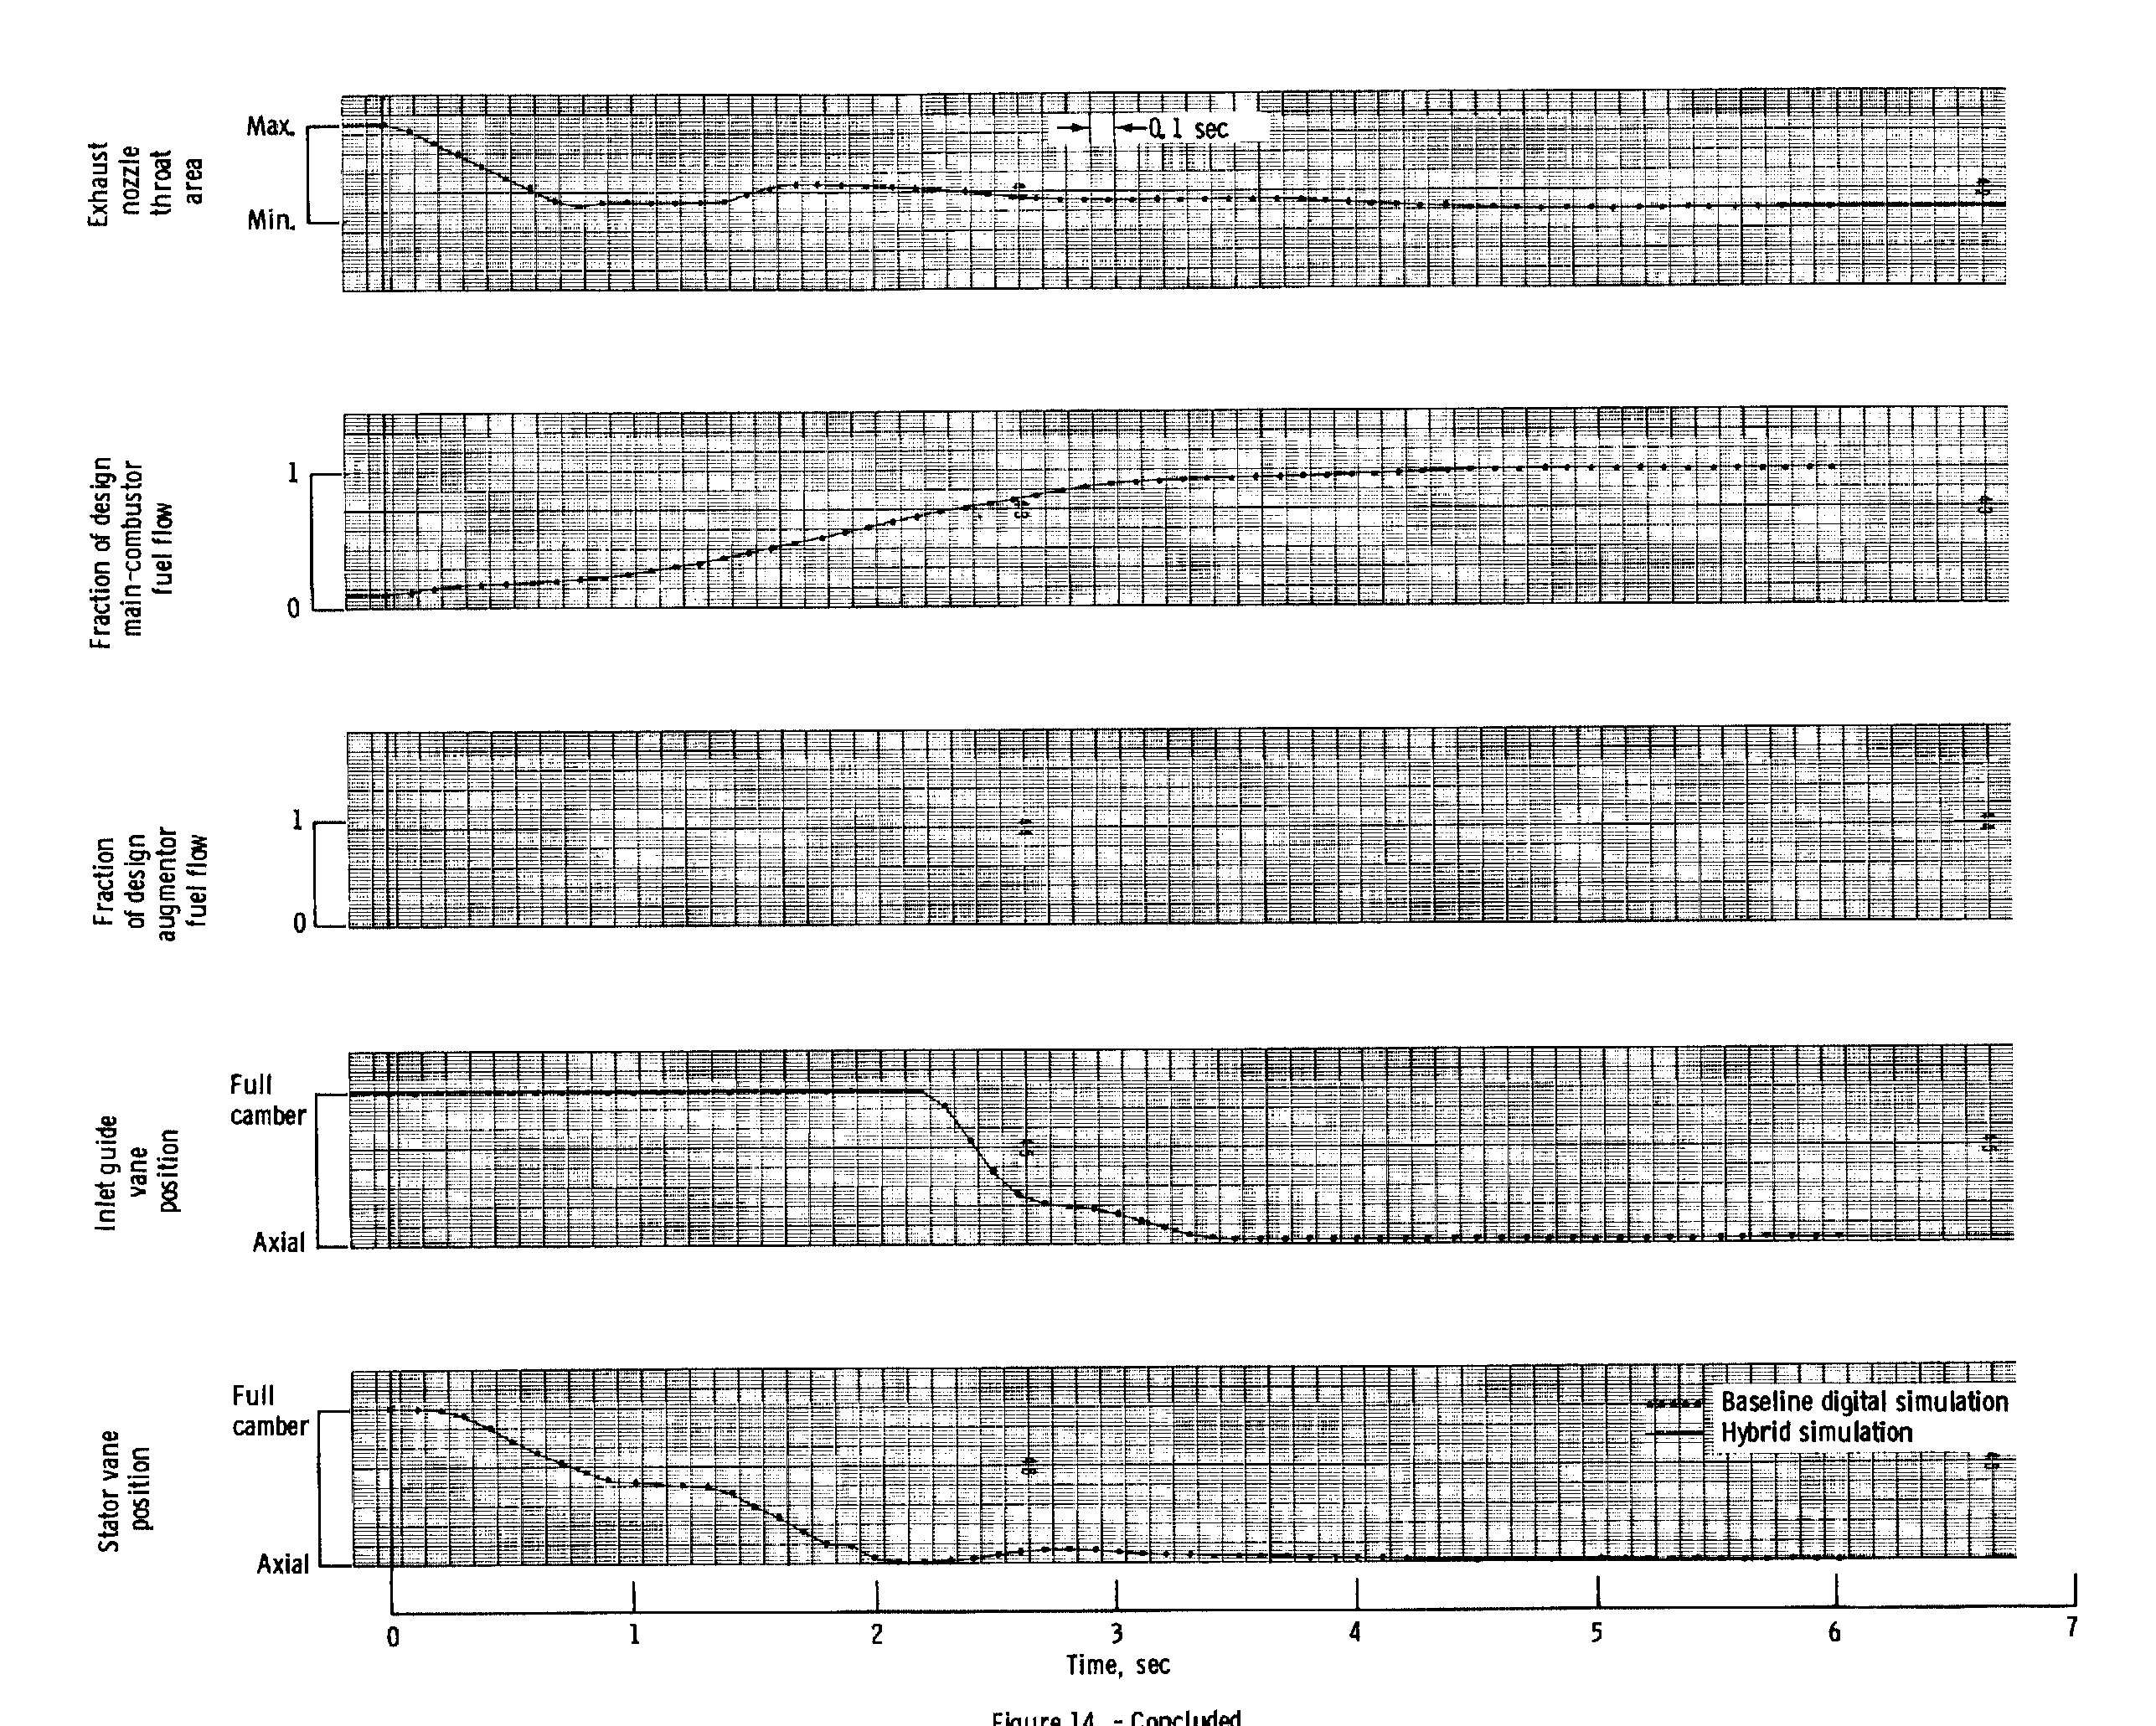

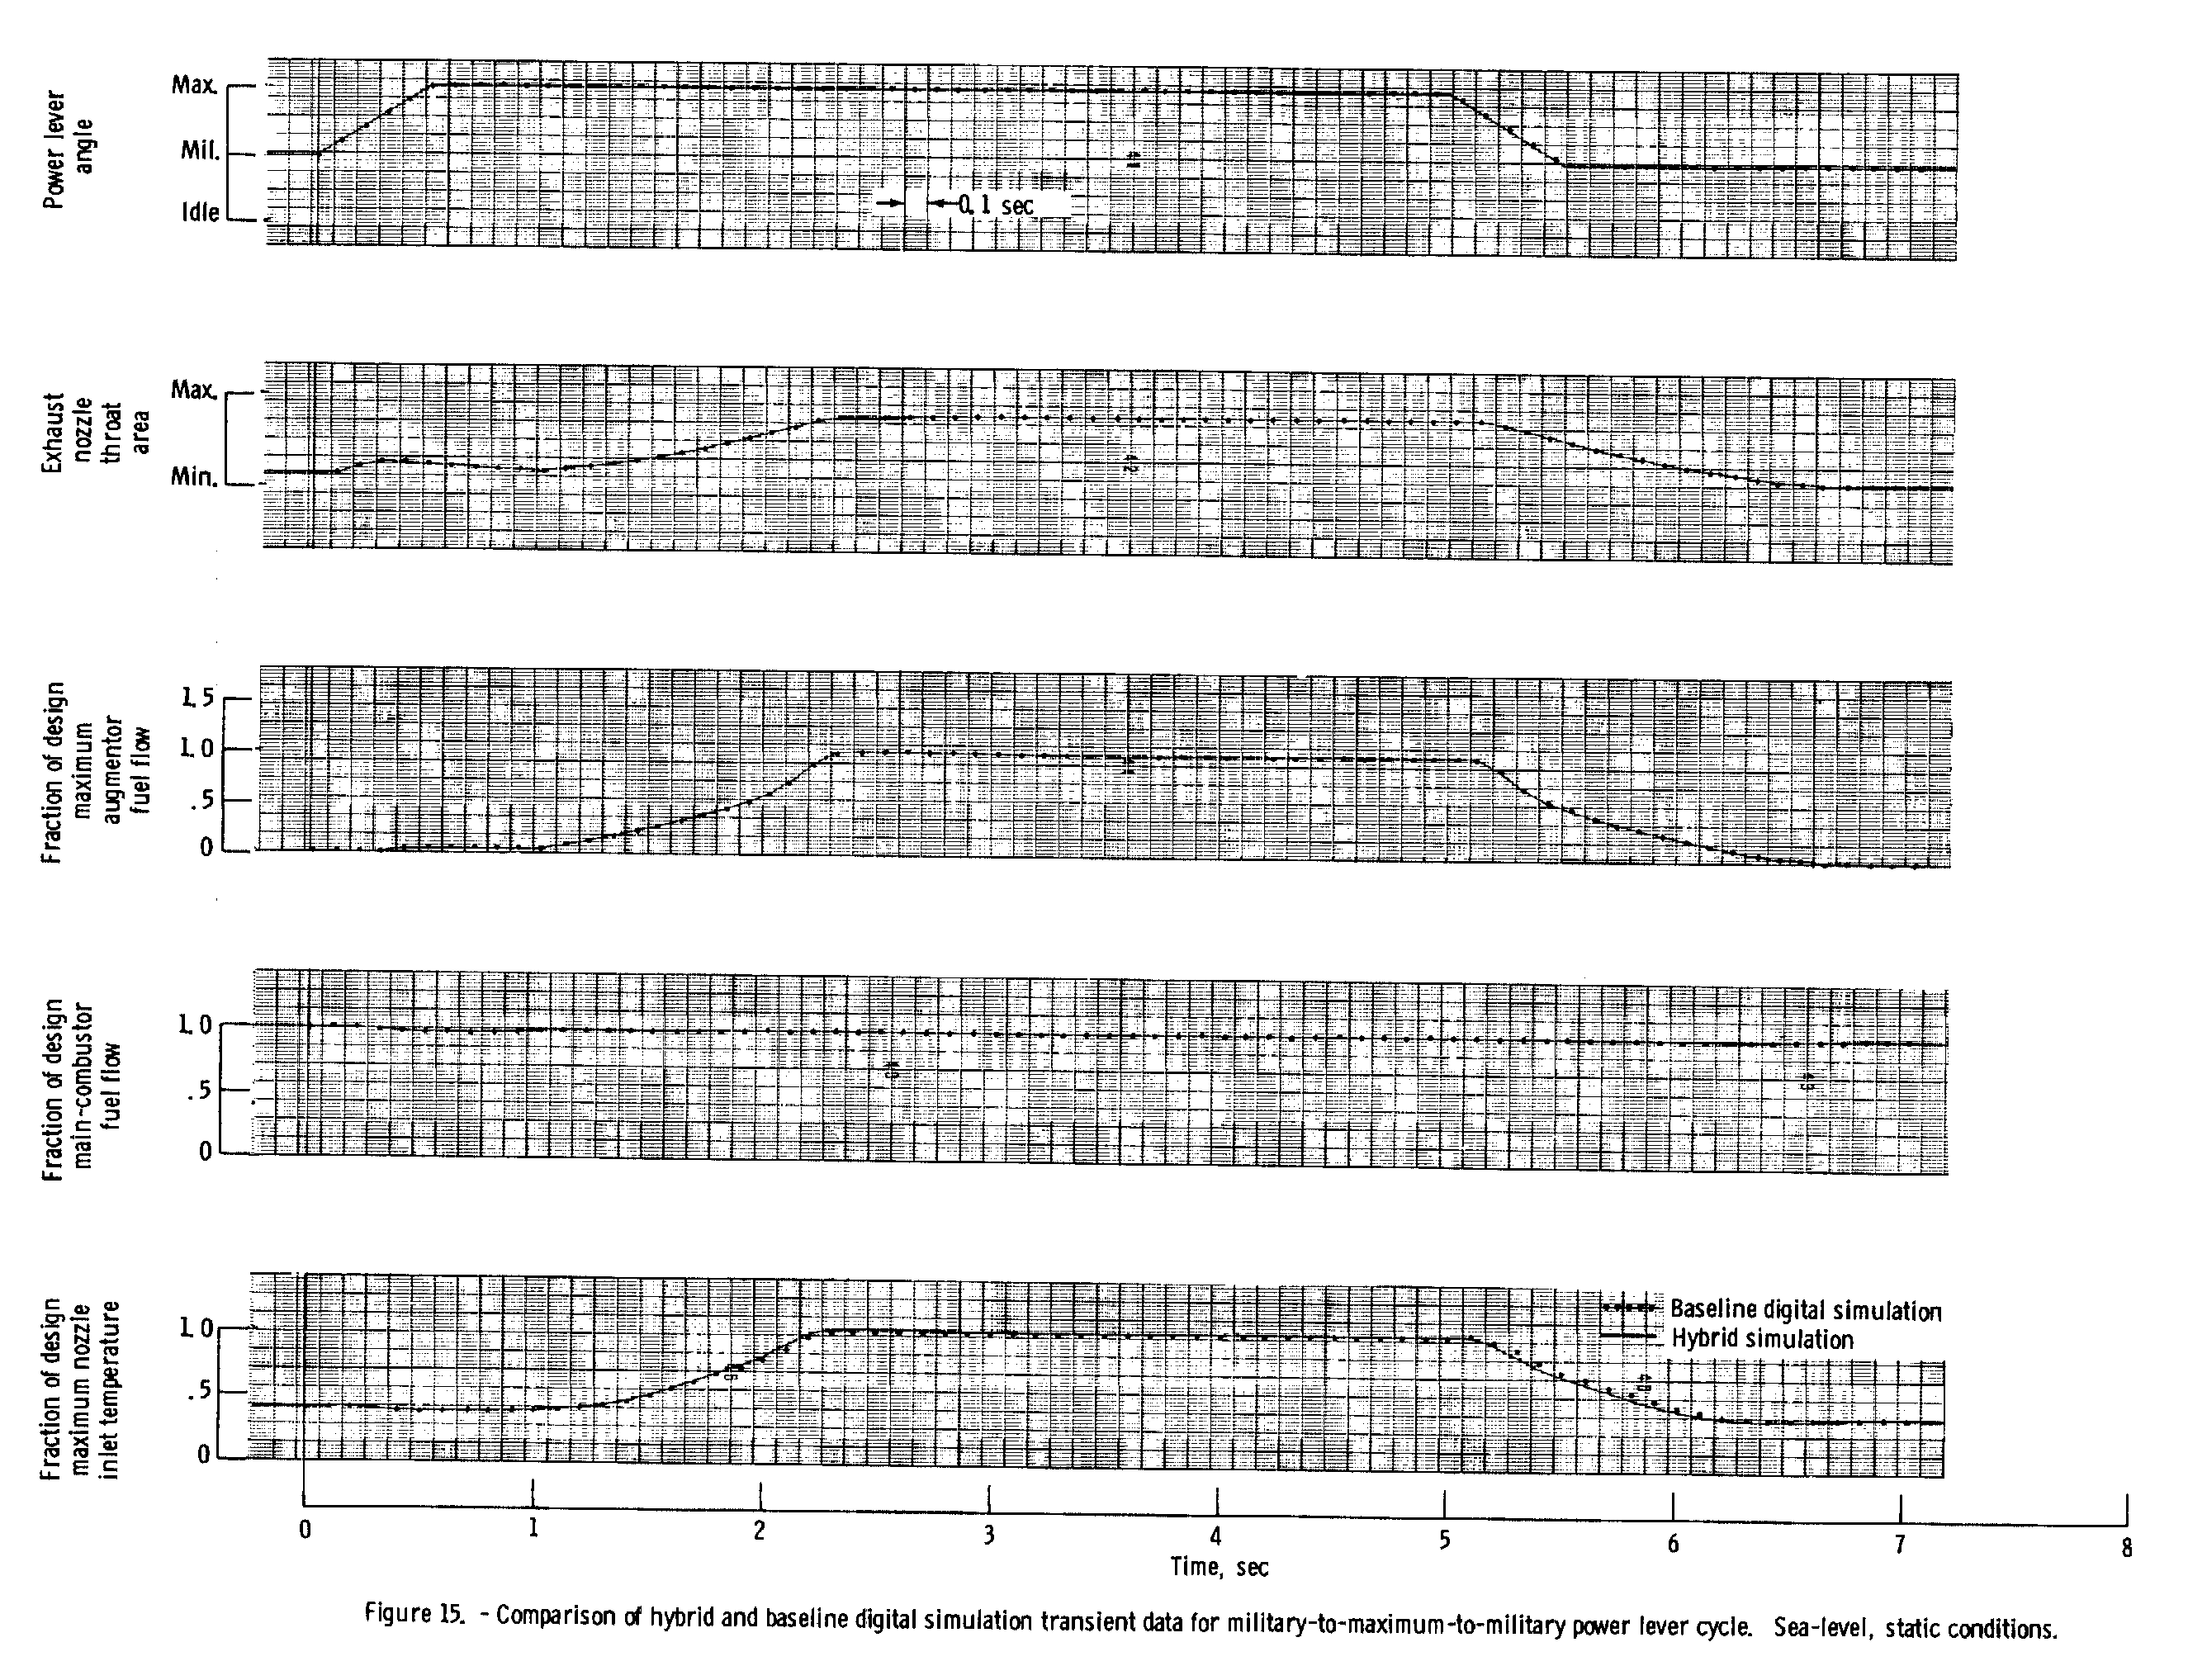

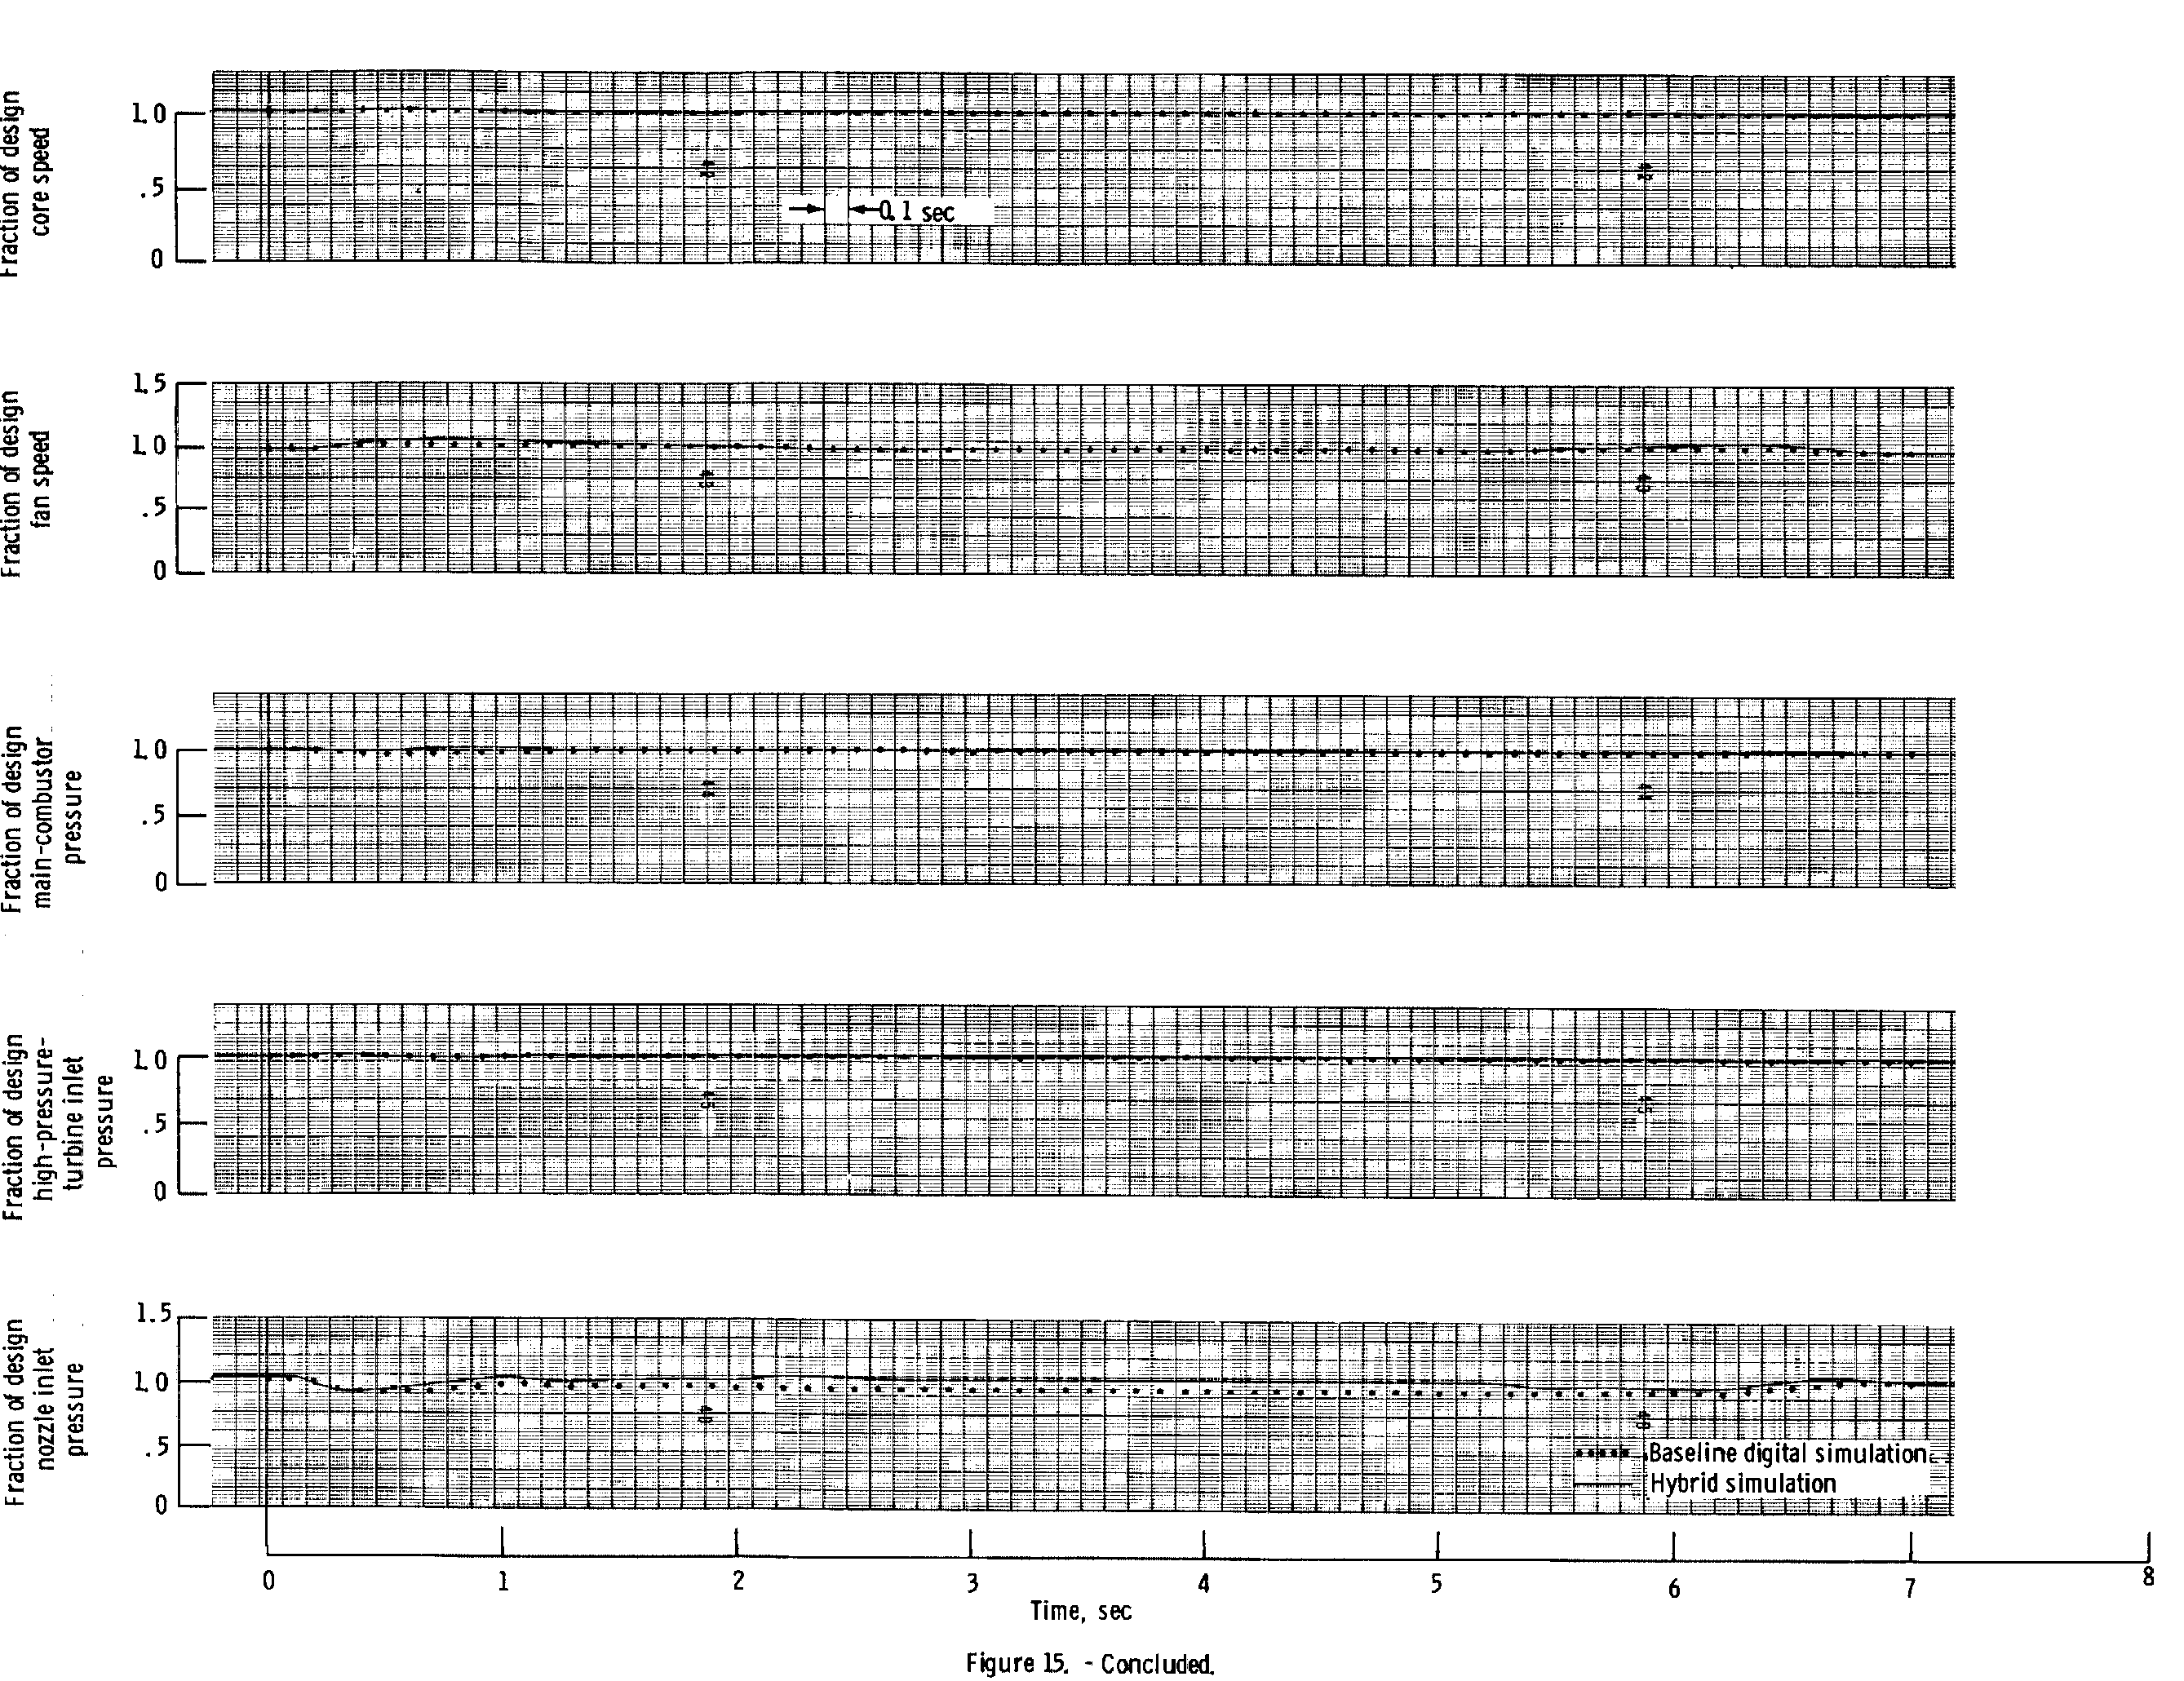

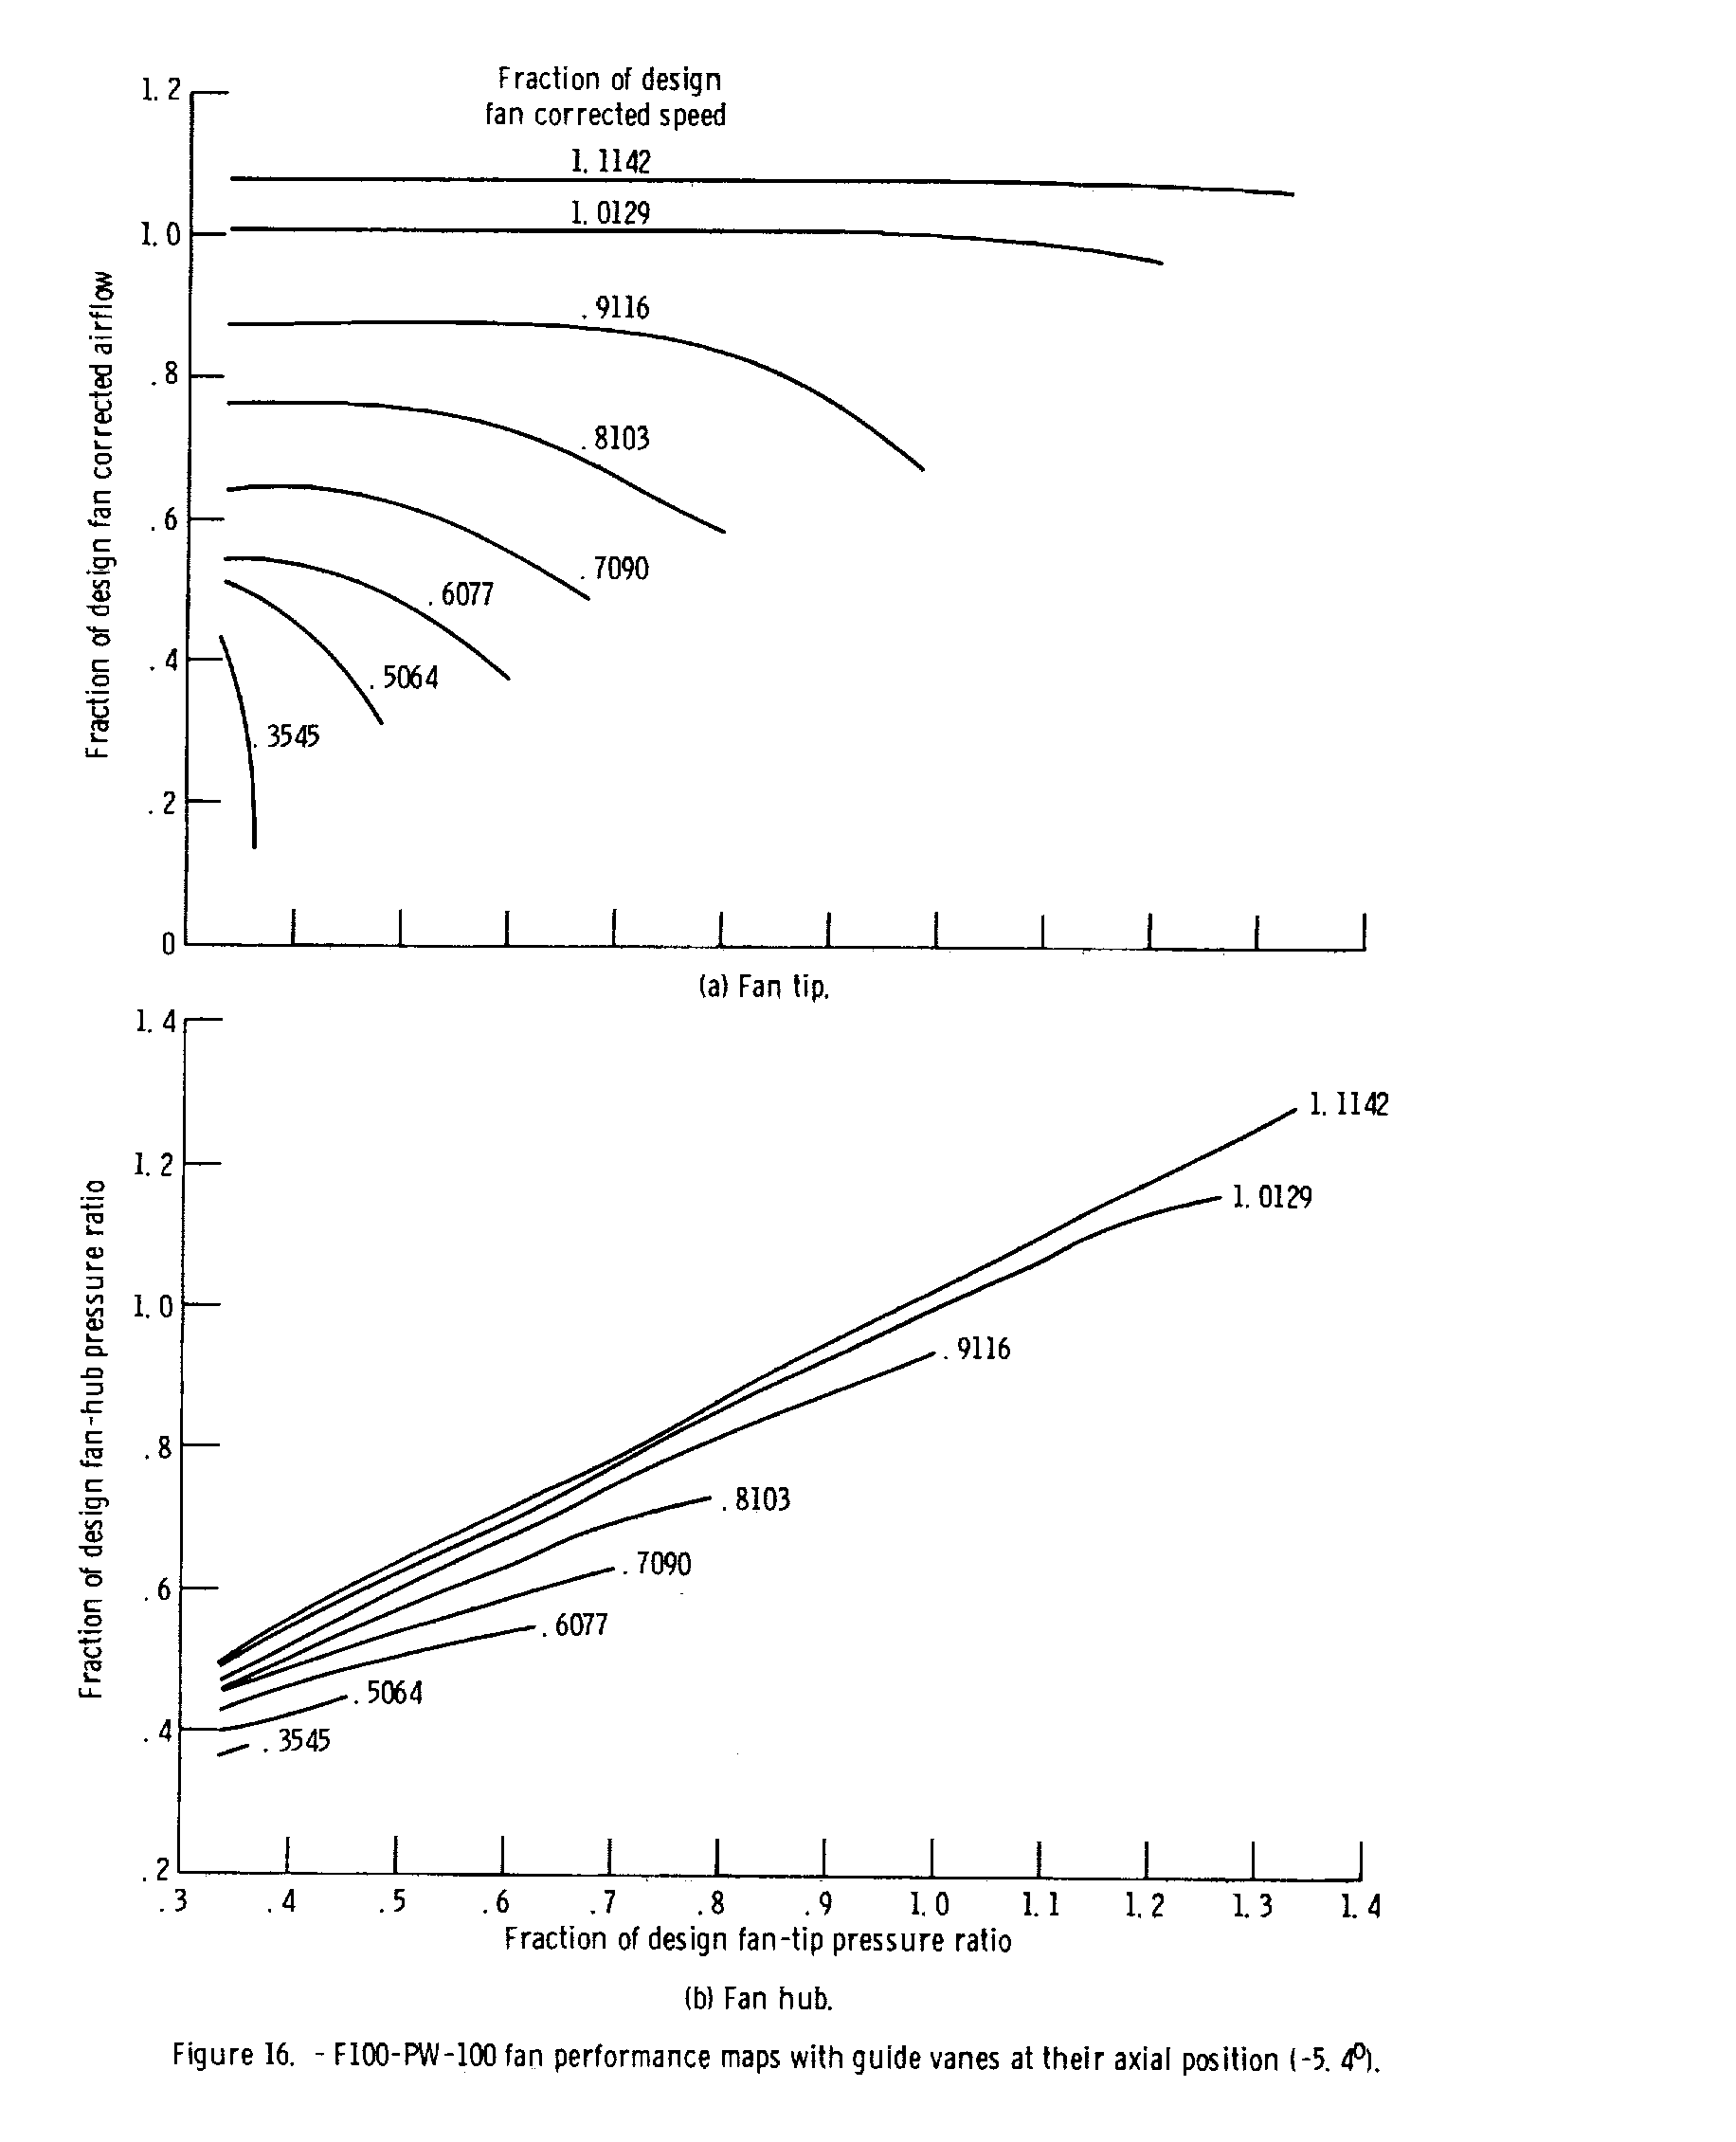

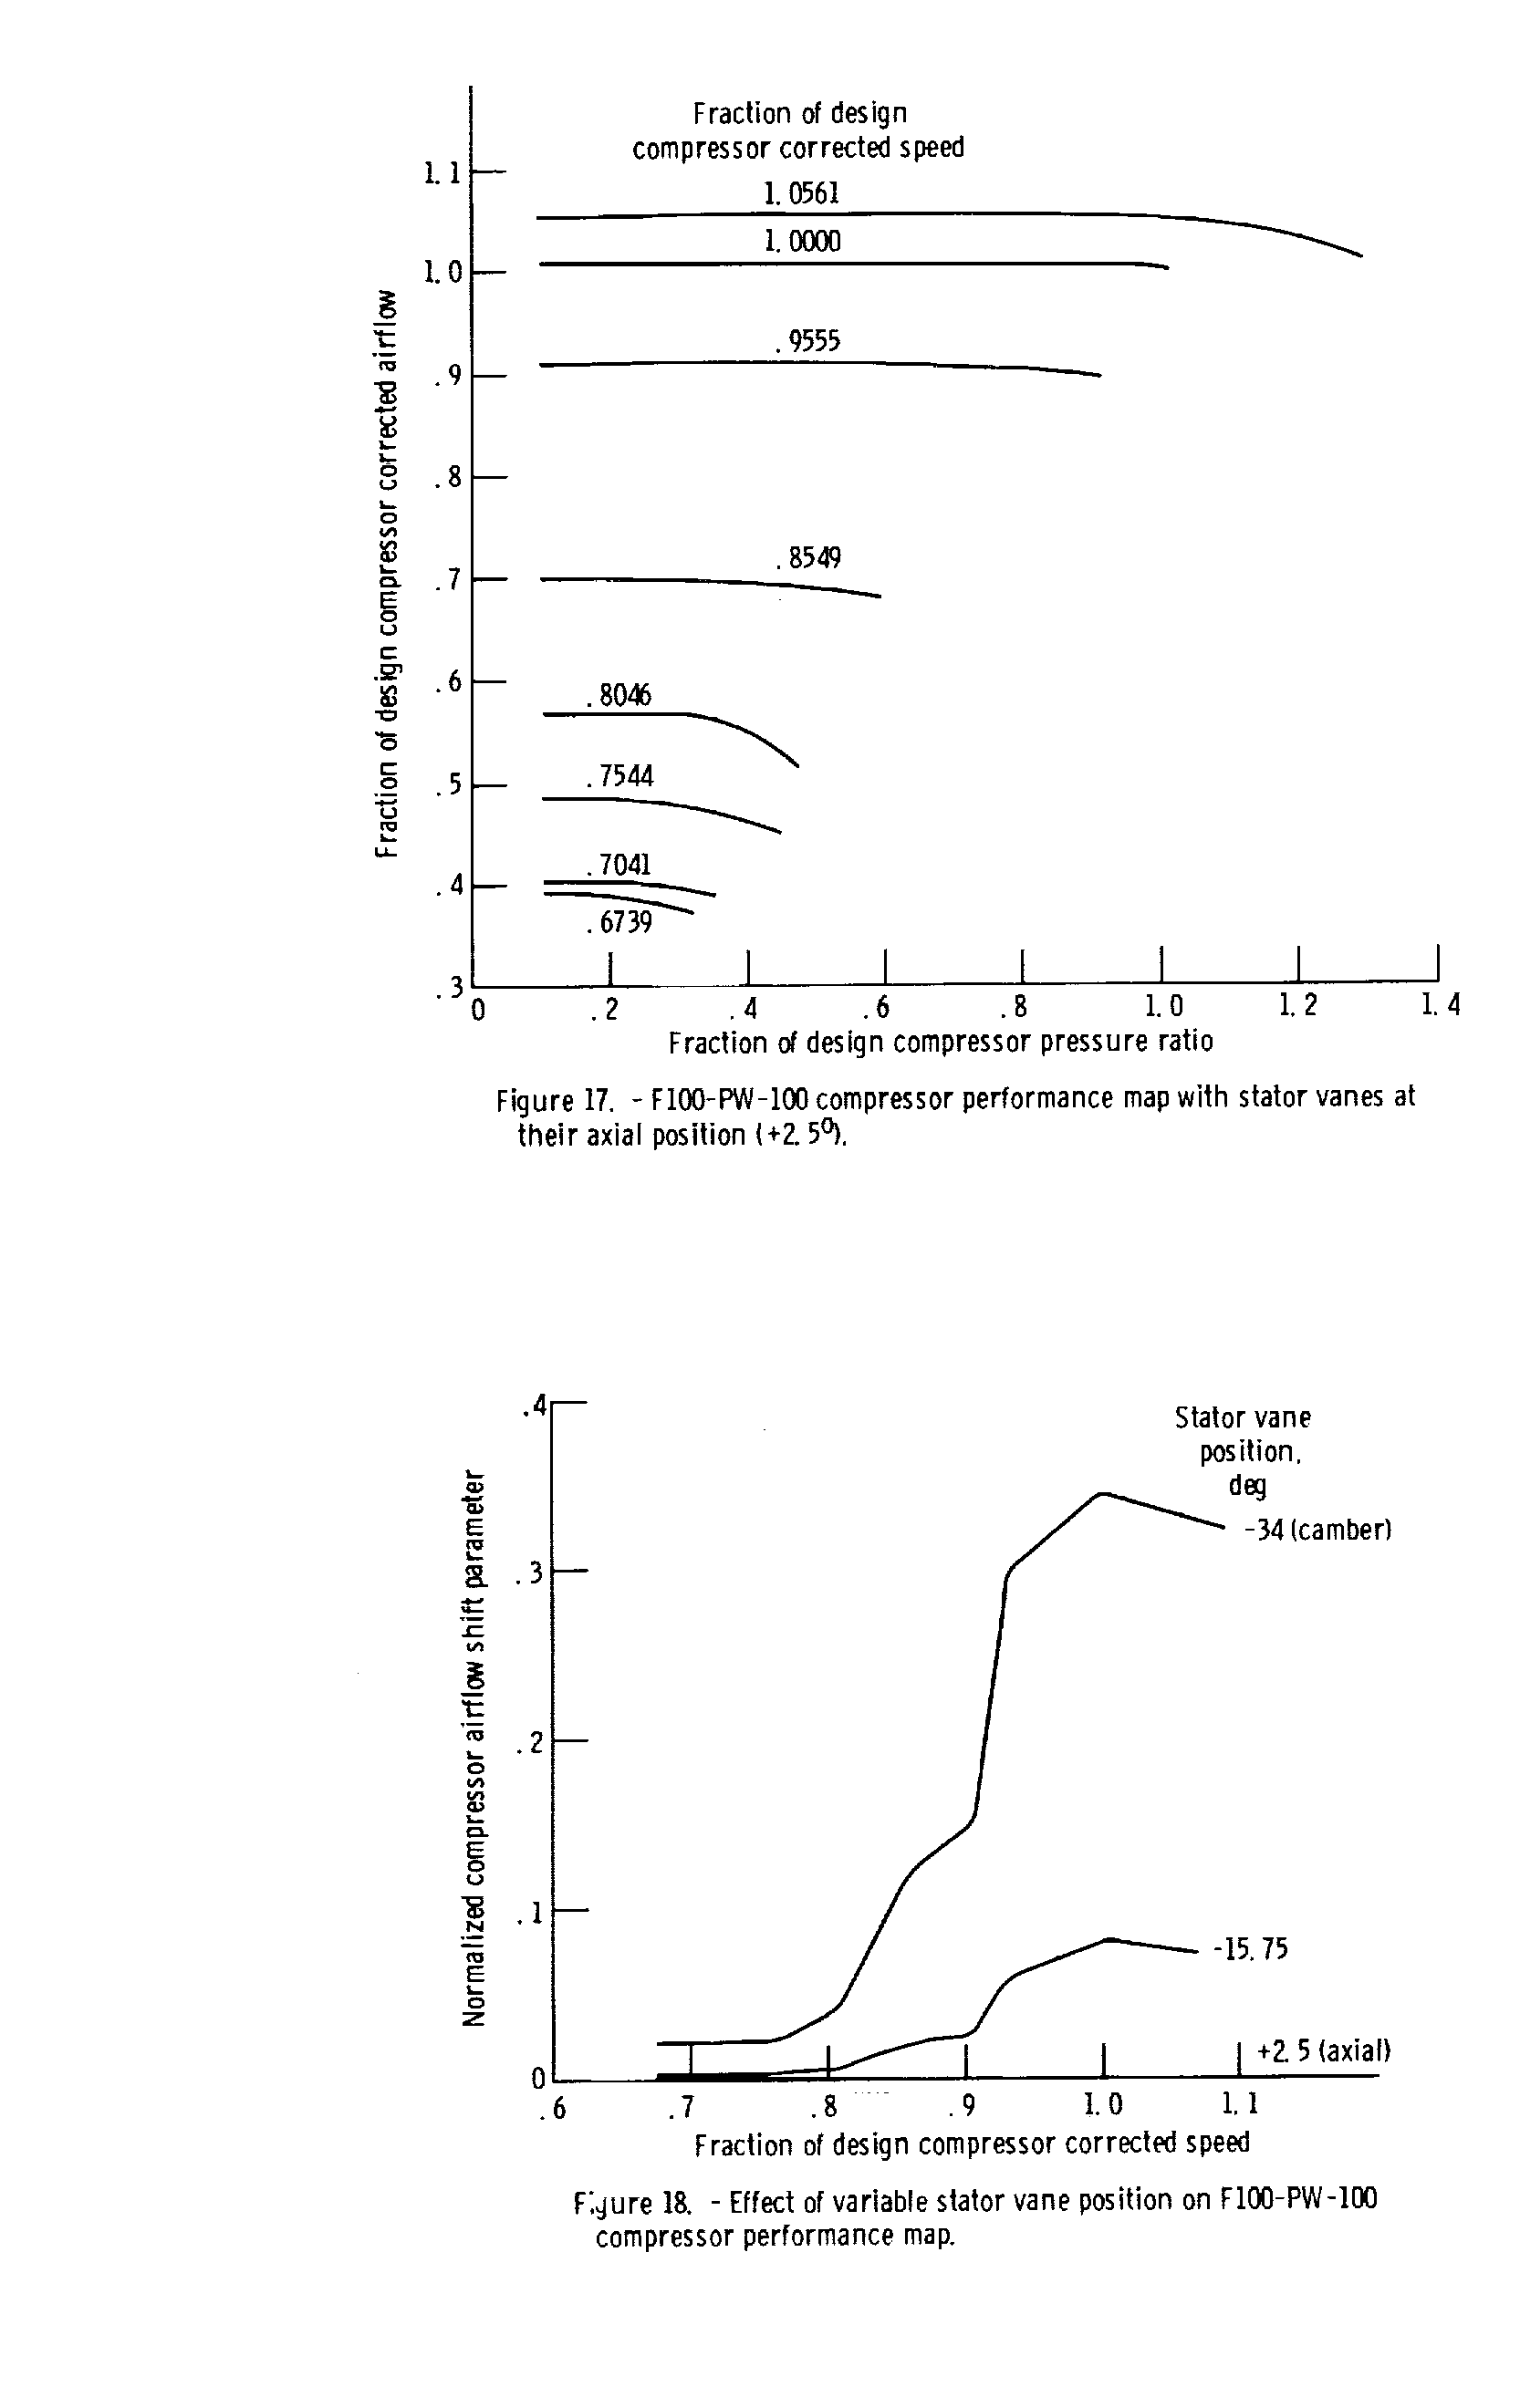

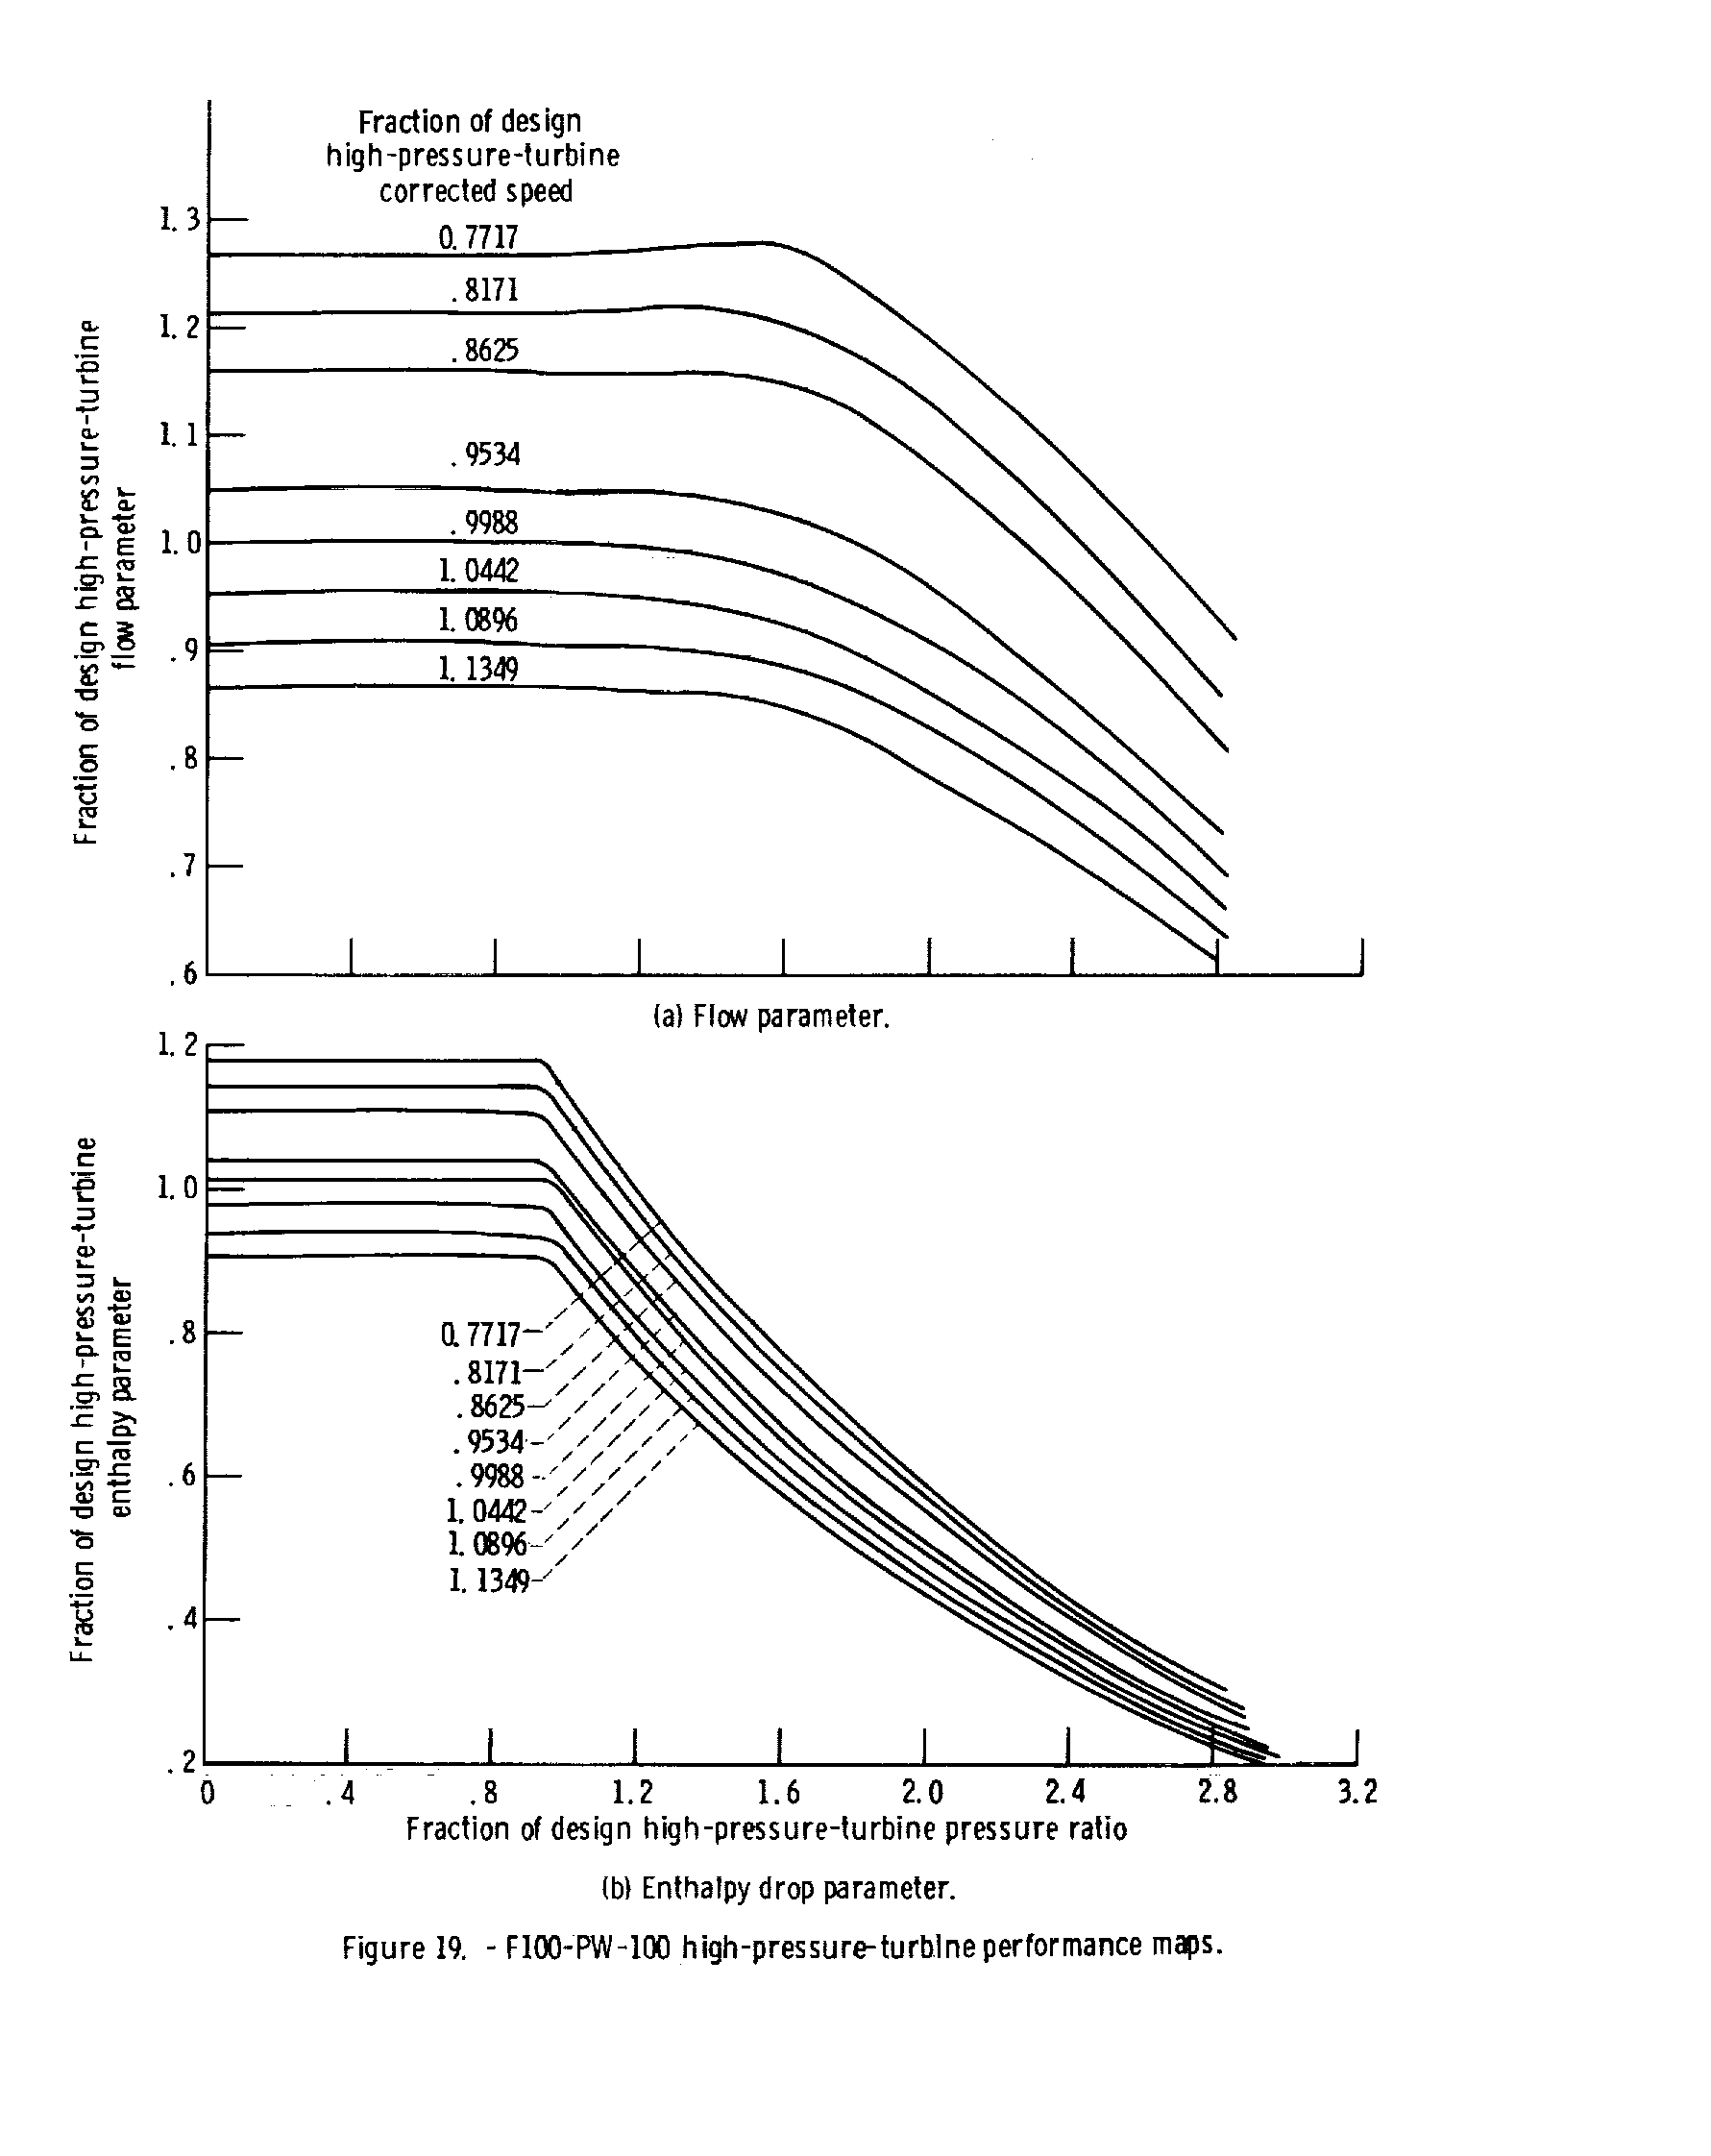

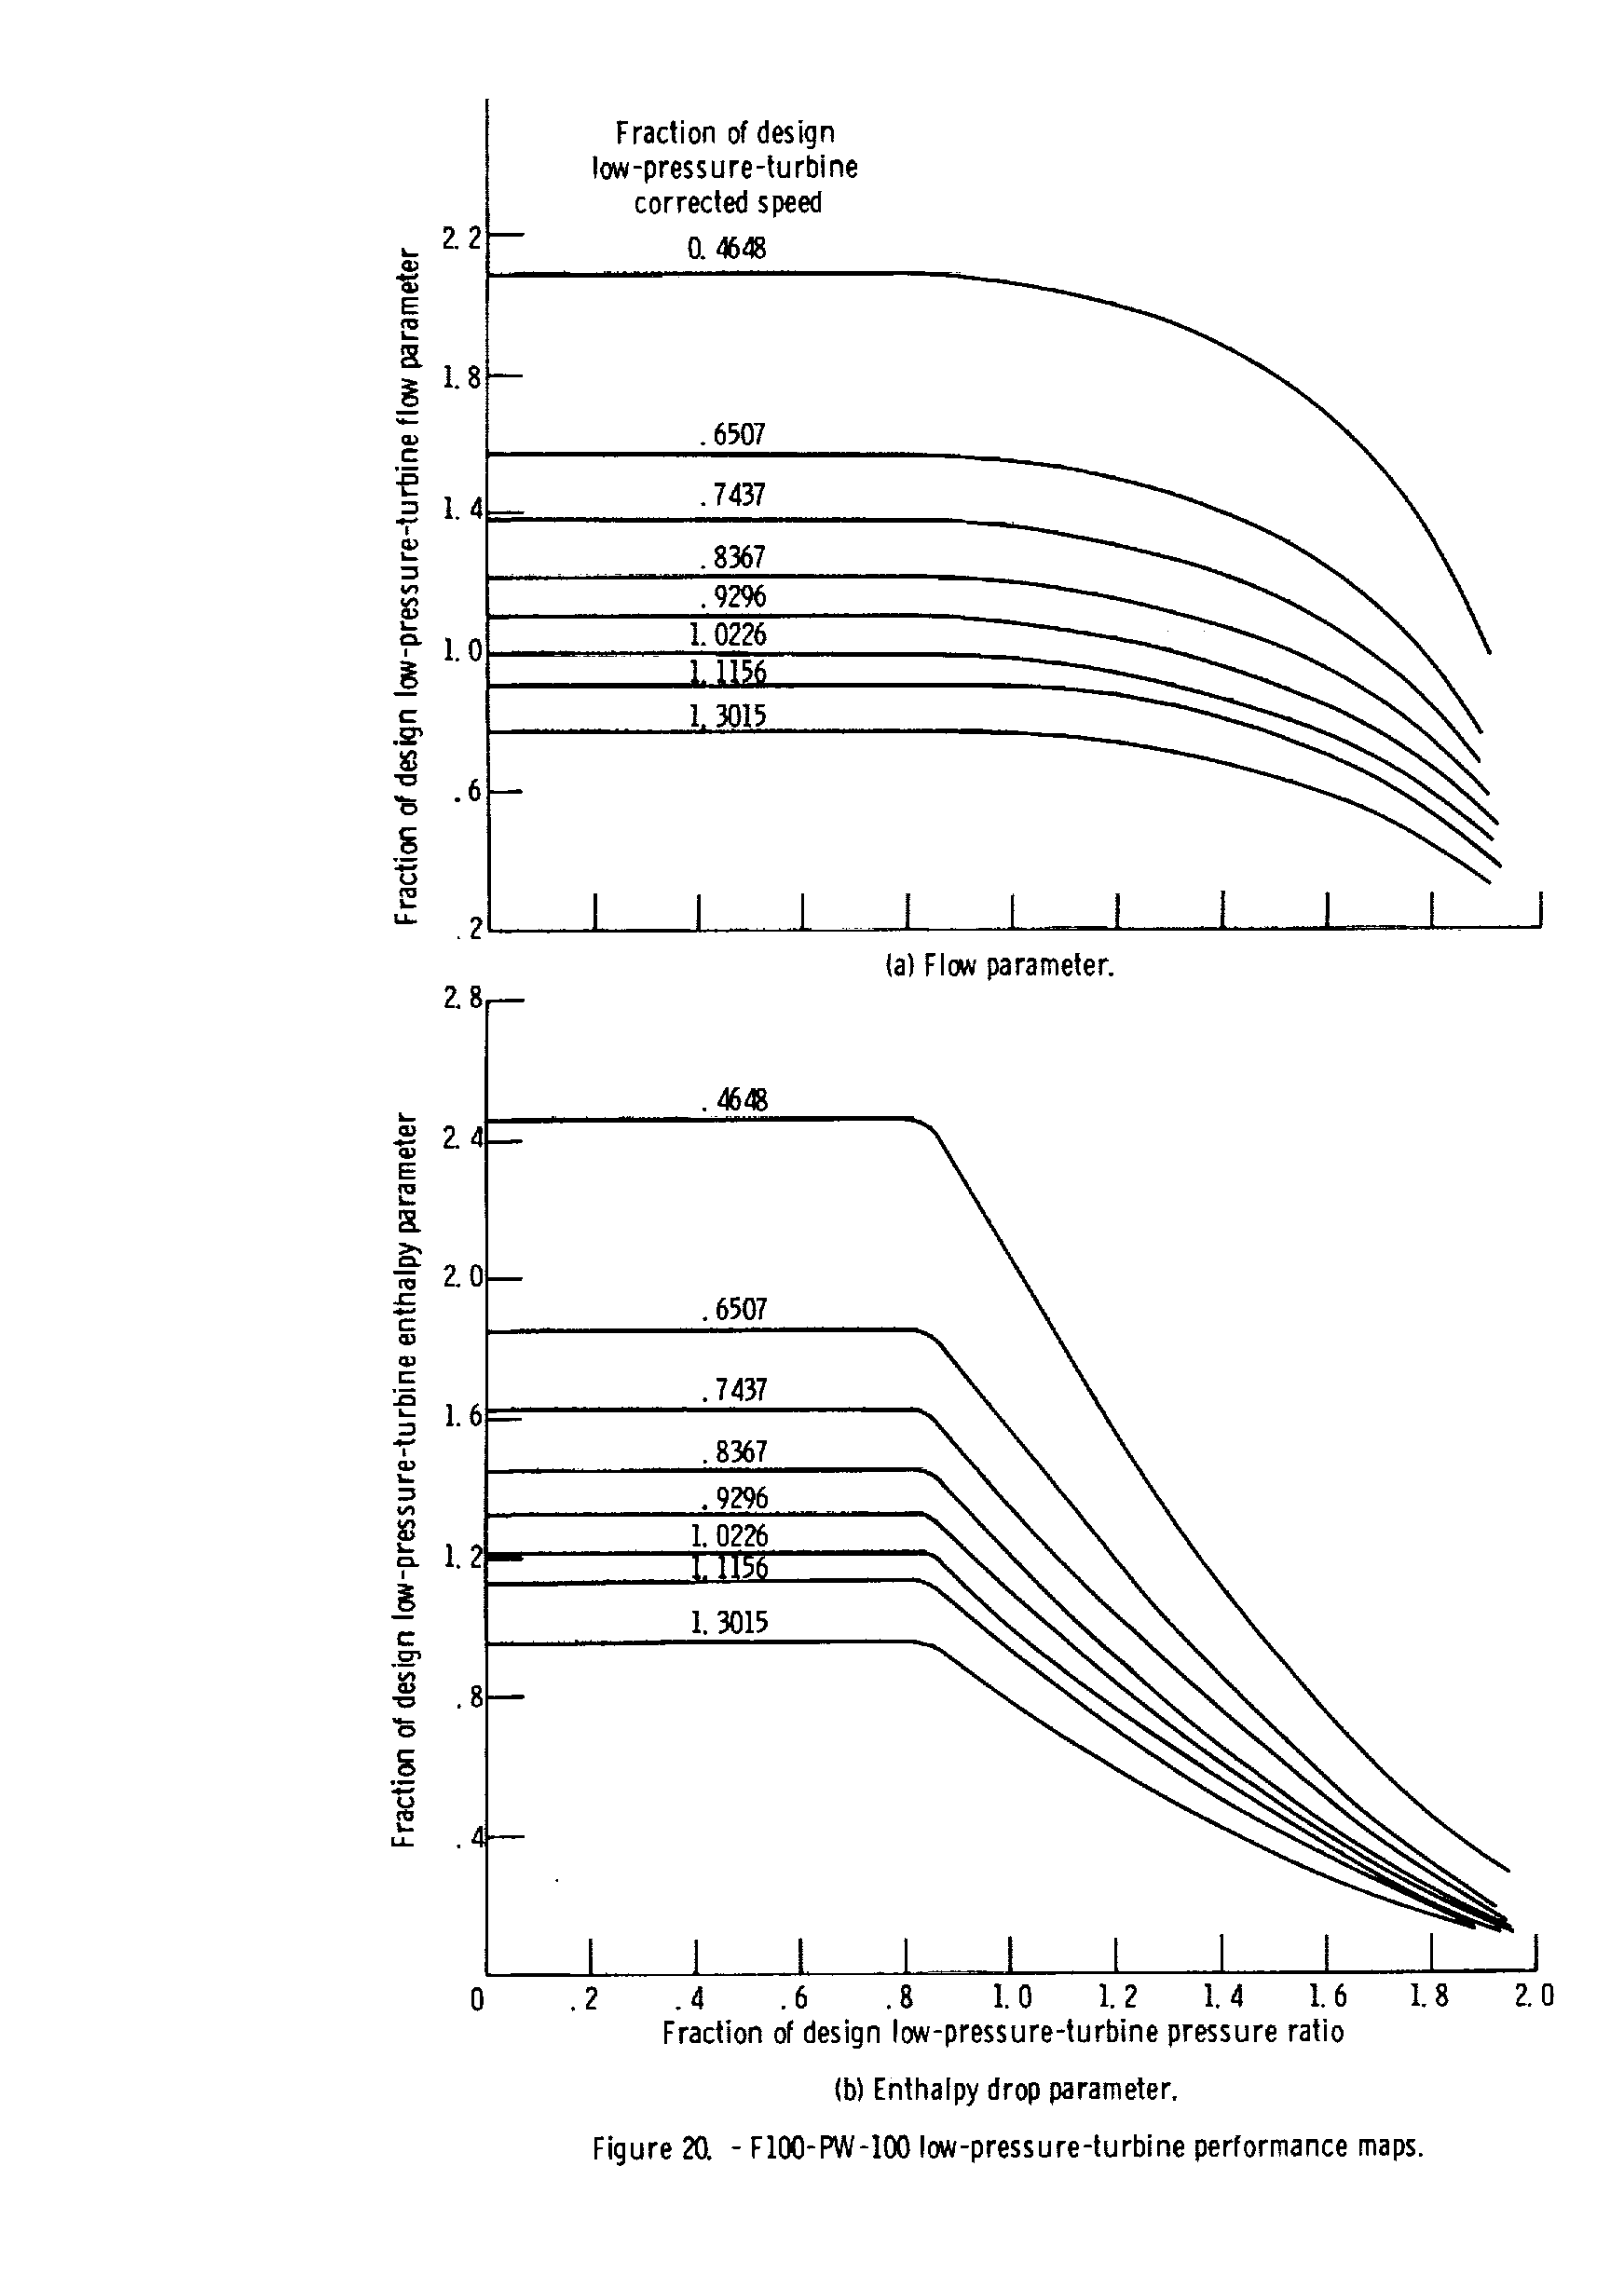

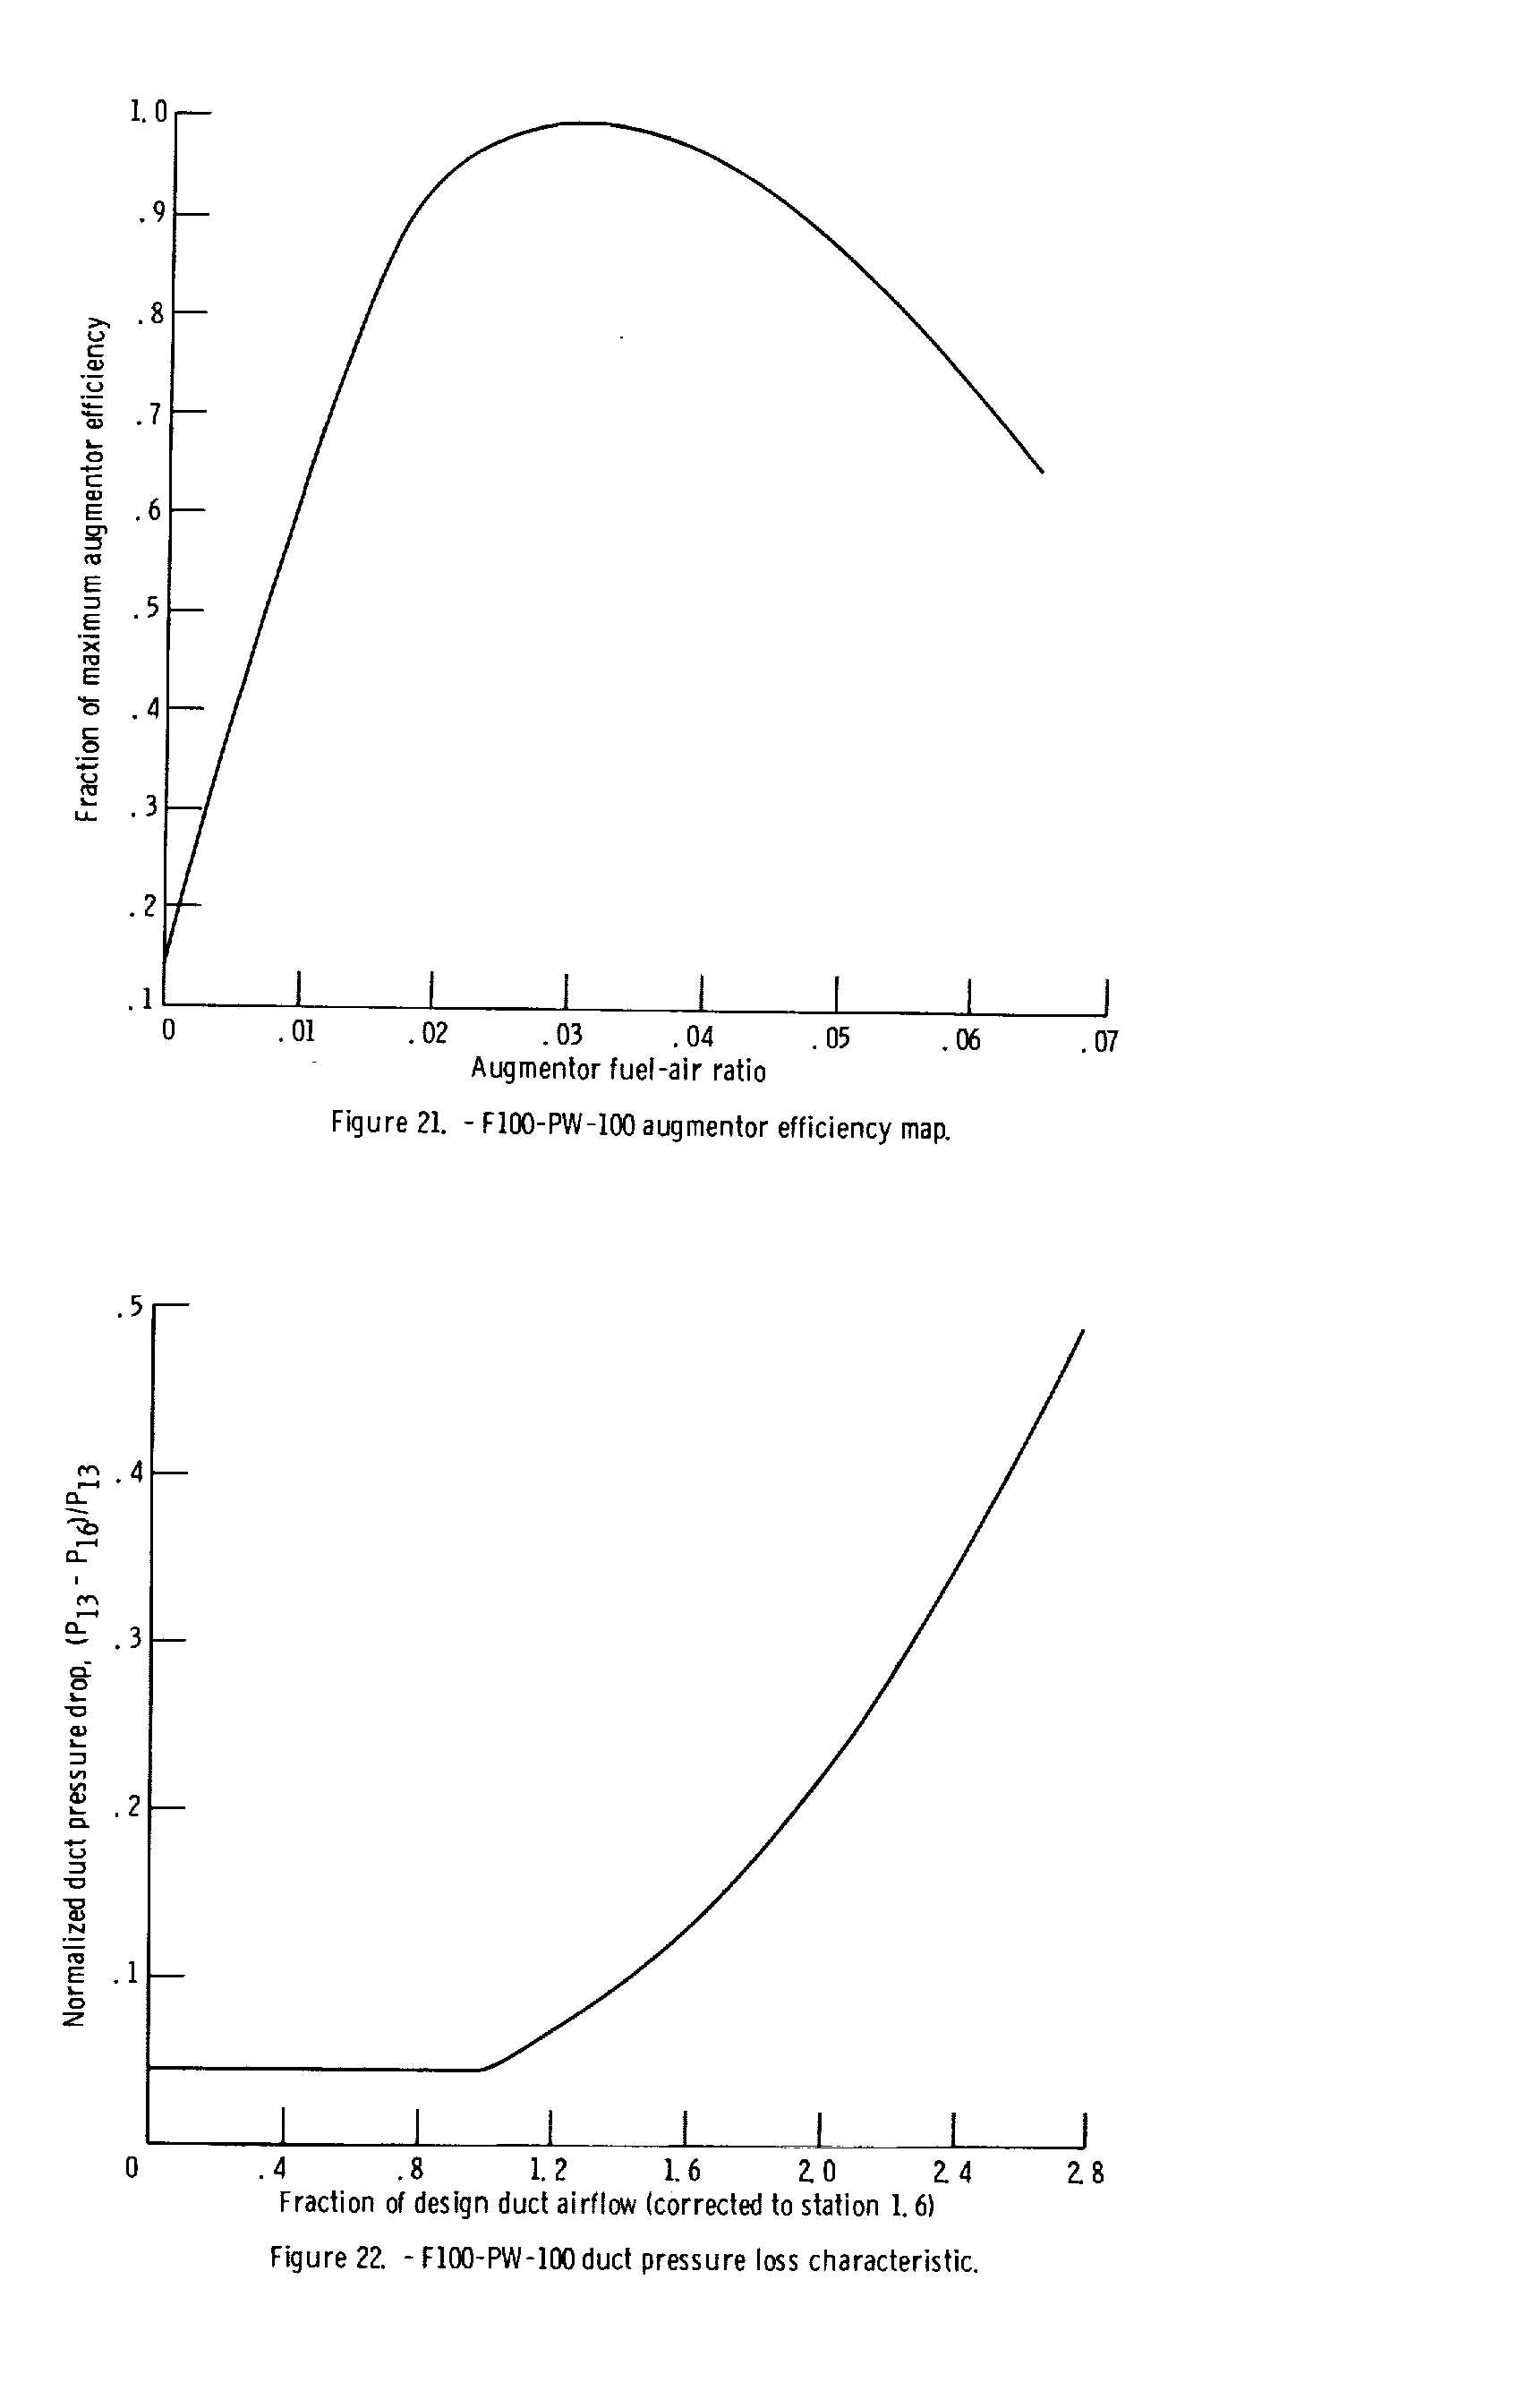

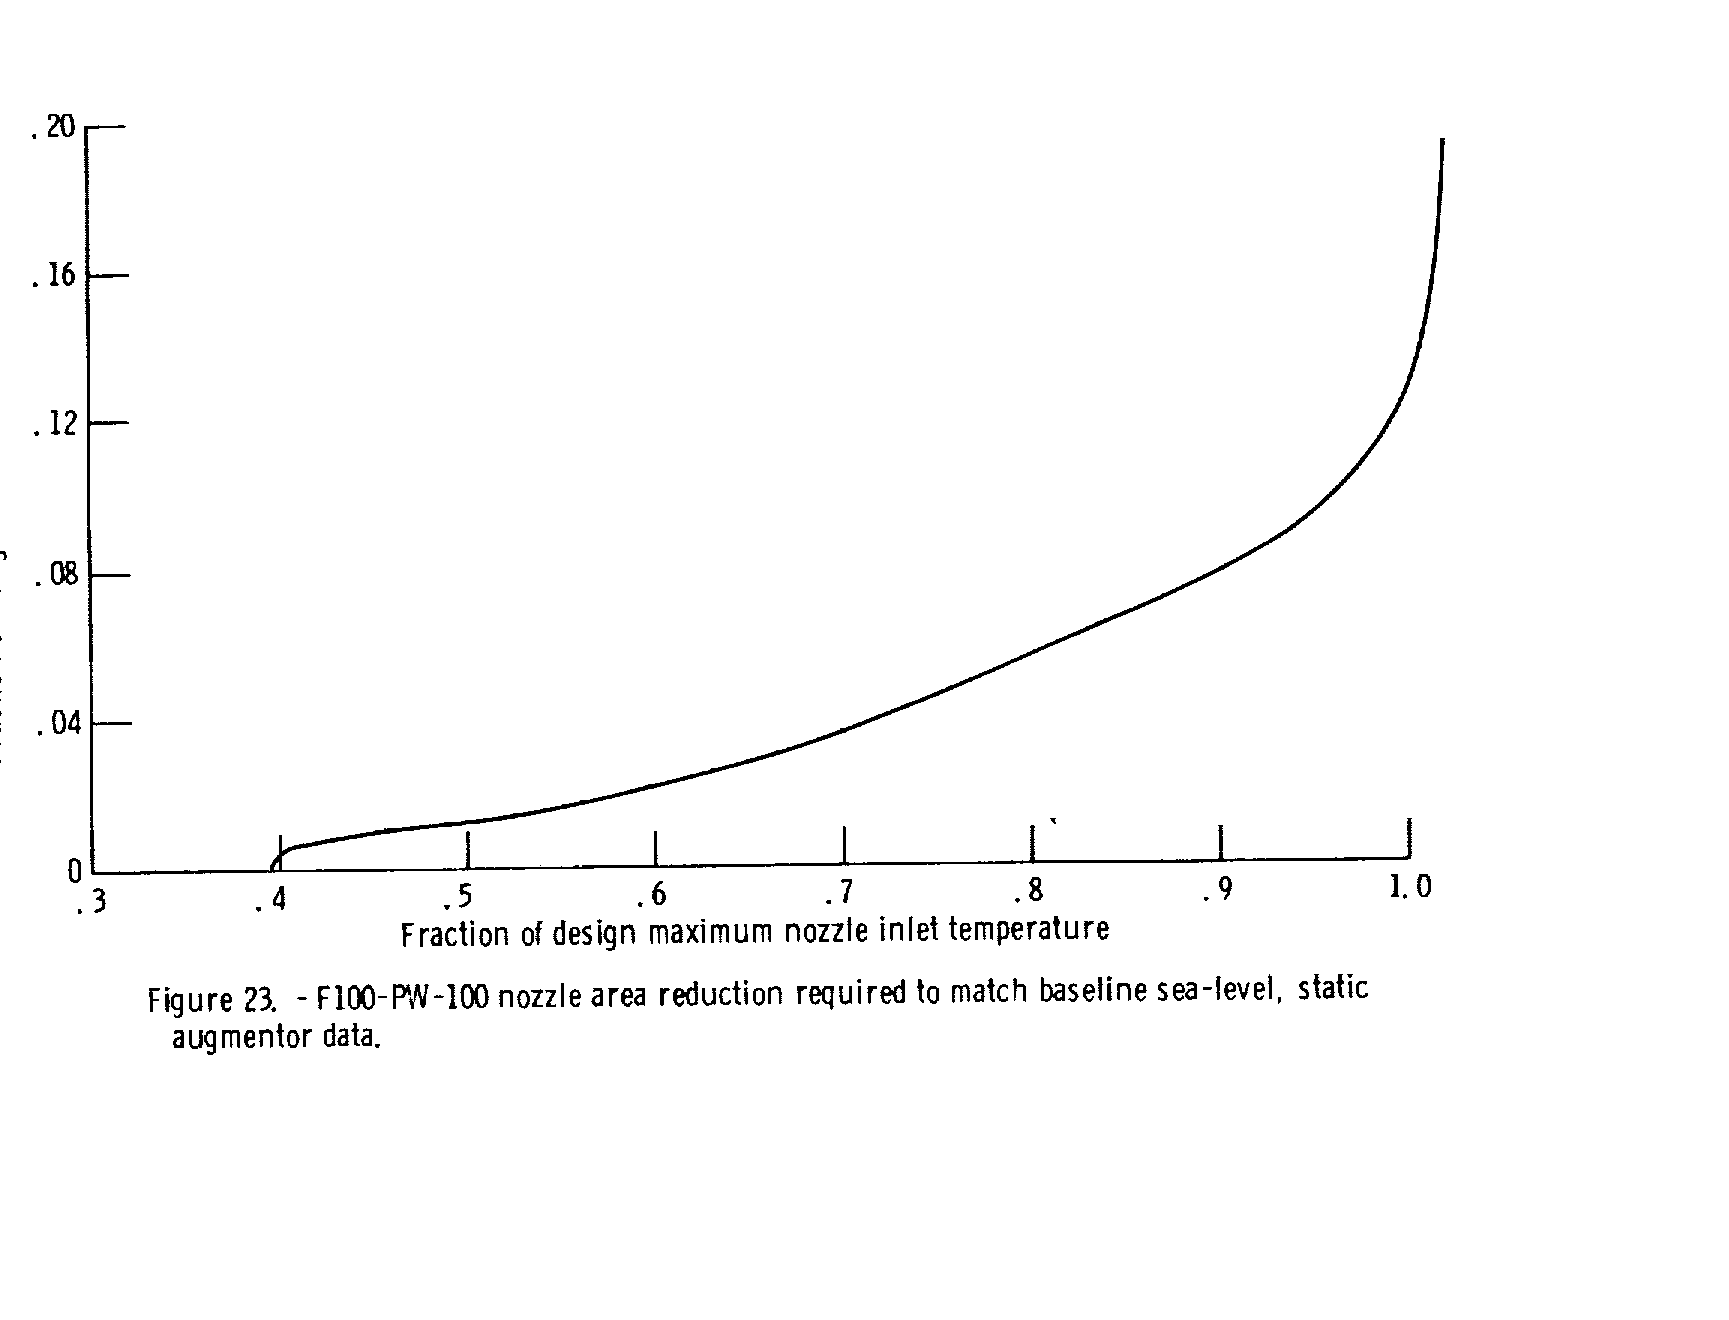

In [10]:
display(Markdown("### NASA TM X-3261 · Hybrid F100-PW-100 · Figures 1–23"))
show_source_figures("nasa-19750019996", 25)